In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/CISS_Research"

RAW_DIR = os.path.join(BASE_DIR, "raw")
EXTRACT_DIR = os.path.join(BASE_DIR, "extracted")
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
SPLIT_DIR = os.path.join(BASE_DIR, "splits")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")
FIGURE_DIR = os.path.join(BASE_DIR, "figures")

folders = [
    RAW_DIR,
    EXTRACT_DIR,
    PROCESSED_DIR,
    SPLIT_DIR,
    MODEL_DIR,
    RESULT_DIR,
    FIGURE_DIR,
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✓ Project folders created")
print("Base directory:", BASE_DIR)

✓ Project folders created
Base directory: /content/drive/MyDrive/CISS_Research


In [ ]:
import os

years = list(range(2017, 2025))

print("=" * 70)
print("CISS ZIP FILE CHECK")
print("=" * 70)

all_found = True

for year in years:

    zip_path = os.path.join(
        RAW_DIR,
        f"CISS_{year}_CSV_files.zip"
    )

    if os.path.exists(zip_path):

        size_mb = os.path.getsize(zip_path) / (1024 ** 2)

        print(
            f"✓ {year}: FOUND "
            f"({size_mb:.2f} MB)"
        )

    else:

        print(f"✗ {year}: NOT FOUND")
        all_found = False

print("=" * 70)

if all_found:
    print("✓ All 8 ZIP files found.")
else:
    print("⚠ Some ZIP files are missing.")

CISS ZIP FILE CHECK
✓ 2017: FOUND (4.33 MB)
✓ 2018: FOUND (6.53 MB)
✓ 2019: FOUND (7.02 MB)
✓ 2020: FOUND (8.69 MB)
✓ 2021: FOUND (8.84 MB)
✓ 2022: FOUND (7.51 MB)
✓ 2023: FOUND (10.44 MB)
✓ 2024: FOUND (17.64 MB)
✓ All 8 ZIP files found.


Step 4 — Extract all 8 ZIP files

In [ ]:
import zipfile
import os

for year in years:

    zip_path = os.path.join(
        RAW_DIR,
        f"CISS_{year}_CSV_files.zip"
    )

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    os.makedirs(
        year_dir,
        exist_ok=True
    )

    print(f"\nExtracting {year}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(year_dir)

    print(
        f"✓ {year} extracted to:",
        year_dir
    )

print("\n✓ ALL YEARS EXTRACTED")


Extracting 2017...
✓ 2017 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2017

Extracting 2018...
✓ 2018 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2018

Extracting 2019...
✓ 2019 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2019

Extracting 2020...
✓ 2020 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2020

Extracting 2021...
✓ 2021 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2021

Extracting 2022...
✓ 2022 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2022

Extracting 2023...
✓ 2023 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2023

Extracting 2024...
✓ 2024 extracted to: /content/drive/MyDrive/CISS_Research/extracted/2024

✓ ALL YEARS EXTRACTED


Step 5 — Find all CSV files

In [ ]:
import glob
import os

for year in years:

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    csv_files = glob.glob(
        os.path.join(
            year_dir,
            "**",
            "*.csv"
        ),
        recursive=True
    )

    print("\n" + "=" * 70)
    print(
        f"CISS {year}: "
        f"{len(csv_files)} CSV files"
    )
    print("=" * 70)

    for file in sorted(csv_files):

        print(
            os.path.basename(file)
        )


CISS 2017: 1 CSV files
CRASH.csv

CISS 2018: 0 CSV files

CISS 2019: 0 CSV files

CISS 2020: 39 CSV files
ADAPT.csv
AIRBAG.csv
AVOID.csv
CDC.csv
CHILDSEAT.csv
CRASH.csv
DISTRACT.csv
EDRCOLLECT.csv
EDREVENT.csv
EDRPOSTCRASH.csv
EDRPRECRASH.csv
EDRREST.csv
EDRSUMM.csv
EJECT.csv
EMSCARE.csv
EVENT.csv
FIRE.csv
FUEL.csv
GLAZING.csv
GV.csv
ICS.csv
INJURY.csv
INTEGRITY.csv
INTERIOR.csv
INTRUSION.csv
JKCOEFF.csv
JKWGT.csv
LOCALIZER.csv
OCC.csv
OCCONTACT.csv
PRE_FHE.csv
SEAT.csv
SEATXBAG.csv
TIRE.csv
TIREDAMAGE.csv
TIREPLAC.csv
VEHMEAS.csv
VEHSPEC.csv
VPICDECODE.csv

CISS 2021: 39 CSV files
ADAPT.csv
AIRBAG.csv
AVOID.csv
CDC.csv
CHILDSEAT.csv
CRASH.csv
DISTRACT.csv
EDRCOLLECT.csv
EDREVENT.csv
EDRPOSTCRASH.csv
EDRPRECRASH.csv
EDRREST.csv
EDRSUMM.csv
EJECT.csv
EMSCARE.csv
EVENT.csv
FIRE.csv
FUEL.csv
GLAZING.csv
GV.csv
ICS.csv
INJURY.csv
INTEGRITY.csv
INTERIOR.csv
INTRUSION.csv
JKCOEFF.csv
JKWGT.csv
LOCALIZER.csv
OCC.csv
OCCONTACT.csv
PRE_FHE.csv
SEAT.csv
SEATXBAG.csv
TIRE.csv
TIREDAMAGE.csv
TIRE

Step 6 — Build complete inventory

In [ ]:
import pandas as pd
import os
import glob

inventory = []

for year in years:

    print(f"\nProcessing {year}...")

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    csv_files = glob.glob(
        os.path.join(
            year_dir,
            "**",
            "*.csv"
        ),
        recursive=True
    )

    for file in sorted(csv_files):

        filename = os.path.basename(file)

        try:

            df = pd.read_csv(
                file,
                low_memory=False,
                encoding_errors="replace"
            )

            inventory.append({
                "year": year,
                "file": filename,
                "rows": len(df),
                "columns": len(df.columns),
                "size_mb":
                    os.path.getsize(file)
                    / (1024 ** 2)
            })

        except Exception as e:

            print(
                "ERROR:",
                year,
                filename,
                str(e)
            )

inventory_df = pd.DataFrame(inventory)

inventory_df = inventory_df.sort_values(
    ["year", "file"]
).reset_index(drop=True)

print("\n✓ Inventory complete")
print("Total CSV files:", len(inventory_df))

display(inventory_df)


Processing 2017...

Processing 2018...

Processing 2019...

Processing 2020...

Processing 2021...

Processing 2022...

Processing 2023...

Processing 2024...

✓ Inventory complete
Total CSV files: 213


,year,file,rows,columns,size_mb
0,2017,CRASH.csv,2035,24,0.672878
1,2020,ADAPT.csv,4,10,0.000293
2,2020,AIRBAG.csv,25175,31,2.388099
3,2020,AVOID.csv,37020,12,2.175703
4,2020,CDC.csv,7434,56,1.792360
...,...,...,...,...,...
208,2024,TIREDAMAGE.csv,27498,11,1.613044
209,2024,TIREPLAC.csv,6645,24,0.693297
210,2024,VEHMEAS.csv,6707,35,1.006027
211,2024,VEHSPEC.csv,8776,24,0.882915


Step 7 — Save inventory to Drive

In [ ]:
inventory_path = os.path.join(
    RESULT_DIR,
    "CISS_2017_2024_File_Inventory.csv"
)

inventory_df.to_csv(
    inventory_path,
    index=False
)

print("✓ Saved:")
print(inventory_path)

✓ Saved:
/content/drive/MyDrive/CISS_Research/results/CISS_2017_2024_File_Inventory.csv


Step 8 — Check core tables across years

In [ ]:
core_tables = [
    "CRASH",
    "GV",
    "EVENT",
    "OCC"
]

for table in core_tables:

    print("\n" + "=" * 70)
    print(table)
    print("=" * 70)

    for year in years:

        matches = inventory_df[
            (inventory_df["year"] == year)
            &
            (
                inventory_df["file"]
                .str.upper()
                .str.replace(".CSV", "", regex=False)
                == table
            )
        ]

        if len(matches) > 0:

            row = matches.iloc[0]

            print(
                f"{year}: ✓ "
                f"{row['rows']:,} rows × "
                f"{row['columns']} columns"
            )

        else:

            print(
                f"{year}: ✗ NOT FOUND"
            )


CRASH
2017: ✓ 2,035 rows × 24 columns
2018: ✗ NOT FOUND
2019: ✗ NOT FOUND
2020: ✓ 3,700 rows × 24 columns
2021: ✓ 3,331 rows × 23 columns
2022: ✓ 2,929 rows × 23 columns
2023: ✓ 3,997 rows × 22 columns
2024: ✓ 5,290 rows × 31 columns

GV
2017: ✗ NOT FOUND
2018: ✗ NOT FOUND
2019: ✗ NOT FOUND
2020: ✓ 6,405 rows × 105 columns
2021: ✓ 5,935 rows × 109 columns
2022: ✓ 5,166 rows × 109 columns
2023: ✓ 7,037 rows × 110 columns
2024: ✓ 9,212 rows × 112 columns

EVENT
2017: ✗ NOT FOUND
2018: ✗ NOT FOUND
2019: ✗ NOT FOUND
2020: ✓ 6,924 rows × 15 columns
2021: ✓ 6,575 rows × 15 columns
2022: ✓ 5,651 rows × 15 columns
2023: ✓ 7,843 rows × 15 columns
2024: ✓ 10,001 rows × 16 columns

OCC
2017: ✗ NOT FOUND
2018: ✗ NOT FOUND
2019: ✗ NOT FOUND
2020: ✓ 7,226 rows × 87 columns
2021: ✓ 6,487 rows × 87 columns
2022: ✓ 5,730 rows × 87 columns
2023: ✓ 7,833 rows × 87 columns
2024: ✓ 10,237 rows × 87 columns


Step 9 — Specifically inspect CRASH.csv

In [ ]:
def find_table(year, table_name):

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    files = glob.glob(
        os.path.join(
            year_dir,
            "**",
            "*.csv"
        ),
        recursive=True
    )

    for file in files:

        name = os.path.splitext(
            os.path.basename(file)
        )[0]

        if name.upper() == table_name.upper():
            return file

    return None

In [ ]:
crash_summary = []

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:

        print(
            f"{year}: CRASH not found"
        )

        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    cols = [
        str(c).strip().upper()
        for c in df.columns
    ]

    crash_summary.append({
        "year": year,
        "cases": len(df),
        "columns": len(df.columns),
        "summary_available":
            "SUMMARY" in cols,
        "cinjsev_available":
            "CINJSEV" in cols
    })

crash_summary_df = pd.DataFrame(
    crash_summary
)

display(crash_summary_df)

2018: CRASH not found
2019: CRASH not found


,year,cases,columns,summary_available,cinjsev_available
0,2017,2035,24,True,True
1,2020,3700,24,True,True
2,2021,3331,23,True,True
3,2022,2929,23,True,True
4,2023,3997,22,False,True
5,2024,5290,31,False,True


Step 10 — Check narrative sample counts

In [ ]:
narrative_stats = []

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    if "SUMMARY" not in df.columns:

        narrative_stats.append({
            "year": year,
            "total_cases": len(df),
            "summary_available": False,
            "non_empty_summary": 0,
            "percent_with_summary": 0
        })

        continue

    text = (
        df["SUMMARY"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    usable = (
        text.str.len() > 0
    ).sum()

    narrative_stats.append({
        "year": year,
        "total_cases": len(df),
        "summary_available": True,
        "non_empty_summary": usable,
        "percent_with_summary":
            usable / len(df) * 100
    })

narrative_stats_df = pd.DataFrame(
    narrative_stats
)

display(narrative_stats_df)

,year,total_cases,summary_available,non_empty_summary,percent_with_summary
0,2017,2035,True,2035,100.0
1,2020,3700,True,3700,100.0
2,2021,3331,True,3331,100.0
3,2022,2929,True,2929,100.0
4,2023,3997,False,0,0.0
5,2024,5290,False,0,0.0


Step 11 — Narrative length check

In [ ]:
length_records = []

for year in range(2017, 2023):

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    if "SUMMARY" not in df.columns:
        continue

    text = (
        df["SUMMARY"]
        .dropna()
        .astype(str)
        .str.strip()
    )

    text = text[
        text.str.len() > 0
    ]

    word_count = (
        text.str.split().str.len()
    )

    length_records.append({
        "year": year,
        "n": len(text),
        "mean_words":
            word_count.mean(),
        "median_words":
            word_count.median(),
        "p95_words":
            word_count.quantile(.95),
        "max_words":
            word_count.max()
    })

length_df = pd.DataFrame(
    length_records
)

display(
    length_df.round(1)
)

,year,n,mean_words,median_words,p95_words,max_words
0,2017,2035,47.2,42.0,89.0,319
1,2020,3700,69.9,65.0,123.0,206
2,2021,3331,76.4,72.0,134.0,205
3,2022,2929,74.5,69.0,126.6,205


Step 12 — এখন target distribution inspect করুন

In [ ]:
for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    print("\n" + "=" * 60)
    print("YEAR:", year)
    print("=" * 60)

    if "CINJSEV" in df.columns:

        print(
            df["CINJSEV"]
            .value_counts(
                dropna=False
            )
            .sort_index()
        )

    else:

        print(
            "CINJSEV not found"
        )


YEAR: 2017
CINJSEV
0    1820
1     180
2      31
3       3
4       1
Name: count, dtype: int64

YEAR: 2020
CINJSEV
0    3288
1     356
2      41
3      10
4       3
5       2
Name: count, dtype: int64

YEAR: 2021
CINJSEV
0    2973
1     314
2      33
3       8
4       2
5       1
Name: count, dtype: int64

YEAR: 2022
CINJSEV
0    2613
1     272
2      39
3       4
5       1
Name: count, dtype: int64

YEAR: 2023
CINJSEV
0    3525
1     404
2      54
3      12
4       1
5       1
Name: count, dtype: int64

YEAR: 2024
CINJSEV
0     4465
1      532
2       76
3       10
4        7
5        2
6        2
95     196
Name: count, dtype: int64


Step 13 — 2018/2019 check করুন

In [ ]:
for year in [2018, 2019]:

    file = find_table(year, "CRASH")

    print("\n" + "=" * 60)
    print("YEAR:", year)
    print("=" * 60)

    if file is None:
        print("CRASH.csv NOT FOUND")
        continue

    print("File:", file)

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    print("Shape:", df.shape)
    print("CINJSEV exists:", "CINJSEV" in df.columns)
    print("SUMMARY exists:", "SUMMARY" in df.columns)

    if "CINJSEV" in df.columns:
        print("\nCINJSEV distribution:")
        print(
            df["CINJSEV"]
            .value_counts(dropna=False)
            .sort_index()
        )


YEAR: 2018
CRASH.csv NOT FOUND

YEAR: 2019
CRASH.csv NOT FOUND


Step 13A — 2018 ও 2019-এর সব CSV filename দেখুন

In [ ]:
import os
import glob

for year in [2018, 2019]:

    print("\n" + "=" * 80)
    print(f"CISS {year} — ALL CSV FILES")
    print("=" * 80)

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    files = glob.glob(
        os.path.join(
            year_dir,
            "**",
            "*"
        ),
        recursive=True
    )

    csv_files = [
        f for f in files
        if f.lower().endswith(".csv")
    ]

    print("CSV files found:", len(csv_files))

    for f in sorted(csv_files):
        print(os.path.relpath(f, year_dir))


CISS 2018 — ALL CSV FILES
CSV files found: 38
ADAPT.CSV
AIRBAG.CSV
AVOID.CSV
CDC.CSV
CHILDSEAT.CSV
CRASH.CSV
DISTRACT.CSV
EDRCOLLECT.CSV
EDREVENT.CSV
EDRPOSTCRASH.CSV
EDRPRECRASH.CSV
EDRREST.CSV
EDRSUMM.CSV
EJECT.CSV
EMSCARE.CSV
EVENT.CSV
FIRE.CSV
FUEL.CSV
GLAZING.CSV
GV.CSV
ICS.CSV
INJURY.CSV
INTEGRITY.CSV
INTERIOR.CSV
INTRUSION.CSV
JKWGT.CSV
LOCALIZER.CSV
OCC.CSV
OCCONTACT.CSV
PRE_FHE.CSV
SEAT.CSV
SEATXBAG.CSV
TIRE.CSV
TIREDAMAGE.CSV
TIREPLAC.CSV
VEHSPEC.CSV
VEH_MEAS.CSV
VINDERIVED.CSV

CISS 2019 — ALL CSV FILES
CSV files found: 38
ADAPT.CSV
AIRBAG.CSV
AVOID.CSV
CDC.CSV
CHILDSEAT.CSV
CRASH.CSV
DISTRACT.CSV
EDRCOLLECT.CSV
EDREVENT.CSV
EDRPOSTCRASH.CSV
EDRPRECRASH.CSV
EDRREST.CSV
EDRSUMM.CSV
EJECT.CSV
EMSCARE.CSV
EVENT.CSV
FIRE.CSV
FUEL.CSV
GLAZING.CSV
GV.CSV
ICS.CSV
INJURY.CSV
INTEGRITY.CSV
INTERIOR.CSV
INTRUSION.CSV
JKWGT.CSV
LOCALIZER.CSV
OCC.CSV
OCCONTACT.CSV
PRE_FHE.CSV
SEAT.CSV
SEATXBAG.CSV
TIRE.CSV
TIREDAMAGE.CSV
TIREPLAC.CSV
VEHSPEC.CSV
VEH_MEAS.CSV
VINDERIVED.CSV


In [ ]:
import os
import glob

def find_table(year, table_name):

    year_dir = os.path.join(
        EXTRACT_DIR,
        str(year)
    )

    files = glob.glob(
        os.path.join(
            year_dir,
            "**",
            "*"
        ),
        recursive=True
    )

    for file in files:

        if not os.path.isfile(file):
            continue

        filename = os.path.basename(file)

        name, ext = os.path.splitext(filename)

        # Case-insensitive:
        # CRASH.csv
        # CRASH.CSV
        # crash.csv
        if (
            name.strip().upper() == table_name.strip().upper()
            and
            ext.lower() == ".csv"
        ):
            return file

    return None

Step 13C — Test all 8 years

In [ ]:
years = list(range(2017, 2025))

for year in years:

    file = find_table(year, "CRASH")

    if file:
        print(
            f"✓ {year}:",
            os.path.basename(file)
        )
    else:
        print(
            f"✗ {year}: CRASH NOT FOUND"
        )

✓ 2017: CRASH.csv
✓ 2018: CRASH.CSV
✓ 2019: CRASH.CSV
✓ 2020: CRASH.csv
✓ 2021: CRASH.csv
✓ 2022: CRASH.csv
✓ 2023: CRASH.csv
✓ 2024: CRASH.csv


Step 14 — এখন 2017–2024 target distribution আবার run করুন

In [ ]:
import pandas as pd

target_records = []

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:
        print(
            f"⚠ {year}: CRASH missing"
        )
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    if "CINJSEV" not in df.columns:
        print(
            f"⚠ {year}: CINJSEV missing"
        )
        continue

    counts = (
        df["CINJSEV"]
        .value_counts(dropna=False)
        .sort_index()
    )

    print("\n" + "=" * 60)
    print(f"YEAR: {year}")
    print("=" * 60)
    print(counts)

    for code, count in counts.items():

        target_records.append({
            "YEAR": year,
            "CINJSEV": code,
            "COUNT": count
        })


YEAR: 2017
CINJSEV
0    1820
1     180
2      31
3       3
4       1
Name: count, dtype: int64

YEAR: 2018
CINJSEV
0    2359
1     266
2      49
3       7
4       2
Name: count, dtype: int64

YEAR: 2019
CINJSEV
0    2457
1     258
2      52
3      12
4       1
8       1
Name: count, dtype: int64

YEAR: 2020
CINJSEV
0    3288
1     356
2      41
3      10
4       3
5       2
Name: count, dtype: int64

YEAR: 2021
CINJSEV
0    2973
1     314
2      33
3       8
4       2
5       1
Name: count, dtype: int64

YEAR: 2022
CINJSEV
0    2613
1     272
2      39
3       4
5       1
Name: count, dtype: int64

YEAR: 2023
CINJSEV
0    3525
1     404
2      54
3      12
4       1
5       1
Name: count, dtype: int64

YEAR: 2024
CINJSEV
0     4465
1      532
2       76
3       10
4        7
5        2
6        2
95     196
Name: count, dtype: int64


Step 15 — Overall target distribution

In [ ]:
target_distribution = pd.DataFrame(
    target_records
)

overall_target = (
    target_distribution
    .groupby("CINJSEV")["COUNT"]
    .sum()
    .reset_index()
)

overall_target["PERCENT"] = (
    overall_target["COUNT"]
    /
    overall_target["COUNT"].sum()
    * 100
)

overall_target["PERCENT"] = (
    overall_target["PERCENT"]
    .round(3)
)

print(
    "\nTOTAL CRASHES:",
    overall_target["COUNT"].sum()
)

display(overall_target)


TOTAL CRASHES: 26746


,CINJSEV,COUNT,PERCENT
0,0,23500,87.864
1,1,2582,9.654
2,2,375,1.402
3,3,66,0.247
4,4,17,0.064
5,5,7,0.026
6,6,2,0.007
7,8,1,0.004
8,95,196,0.733


Step 16 — Narrative availability পুনরায় check

In [ ]:
narrative_records = []

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    if file is None:
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    if "SUMMARY" in df.columns:

        text = (
            df["SUMMARY"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        # Very short entries বাদ
        usable = (
            text.str.len() >= 20
        )

        narrative_records.append({
            "YEAR": year,
            "TOTAL_CASES": len(df),
            "SUMMARY_EXISTS": True,
            "NON_EMPTY_SUMMARY":
                (text.str.len() > 0).sum(),
            "USABLE_SUMMARY":
                usable.sum(),
            "USABLE_PERCENT":
                round(
                    usable.mean() * 100,
                    2
                )
        })

    else:

        narrative_records.append({
            "YEAR": year,
            "TOTAL_CASES": len(df),
            "SUMMARY_EXISTS": False,
            "NON_EMPTY_SUMMARY": 0,
            "USABLE_SUMMARY": 0,
            "USABLE_PERCENT": 0
        })

narrative_check = pd.DataFrame(
    narrative_records
)

display(narrative_check)

,YEAR,TOTAL_CASES,SUMMARY_EXISTS,NON_EMPTY_SUMMARY,USABLE_SUMMARY,USABLE_PERCENT
0,2017,2035,True,2035,2035,100.0
1,2018,2683,True,2683,2683,100.0
2,2019,2781,True,2781,2781,100.0
3,2020,3700,True,3700,3700,100.0
4,2021,3331,True,3331,3331,100.0
5,2022,2929,True,2929,2929,100.0
6,2023,3997,False,0,0,0.0
7,2024,5290,False,0,0,0.0


Step 17 — খুব useful: schema comparison

In [ ]:
crash_columns = {}

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    df = pd.read_csv(
        file,
        nrows=5,
        low_memory=False,
        encoding_errors="replace"
    )

    columns = {
        str(c).strip().upper()
        for c in df.columns
    }

    crash_columns[year] = columns

    print(
        f"{year}: {len(columns)} columns"
    )

2017: 24 columns
2018: 23 columns
2019: 23 columns
2020: 24 columns
2021: 23 columns
2022: 23 columns
2023: 22 columns
2024: 31 columns


In [ ]:
common_crash_columns = set.intersection(
    *crash_columns.values()
)

print(
    "\nCommon CRASH variables:",
    len(common_crash_columns)
)

for col in sorted(
    common_crash_columns
):
    print(col)


Common CRASH variables: 22
ALCINV
CAIS
CASEID
CASENO
CASENUMBER
CASEWGT
CATEGORY
CINJSEV
CINJURED
CISS
CRASHMONTH
CRASHTIME
CRASHYEAR
CTREAT
DAYOFWEEK
DRGINV
EVENTS
MANCOLL
PSU
PSUSTRAT
VEHICLES
VERSION


তারপর year-specific difference:

In [ ]:
for year in years:

    extra = (
        crash_columns[year]
        - common_crash_columns
    )

    print("\n" + "=" * 60)
    print(
        f"{year} additional variables:",
        len(extra)
    )
    print("=" * 60)

    print(
        sorted(extra)
    )


2017 additional variables: 2
['CONFIG', 'SUMMARY']

2018 additional variables: 1
['SUMMARY']

2019 additional variables: 1
['SUMMARY']

2020 additional variables: 2
['PANDEMIC', 'SUMMARY']

2021 additional variables: 1
['SUMMARY']

2022 additional variables: 1
['SUMMARY']

2023 additional variables: 0
[]

2024 additional variables: 9
['CNMAIS', 'CNMINJSEV', 'CNMINJURED', 'CNMISS', 'CNMTREAT', 'NM', 'NMALCINV', 'NMDRGINV', 'PV']


Step 18 — সব common CRASH variables-এর value distribution বের করুন
এই code run করুন। এতে variables কী represent করছে তা বোঝা এবং suspicious outcome variables আলাদা করা সহজ হবে।

In [ ]:
import pandas as pd
import os

COMMON_COLS = sorted(common_crash_columns)

for col in COMMON_COLS:

    print("\n" + "=" * 80)
    print("VARIABLE:", col)
    print("=" * 80)

    combined = []

    for year in years:

        file = find_table(year, "CRASH")

        if file is None:
            continue

        df = pd.read_csv(
            file,
            low_memory=False,
            encoding_errors="replace"
        )

        df.columns = [
            str(c).strip().upper()
            for c in df.columns
        ]

        if col not in df.columns:
            continue

        temp = pd.DataFrame({
            "YEAR": year,
            "VALUE": df[col]
        })

        combined.append(temp)

    if not combined:
        continue

    temp = pd.concat(
        combined,
        ignore_index=True
    )

    print(
        temp["VALUE"]
        .value_counts(dropna=False)
        .head(20)
    )


VARIABLE: ALCINV
VALUE
2    17499
9     6420
1     2827
Name: count, dtype: int64

VARIABLE: CAIS
VALUE
0     8229
1     8093
2     2647
99    2369
9     2281
3     1875
4      496
5      359
6      201
95     196
Name: count, dtype: int64

VARIABLE: CASEID
VALUE
2406391    1
6035       1
6042       1
6045       1
6050       1
6054       1
6062       1
6068       1
6085       1
6092       1
6093       1
6095       1
6101       1
6103       1
6104       1
6105       1
6106       1
6110       1
6111       1
6112       1
Name: count, dtype: int64

VARIABLE: CASENO
VALUE
23    234
26    233
29    233
18    232
19    231
1     230
2     230
6     229
24    228
4     228
13    228
34    228
10    227
16    227
25    227
8     227
14    226
20    226
22    226
7     225
Name: count, dtype: int64

VARIABLE: CASENUMBER
VALUE
1-22-2024-194-NM1    1
1-23-2017-001-04     1
1-32-2017-001-09     1
1-17-2017-001-10     1
1-13-2017-001-04     1
1-20-2017-001-10     1
1-16-2017-001-10     1
1-19-2017-

Step 19 — প্রথম leakage-safe CRASH feature set
এখনই final না, কিন্তু modelling perspective থেকে CRASH table-কে দুই ভাগ করুন।

In [ ]:
CRASH_CANDIDATE_FEATURES = [
    "CRASHMONTH",
    "CRASHTIME",
    "DAYOFWEEK",
    "MANCOLL",
    "VEHICLES",
    "EVENTS",
]

অন্যদিকে আপাতত predictor হিসেবে hold out করুন:

In [ ]:
CRASH_HOLDOUT = [
    "CAIS",
    "CINJSEV",
    "CINJURED",
    "CTREAT",
    "ALCINV",
    "DRGINV",
]

Identifiers/design variables:

In [ ]:
CRASH_ID_DESIGN = [
    "CASEID",
    "CASENO",
    "CASENUMBER",
    "CASEWGT",
    "CISS",
    "PSU",
    "PSUSTRAT",
    "VERSION",
    "CATEGORY",
]

Step 20 — GV এবং EVENT schema audit

In [ ]:
tables_to_check = [
    "GV",
    "EVENT",
    "OCC"
]

table_common_columns = {}

for table in tables_to_check:

    print("\n" + "#" * 90)
    print("TABLE:", table)
    print("#" * 90)

    year_columns = {}

    for year in years:

        file = find_table(
            year,
            table
        )

        if file is None:

            print(
                f"{year}: NOT FOUND"
            )

            continue

        df = pd.read_csv(
            file,
            nrows=5,
            low_memory=False,
            encoding_errors="replace"
        )

        cols = {
            str(c).strip().upper()
            for c in df.columns
        }

        year_columns[year] = cols

        print(
            f"{year}: "
            f"{len(cols)} columns"
        )

    if len(year_columns) == len(years):

        common = set.intersection(
            *year_columns.values()
        )

        table_common_columns[table] = common

        print(
            f"\nCommon {table} columns:",
            len(common)
        )

        print(
            sorted(common)
        )

    else:

        print(
            "\n⚠ Table not available "
            "for every year."
        )


##########################################################################################
TABLE: GV
##########################################################################################
2017: 97 columns
2018: 104 columns
2019: 105 columns
2020: 105 columns
2021: 109 columns
2022: 109 columns
2023: 110 columns
2024: 112 columns

Common GV columns: 95
['ALCTEST', 'ALCTESTRESULT', 'ALCTESTSRC', 'ALIGNMENT', 'BODYCAT', 'BODYTYPE', 'CARGOSRC', 'CARGOWT', 'CASEID', 'CASENO', 'CASENUMBER', 'CASEWGT', 'CATEGORY', 'CRASHCAT', 'CRASHCONF', 'CRASHTYPE', 'CRITCAT', 'CRITEVENT', 'CURBSRC', 'CURBWT', 'DAMPLANE', 'DAMSEV', 'DISTRACT', 'DRPRESENT', 'DRUGTEST', 'DVANGOTH', 'DVANGTHIS', 'DVBASIS', 'DVBES', 'DVCONF', 'DVENERGY', 'DVEST', 'DVEVENT', 'DVLAT', 'DVLONG', 'DVMOMENT', 'DVSPEED', 'DVTOTAL', 'ETHNICITY', 'HEADANGLECAT', 'INITLANE', 'INITOBJCLASS', 'INSPTYPE', 'LIGHTCOND', 'LINELEFT', 'LINERIGHT', 'MAKE', 'MANEUVER', 'MODEL', 'MODELYR', 'PARALCOHOL', 'PARDRUG', 'PREFHE', 'PRELOC', 'PREMOVE

Step 21 — Row counts-ও দেখুন

In [ ]:
for table in [
    "CRASH",
    "GV",
    "EVENT",
    "OCC"
]:

    print("\n" + "=" * 75)
    print(table)
    print("=" * 75)

    for year in years:

        file = find_table(
            year,
            table
        )

        if file is None:
            print(
                f"{year}: NOT FOUND"
            )
            continue

        df = pd.read_csv(
            file,
            low_memory=False,
            encoding_errors="replace"
        )

        print(
            f"{year}: "
            f"{len(df):,} rows × "
            f"{len(df.columns)} columns"
        )


CRASH
2017: 2,035 rows × 24 columns
2018: 2,683 rows × 23 columns
2019: 2,781 rows × 23 columns
2020: 3,700 rows × 24 columns
2021: 3,331 rows × 23 columns
2022: 2,929 rows × 23 columns
2023: 3,997 rows × 22 columns
2024: 5,290 rows × 31 columns

GV
2017: 3,748 rows × 97 columns
2018: 4,848 rows × 104 columns
2019: 4,982 rows × 105 columns
2020: 6,405 rows × 105 columns
2021: 5,935 rows × 109 columns
2022: 5,166 rows × 109 columns
2023: 7,037 rows × 110 columns
2024: 9,212 rows × 112 columns

EVENT
2017: 3,560 rows × 15 columns
2018: 4,891 rows × 15 columns
2019: 5,231 rows × 15 columns
2020: 6,924 rows × 15 columns
2021: 6,575 rows × 15 columns
2022: 5,651 rows × 15 columns
2023: 7,843 rows × 15 columns
2024: 10,001 rows × 16 columns

OCC
2017: 4,235 rows × 87 columns
2018: 5,554 rows × 87 columns
2019: 5,641 rows × 87 columns
2020: 7,226 rows × 87 columns
2021: 6,487 rows × 87 columns
2022: 5,730 rows × 87 columns
2023: 7,833 rows × 87 columns
2024: 10,237 rows × 87 columns


Step 22 — Case ID relationship verify করুন

In [ ]:
for table in [
    "GV",
    "EVENT",
    "OCC"
]:

    print("\n" + "=" * 70)
    print(
        "CRASH vs",
        table
    )
    print("=" * 70)

    common_keys = (
        crash_columns[2017]
        &
        table_common_columns.get(
            table,
            set()
        )
    )

    possible_keys = [
        x for x in sorted(common_keys)
        if (
            "CASE" in x
            or "VEH" in x
            or "OCC" in x
            or "EVENT" in x
        )
    ]

    print(
        possible_keys
    )


CRASH vs GV
['CASEID', 'CASENO', 'CASENUMBER', 'CASEWGT']

CRASH vs EVENT
['CASEID', 'CASENO', 'CASENUMBER', 'CASEWGT']

CRASH vs OCC
['CASEID', 'CASENO', 'CASENUMBER', 'CASEWGT']


তারপর 2022 example দিয়ে key uniqueness দেখুন:

In [ ]:
for table in [
    "CRASH",
    "GV",
    "EVENT",
    "OCC"
]:

    file = find_table(
        2022,
        table
    )

    if file is None:
        continue

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    print("\n", table)
    print("-" * 50)

    for col in [
        "CASEID",
        "CASENO",
        "CASENUMBER"
    ]:

        if col in df.columns:

            print(
                col,
                "rows =",
                len(df),
                "| unique =",
                df[col].nunique(
                    dropna=False
                )
            )


 CRASH
--------------------------------------------------
CASEID rows = 2929 | unique = 2929
CASENO rows = 2929 | unique = 222
CASENUMBER rows = 2929 | unique = 2929

 GV
--------------------------------------------------
CASEID rows = 5166 | unique = 2929
CASENO rows = 5166 | unique = 222
CASENUMBER rows = 5166 | unique = 2929

 EVENT
--------------------------------------------------
CASEID rows = 5651 | unique = 2929
CASENO rows = 5651 | unique = 222
CASENUMBER rows = 5651 | unique = 2929

 OCC
--------------------------------------------------
CASEID rows = 5730 | unique = 2925
CASENO rows = 5730 | unique = 222
CASENUMBER rows = 5730 | unique = 2925


Step 23 — CASEID integrity check, all 8 years

In [ ]:
integrity_records = []

for year in years:

    crash_file = find_table(year, "CRASH")

    crash = pd.read_csv(
        crash_file,
        low_memory=False,
        encoding_errors="replace"
    )

    crash.columns = [
        str(c).strip().upper()
        for c in crash.columns
    ]

    crash_ids = set(
        crash["CASEID"].dropna()
    )

    for table in ["CRASH", "GV", "EVENT", "OCC"]:

        file = find_table(year, table)

        df = pd.read_csv(
            file,
            low_memory=False,
            encoding_errors="replace"
        )

        df.columns = [
            str(c).strip().upper()
            for c in df.columns
        ]

        ids = set(
            df["CASEID"].dropna()
        )

        integrity_records.append({
            "YEAR": year,
            "TABLE": table,
            "ROWS": len(df),
            "UNIQUE_CASEID":
                df["CASEID"].nunique(),
            "DUPLICATE_CASE_ROWS":
                len(df)
                - df["CASEID"].nunique(),
            "CASES_NOT_IN_CRASH":
                len(ids - crash_ids),
            "CRASH_CASES_MISSING":
                len(crash_ids - ids)
        })

integrity_df = pd.DataFrame(
    integrity_records
)

display(integrity_df)

,YEAR,TABLE,ROWS,UNIQUE_CASEID,DUPLICATE_CASE_ROWS,CASES_NOT_IN_CRASH,CRASH_CASES_MISSING
0,2017,CRASH,2035,2035,0,0,0
1,2017,GV,3748,2035,1713,0,0
2,2017,EVENT,3560,2035,1525,0,0
3,2017,OCC,4235,2034,2201,0,1
4,2018,CRASH,2683,2683,0,0,0
5,2018,GV,4848,2683,2165,0,0
6,2018,EVENT,4891,2683,2208,0,0
7,2018,OCC,5554,2680,2874,0,3
8,2019,CRASH,2781,2781,0,0,0
9,2019,GV,4982,2781,2201,0,0


Step 24 — Check CASEID uniqueness across years

In [ ]:
caseid_year = []

for year in years:

    file = find_table(
        year,
        "CRASH"
    )

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding_errors="replace"
    )

    df.columns = [
        str(c).strip().upper()
        for c in df.columns
    ]

    temp = df[
        ["CASEID"]
    ].copy()

    temp["YEAR"] = year

    caseid_year.append(temp)

caseid_year = pd.concat(
    caseid_year,
    ignore_index=True
)

caseid_repeat = (
    caseid_year
    .groupby("CASEID")["YEAR"]
    .nunique()
)

repeated_across_years = (
    caseid_repeat > 1
).sum()

print(
    "CASEIDs appearing in multiple years:",
    repeated_across_years
)

if repeated_across_years > 0:

    repeated_ids = (
        caseid_repeat[
            caseid_repeat > 1
        ]
        .index
    )

    display(
        caseid_year[
            caseid_year["CASEID"]
            .isin(repeated_ids)
        ]
        .sort_values(
            ["CASEID", "YEAR"]
        )
        .head(50)
    )

CASEIDs appearing in multiple years: 0


Step 25 — GV feature selection

In [ ]:
GV_CANDIDATES = [
    "BODYCAT",
    "BODYTYPE",
    "CRASHCAT",
    "CRASHTYPE",
    "CRITCAT",
    "CRITEVENT",

    "DRPRESENT",

    "INITLANE",
    "LIGHTCOND",

    "MANEUVER",

    "PREFHE",
    "PRELOC",
    "PREMOVE",
    "PRESTAB",

    "RDLANES",

    "SPECUSE",
    "SPEEDLIMIT",

    "SURFCOND",
    "SURFTYPE",

    "TRAFDEV",
    "TRAFFLOW",
    "TRAFFUNCT",

    "TRANSTAT",

    "VEHCLASS",

    "WEATHER"
]

Step 26 — Candidate GV variables inspect করুন

In [ ]:
for col in GV_CANDIDATES:

    print("\n" + "=" * 80)
    print("GV VARIABLE:", col)
    print("=" * 80)

    values = []

    for year in years:

        file = find_table(
            year,
            "GV"
        )

        gv = pd.read_csv(
            file,
            usecols=lambda x:
                str(x).strip().upper()
                in {"CASEID", col},
            low_memory=False,
            encoding_errors="replace"
        )

        gv.columns = [
            str(c).strip().upper()
            for c in gv.columns
        ]

        if col not in gv.columns:
            continue

        temp = gv[
            [col]
        ].copy()

        temp["YEAR"] = year

        values.append(temp)

    values = pd.concat(
        values,
        ignore_index=True
    )

    print(
        values[col]
        .value_counts(
            dropna=False
        )
        .head(15)
    )


GV VARIABLE: BODYCAT
BODYCAT
1     23278
3     13033
5      6870
4      1923
8      1789
10      162
6        92
9        91
7        84
2        10
11        1
Name: count, dtype: int64

GV VARIABLE: BODYTYPE
BODYTYPE
4     16685
14     9937
34     6816
15     2914
6      2611
5      1766
20     1428
2      1334
66      849
21      460
3       361
1       280
61      247
9       223
63      218
Name: count, dtype: int64

GV VARIABLE: CRASHCAT
CRASHCAT
2.0    10872
4.0    10862
1.0    10506
5.0     6709
6.0     4405
3.0     2716
NaN     1263
Name: count, dtype: int64

GV VARIABLE: CRASHTYPE
CRASHTYPE
98.0    4201
1.0     2723
69.0    2567
68.0    2567
20.0    1966
6.0     1885
21.0    1715
82.0    1709
83.0    1707
87.0    1688
86.0    1688
89.0    1593
88.0    1592
28.0    1492
13.0    1449
Name: count, dtype: int64

GV VARIABLE: CRITCAT
CRITCAT
2.0    17660
4.0    12826
3.0    10649
1.0     2809
6.0     1702
NaN     1263
5.0      255
8.0      139
9.0       30
Name: count, dtype: int

Step 27 — GV → crash-level aggregation

In [ ]:
def aggregate_categories(series):

    values = (
        series
        .dropna()
        .astype(str)
        .str.strip()
    )

    values = values[
        values != ""
    ]

    if len(values) == 0:
        return "MISSING"

    unique_values = sorted(
        values.unique()
    )

    return "|".join(
        unique_values
    )

In [ ]:
gv_file = find_table(
    2022,
    "GV"
)

gv = pd.read_csv(
    gv_file,
    low_memory=False,
    encoding_errors="replace"
)

gv.columns = [
    str(c).strip().upper()
    for c in gv.columns
]

available_features = [
    x for x in GV_CANDIDATES
    if x in gv.columns
]

gv_selected = gv[
    ["CASEID", "VEHNO"]
    + available_features
].copy()

In [ ]:
vehicle_count = (
    gv_selected
    .groupby("CASEID")
    .size()
    .rename("GV_VEHICLE_COUNT")
)

In [ ]:
gv_agg = (
    gv_selected
    .groupby("CASEID")[
        available_features
    ]
    .agg(aggregate_categories)
)

gv_agg.columns = [
    "GV_" + c
    for c in gv_agg.columns
]

gv_agg = (
    gv_agg
    .join(vehicle_count)
    .reset_index()
)

print(
    "Aggregated crashes:",
    len(gv_agg)
)

display(
    gv_agg.head()
)

Aggregated crashes: 2929


,CASEID,GV_BODYCAT,GV_BODYTYPE,GV_CRASHCAT,GV_CRASHTYPE,GV_CRITCAT,GV_CRITEVENT,GV_DRPRESENT,GV_INITLANE,GV_LIGHTCOND,...,GV_SPEEDLIMIT,GV_SURFCOND,GV_SURFTYPE,GV_TRAFDEV,GV_TRAFFLOW,GV_TRAFFUNCT,GV_TRANSTAT,GV_VEHCLASS,GV_WEATHER,GV_VEHICLE_COUNT
0,24415,1,4,1.0,7.0,1.0,6.0,1.0,3.0,1.0,...,113.0,2.0,2.0,0.0,2.0,0.0,1,3,2.0,1
1,24419,1|3,14|6,1.0,11.0,2.0,11.0,1.0,1.0,3.0,...,48.0,2.0,2.0,0.0,4.0,0.0,1|2,14|2,8.0,2
2,24423,1,4,2.0,20.0|21.0,3.0,50.0|53.0,1.0,1.0,1.0,...,56.0,1.0,2.0,1.0,4.0,2.0,1,4,8.0,2
3,24425,1,5,1.0,2.0,1.0,8.0,1.0,1.0,1.0,...,72.0,2.0,2.0,6.0,4.0,2.0,1,2,1.0,1
4,24429,5,34,1.0,7.0,1.0,9.0,1.0,1.0,1.0,...,56.0,1.0,2.0,0.0,4.0,0.0,1,31,1.0,1


Step 28 — EVENT aggregation

In [ ]:
EVENT_CANDIDATES = [
    "CLASS1",
    "CLASS2",
    "OBJCONT",
    "GAD1",
    "GAD2"
]

event_file = find_table(
    2022,
    "EVENT"
)

event = pd.read_csv(
    event_file,
    low_memory=False,
    encoding_errors="replace"
)

event.columns = [
    str(c).strip().upper()
    for c in event.columns
]

event_features = [
    c for c in EVENT_CANDIDATES
    if c in event.columns
]

event_count = (
    event
    .groupby("CASEID")
    .size()
    .rename("EVENT_COUNT")
)

event_agg = (
    event
    .groupby("CASEID")[
        event_features
    ]
    .agg(aggregate_categories)
)

event_agg.columns = [
    "EVENT_" + c
    for c in event_agg.columns
]

event_agg = (
    event_agg
    .join(event_count)
    .reset_index()
)

print(
    "Aggregated EVENT crashes:",
    len(event_agg)
)

display(
    event_agg.head()
)

Aggregated EVENT crashes: 2929


,CASEID,EVENT_CLASS1,EVENT_CLASS2,EVENT_OBJCONT,EVENT_GAD1,EVENT_GAD2,EVENT_COUNT
0,24415,3,0,47,F,0,1
1,24419,2,14,2,F,B,1
2,24423,4,4,2,F,B,1
3,24425,2,0,42|44,F|L,0,2
4,24429,31,0,44|60,F|R,0,2


Step 29 — 2022 trial merge

In [ ]:
crash_file = find_table(
    2022,
    "CRASH"
)

crash = pd.read_csv(
    crash_file,
    low_memory=False,
    encoding_errors="replace"
)

crash.columns = [
    str(c).strip().upper()
    for c in crash.columns
]

crash_base = crash[
    [
        "CASEID",
        "CRASHYEAR",
        "CRASHMONTH",
        "CRASHTIME",
        "DAYOFWEEK",
        "MANCOLL",
        "VEHICLES",
        "EVENTS",
        "CINJSEV",
        "SUMMARY"
    ]
].copy()

In [ ]:
master_2022 = (
    crash_base
    .merge(
        gv_agg,
        on="CASEID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        event_agg,
        on="CASEID",
        how="left",
        validate="one_to_one"
    )
)

print(
    "CRASH rows:",
    len(crash_base)
)

print(
    "MASTER rows:",
    len(master_2022)
)

print(
    "Columns:",
    len(master_2022.columns)
)

print(
    "Unique CASEID:",
    master_2022["CASEID"].nunique()
)

print(
    "Duplicate CASEID:",
    master_2022["CASEID"].duplicated().sum()
)

display(
    master_2022.head()
)

CRASH rows: 2929
MASTER rows: 2929
Columns: 42
Unique CASEID: 2929
Duplicate CASEID: 0


,CASEID,CRASHYEAR,CRASHMONTH,CRASHTIME,DAYOFWEEK,MANCOLL,VEHICLES,EVENTS,CINJSEV,SUMMARY,...,GV_TRANSTAT,GV_VEHCLASS,GV_WEATHER,GV_VEHICLE_COUNT,EVENT_CLASS1,EVENT_CLASS2,EVENT_OBJCONT,EVENT_GAD1,EVENT_GAD2,EVENT_COUNT
0,25540,2022,4,07:50,3,4,2,4,0,V1 was traveling southbound on lane 1 of a 2 l...,...,1,3|4,1.0,2,3|4,0|4,2|51|60,F|L|R,0|F|L,4
1,25541,2022,4,17:01,4,4,2,1,0,"V1 was traveling east on a three lane, undivid...",...,1,14|5,2.0,2,14,5,2,F,R,1
2,25543,2022,4,10:04,3,0,1,1,0,V1 was traveling southwest in lane one of a tw...,...,1,4,1.0,1,4,0,42,F,0,1
3,25544,2022,4,20:05,5,4,2,2,0,V1 was traveling northeast in lane one of a th...,...,1,3,1.0,2,3,3,2,F,L,2
4,25701,2022,4,21:42,6,1,2,1,0,V2 was stopped in traffic southbound in lane t...,...,1,14|3,2.0,2,14,3,2,F,B,1


Step 30 — Final 2017–2024 master dataset তৈরি
আগের GV_CANDIDATES, EVENT_CANDIDATES, aggregate_categories(), find_table() functions 그대로 থাকবে।

In [ ]:
import os
import pandas as pd
import numpy as np


def build_year_master(year):

    print("\n" + "=" * 80)
    print(f"BUILDING CISS {year}")
    print("=" * 80)

    # -------------------------------------------------
    # 1. CRASH
    # -------------------------------------------------

    crash_file = find_table(year, "CRASH")

    crash = pd.read_csv(
        crash_file,
        low_memory=False,
        encoding_errors="replace"
    )

    crash.columns = [
        str(c).strip().upper()
        for c in crash.columns
    ]

    crash_features = [
        "CASEID",
        "CRASHYEAR",
        "CRASHMONTH",
        "CRASHTIME",
        "DAYOFWEEK",
        "MANCOLL",
        "VEHICLES",
        "EVENTS",
        "CINJSEV"
    ]

    # Narrative only when available
    if "SUMMARY" in crash.columns:
        crash_features.append("SUMMARY")

    crash_base = crash[
        crash_features
    ].copy()

    # Add year explicitly
    crash_base["YEAR"] = year

    # Global unique ID
    crash_base["YEAR_CASEID"] = (
        crash_base["YEAR"].astype(str)
        + "_"
        + crash_base["CASEID"].astype(str)
    )

    # Narrative availability
    if "SUMMARY" in crash_base.columns:

        crash_base["HAS_NARRATIVE"] = (
            crash_base["SUMMARY"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.len()
            >= 20
        ).astype(int)

    else:

        crash_base["SUMMARY"] = np.nan
        crash_base["HAS_NARRATIVE"] = 0


    # -------------------------------------------------
    # 2. GV
    # -------------------------------------------------

    gv_file = find_table(year, "GV")

    gv = pd.read_csv(
        gv_file,
        low_memory=False,
        encoding_errors="replace"
    )

    gv.columns = [
        str(c).strip().upper()
        for c in gv.columns
    ]

    gv_features = [
        c for c in GV_CANDIDATES
        if c in gv.columns
    ]

    gv_selected = gv[
        ["CASEID"] + gv_features
    ].copy()

    vehicle_count = (
        gv_selected
        .groupby("CASEID")
        .size()
        .rename("GV_VEHICLE_COUNT")
    )

    gv_agg = (
        gv_selected
        .groupby("CASEID")[
            gv_features
        ]
        .agg(aggregate_categories)
    )

    gv_agg.columns = [
        "GV_" + c
        for c in gv_agg.columns
    ]

    gv_agg = (
        gv_agg
        .join(vehicle_count)
        .reset_index()
    )


    # -------------------------------------------------
    # 3. EVENT
    # -------------------------------------------------

    event_file = find_table(year, "EVENT")

    event = pd.read_csv(
        event_file,
        low_memory=False,
        encoding_errors="replace"
    )

    event.columns = [
        str(c).strip().upper()
        for c in event.columns
    ]

    event_features = [
        c for c in EVENT_CANDIDATES
        if c in event.columns
    ]

    event_count = (
        event
        .groupby("CASEID")
        .size()
        .rename("EVENT_COUNT")
    )

    event_agg = (
        event
        .groupby("CASEID")[
            event_features
        ]
        .agg(aggregate_categories)
    )

    event_agg.columns = [
        "EVENT_" + c
        for c in event_agg.columns
    ]

    event_agg = (
        event_agg
        .join(event_count)
        .reset_index()
    )


    # -------------------------------------------------
    # 4. Merge
    # -------------------------------------------------

    master = (
        crash_base
        .merge(
            gv_agg,
            on="CASEID",
            how="left",
            validate="one_to_one"
        )
        .merge(
            event_agg,
            on="CASEID",
            how="left",
            validate="one_to_one"
        )
    )


    # -------------------------------------------------
    # 5. Integrity checks
    # -------------------------------------------------

    assert len(master) == len(crash), (
        f"{year}: Row count changed!"
    )

    assert master["CASEID"].nunique() == len(master), (
        f"{year}: CASEID duplicate!"
    )

    assert master["YEAR_CASEID"].nunique() == len(master), (
        f"{year}: YEAR_CASEID duplicate!"
    )

    print("CRASH:", len(crash))
    print("MASTER:", len(master))
    print("Columns:", len(master.columns))
    print(
        "Narratives:",
        master["HAS_NARRATIVE"].sum()
    )

    return master

Step 31 — Build all 8 years

In [ ]:
all_year_masters = []

for year in years:

    master_year = build_year_master(
        year
    )

    all_year_masters.append(
        master_year
    )


BUILDING CISS 2017
CRASH: 2035
MASTER: 2035
Columns: 45
Narratives: 2035

BUILDING CISS 2018
CRASH: 2683
MASTER: 2683
Columns: 45
Narratives: 2683

BUILDING CISS 2019
CRASH: 2781
MASTER: 2781
Columns: 45
Narratives: 2781

BUILDING CISS 2020
CRASH: 3700
MASTER: 3700
Columns: 45
Narratives: 3700

BUILDING CISS 2021
CRASH: 3331
MASTER: 3331
Columns: 45
Narratives: 3331

BUILDING CISS 2022
CRASH: 2929
MASTER: 2929
Columns: 45
Narratives: 2929

BUILDING CISS 2023
CRASH: 3997
MASTER: 3997
Columns: 45
Narratives: 0

BUILDING CISS 2024
CRASH: 5290
MASTER: 5290
Columns: 45
Narratives: 0


In [ ]:
master_all = pd.concat(
    all_year_masters,
    ignore_index=True,
    sort=False
)

print("\n" + "=" * 80)
print("FINAL MASTER DATASET")
print("=" * 80)

print(
    "Rows:",
    f"{len(master_all):,}"
)

print(
    "Columns:",
    len(master_all.columns)
)

print(
    "Unique YEAR_CASEID:",
    master_all["YEAR_CASEID"].nunique()
)

print(
    "Duplicates:",
    master_all["YEAR_CASEID"]
    .duplicated()
    .sum()
)


FINAL MASTER DATASET
Rows: 26,746
Columns: 45
Unique YEAR_CASEID: 26746
Duplicates: 0


Step 32 — Year-wise final verification

In [ ]:
year_check = (
    master_all
    .groupby("YEAR")
    .agg(
        CASES=("YEAR_CASEID", "count"),
        UNIQUE_CASES=("YEAR_CASEID", "nunique"),
        NARRATIVES=("HAS_NARRATIVE", "sum")
    )
    .reset_index()
)

year_check["NARRATIVE_PERCENT"] = (
    year_check["NARRATIVES"]
    /
    year_check["CASES"]
    * 100
).round(2)

display(year_check)

,YEAR,CASES,UNIQUE_CASES,NARRATIVES,NARRATIVE_PERCENT
0,2017,2035,2035,2035,100.0
1,2018,2683,2683,2683,100.0
2,2019,2781,2781,2781,100.0
3,2020,3700,3700,3700,100.0
4,2021,3331,3331,3331,100.0
5,2022,2929,2929,2929,100.0
6,2023,3997,3997,0,0.0
7,2024,5290,5290,0,0.0


Step 33 — Missingness check

In [ ]:
missing_report = pd.DataFrame({
    "COLUMN": master_all.columns,
    "MISSING_COUNT": [
        master_all[c].isna().sum()
        for c in master_all.columns
    ],
    "MISSING_PERCENT": [
        master_all[c].isna().mean() * 100
        for c in master_all.columns
    ]
})

missing_report["MISSING_PERCENT"] = (
    missing_report["MISSING_PERCENT"]
    .round(2)
)

missing_report = (
    missing_report
    .sort_values(
        "MISSING_PERCENT",
        ascending=False
    )
    .reset_index(drop=True)
)

display(missing_report)

,COLUMN,MISSING_COUNT,MISSING_PERCENT
0,SUMMARY,9287,34.72
1,CRASHYEAR,0,0.00
2,CRASHMONTH,0,0.00
3,CRASHTIME,0,0.00
4,CASEID,0,0.00
5,DAYOFWEEK,0,0.00
6,MANCOLL,0,0.00
7,EVENTS,0,0.00
8,VEHICLES,0,0.00
9,CINJSEV,0,0.00


Step 34 — Save RAW-HARMONIZED master

In [ ]:
MASTER_PATH = os.path.join(
    PROCESSED_DIR,
    "CISS_Master_RawHarmonized_2017_2024.csv"
)

master_all.to_csv(
    MASTER_PATH,
    index=False
)

print("✓ Saved:")
print(MASTER_PATH)

✓ Saved:
/content/drive/MyDrive/CISS_Research/processed/CISS_Master_RawHarmonized_2017_2024.csv


Step 35 — Three research datasets তৈরি A. Structured dataset — 2017–2024

In [ ]:
structured_df = master_all.drop(
    columns=["SUMMARY"],
    errors="ignore"
).copy()

STRUCTURED_PATH = os.path.join(
    PROCESSED_DIR,
    "CISS_Structured_2017_2024.csv"
)

structured_df.to_csv(
    STRUCTURED_PATH,
    index=False
)

print(
    "Structured:",
    structured_df.shape
)

Structured: (26746, 44)


B. Narrative dataset — 2017–2022

In [ ]:
narrative_df = master_all[
    master_all["HAS_NARRATIVE"] == 1
][
    [
        "YEAR_CASEID",
        "CASEID",
        "YEAR",
        "SUMMARY",
        "CINJSEV"
    ]
].copy()

NARRATIVE_PATH = os.path.join(
    PROCESSED_DIR,
    "CISS_Narrative_2017_2022.csv"
)

narrative_df.to_csv(
    NARRATIVE_PATH,
    index=False
)

print(
    "Narrative:",
    narrative_df.shape
)

Narrative: (17459, 5)


C. Multimodal dataset — 2017–2022

In [ ]:
multimodal_df = master_all[
    master_all["HAS_NARRATIVE"] == 1
].copy()

MULTIMODAL_PATH = os.path.join(
    PROCESSED_DIR,
    "CISS_Multimodal_2017_2022.csv"
)

multimodal_df.to_csv(
    MULTIMODAL_PATH,
    index=False
)

print(
    "Multimodal:",
    multimodal_df.shape
)

Multimodal: (17459, 45)


Step 36 — Do NOT train yet: inspect target against narrative

In [ ]:
LEAKAGE_TERMS = [
    "injur",
    "hospital",
    "transported",
    "fatal",
    "killed",
    "death",
    "died",
    "ambulance",
    "ems",
    "medical",
    "treated"
]

text = (
    narrative_df["SUMMARY"]
    .fillna("")
    .astype(str)
    .str.lower()
)

leakage_results = []

for term in LEAKAGE_TERMS:

    count = text.str.contains(
        term,
        regex=False
    ).sum()

    leakage_results.append({
        "TERM": term,
        "NARRATIVES": count,
        "PERCENT":
            round(
                count / len(text) * 100,
                2
            )
    })

leakage_audit = pd.DataFrame(
    leakage_results
)

display(leakage_audit)

,TERM,NARRATIVES,PERCENT
0,injur,7,0.04
1,hospital,0,0.00
2,transported,4,0.02
3,fatal,4,0.02
4,killed,0,0.00
5,death,0,0.00
6,died,0,0.00
7,ambulance,3,0.02
8,ems,5,0.03
9,medical,17,0.10


Step 37 — আগে suspicious CINJSEV records inspect করুন

In [ ]:
special = master_all[
    master_all["CINJSEV"].isin(
        [8, 95]
    )
].copy()

print(
    "Special records:",
    len(special)
)

print(
    special[
        [
            "YEAR",
            "CASEID",
            "CINJSEV",
            "VEHICLES",
            "EVENTS",
            "HAS_NARRATIVE"
        ]
    ]
    .to_string(index=False)
)

Special records: 197
 YEAR  CASEID  CINJSEV  VEHICLES  EVENTS  HAS_NARRATIVE
 2019   15889        8         1       7              1
 2024 2400048       95         1       1              0
 2024 2400079       95         1       1              0
 2024 2400111       95         1       1              0
 2024 2400112       95         1       2              0
 2024 2400248       95         1       1              0
 2024 2400447       95         1       1              0
 2024 2400448       95         1       1              0
 2024 2400470       95         1       2              0
 2024 2400514       95         1       1              0
 2024 2400518       95         1       1              0
 2024 2400611       95         1       1              0
 2024 2400652       95         1       1              0
 2024 2400662       95         1       1              0
 2024 2400684       95         1       1              0
 2024 2400693       95         1       1              0
 2024 2400830       95     

Step 38 — Binary target-এর provisional distribution

In [ ]:
target_check = master_all[
    master_all["CINJSEV"].isin(
        [0, 1, 2, 3, 4, 5, 6]
    )
].copy()

target_check["SERIOUS_INJURY"] = (
    target_check["CINJSEV"] >= 1
).astype(int)

distribution = (
    target_check["SERIOUS_INJURY"]
    .value_counts()
    .sort_index()
    .rename_axis("SERIOUS_INJURY")
    .reset_index(name="COUNT")
)

distribution["PERCENT"] = (
    distribution["COUNT"]
    / len(target_check)
    * 100
).round(2)

display(distribution)

print(
    "Usable cases:",
    len(target_check)
)

,SERIOUS_INJURY,COUNT,PERCENT
0,0,23500,88.52
1,1,3049,11.48


Usable cases: 26549


Step 39 — Year-wise target prevalence

In [ ]:
year_target = (
    target_check
    .groupby("YEAR")["SERIOUS_INJURY"]
    .agg(
        CASES="count",
        SERIOUS_INJURY_CASES="sum"
    )
    .reset_index()
)

year_target["SERIOUS_INJURY_PERCENT"] = (
    year_target["SERIOUS_INJURY_CASES"]
    / year_target["CASES"]
    * 100
).round(2)

display(year_target)

,YEAR,CASES,SERIOUS_INJURY_CASES,SERIOUS_INJURY_PERCENT
0,2017,2035,215,10.57
1,2018,2683,324,12.08
2,2019,2780,323,11.62
3,2020,3700,412,11.14
4,2021,3331,358,10.75
5,2022,2929,316,10.79
6,2023,3997,472,11.81
7,2024,5094,629,12.35


এখন target freeze করে dataset save করুন:

In [ ]:
VALID_CINJSEV = [0, 1, 2, 3, 4, 5, 6]

final_df = master_all[
    master_all["CINJSEV"].isin(VALID_CINJSEV)
].copy()

final_df["SERIOUS_INJURY"] = (
    final_df["CINJSEV"] >= 1
).astype(int)

print("Final cases:", len(final_df))
print()
print(
    final_df["SERIOUS_INJURY"]
    .value_counts()
    .sort_index()
)

print("\nExcluded:", len(master_all) - len(final_df))

Final cases: 26549

SERIOUS_INJURY
0    23500
1     3049
Name: count, dtype: int64

Excluded: 197


In [ ]:
FINAL_PATH = os.path.join(
    PROCESSED_DIR,
    "CISS_Final_Target_2017_2024.csv"
)

final_df.to_csv(
    FINAL_PATH,
    index=False
)

print("Saved:", FINAL_PATH)

Saved: /content/drive/MyDrive/CISS_Research/processed/CISS_Final_Target_2017_2024.csv


প্রথমে multimodal split তৈরি করুন:

In [ ]:
multimodal_final = final_df[
    final_df["HAS_NARRATIVE"] == 1
].copy()

mm_train = multimodal_final[
    multimodal_final["YEAR"].isin(
        [2017, 2018, 2019, 2020]
    )
].copy()

mm_val = multimodal_final[
    multimodal_final["YEAR"] == 2021
].copy()

mm_test = multimodal_final[
    multimodal_final["YEAR"] == 2022
].copy()

print("MULTIMODAL TEMPORAL SPLIT")
print("=" * 60)

for name, df in [
    ("Train", mm_train),
    ("Validation", mm_val),
    ("Test", mm_test)
]:

    n = len(df)
    positive = df["SERIOUS_INJURY"].sum()

    print(
        f"{name:10s}: "
        f"{n:,} cases | "
        f"Positive = {positive:,} "
        f"({positive/n*100:.2f}%)"
    )

MULTIMODAL TEMPORAL SPLIT
Train     : 11,198 cases | Positive = 1,274 (11.38%)
Validation: 3,331 cases | Positive = 358 (10.75%)
Test      : 2,929 cases | Positive = 316 (10.79%)


In [ ]:
mm_train.to_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_train_2017_2020.csv"
    ),
    index=False
)

mm_val.to_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_val_2021.csv"
    ),
    index=False
)

mm_test.to_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_test_2022.csv"
    ),
    index=False
)

print("✓ Multimodal temporal splits saved")

✓ Multimodal temporal splits saved


**Structured future test split**

In [ ]:
structured_dev = final_df[
    final_df["YEAR"] <= 2022
].copy()

structured_future = final_df[
    final_df["YEAR"].isin(
        [2023, 2024]
    )
].copy()

print("\nSTRUCTURED TEMPORAL SPLIT")
print("=" * 60)

for name, df in [
    ("Development", structured_dev),
    ("Future Test", structured_future)
]:

    positive = df["SERIOUS_INJURY"].sum()

    print(
        f"{name:12s}: "
        f"{len(df):,} cases | "
        f"Positive = {positive:,} "
        f"({positive/len(df)*100:.2f}%)"
    )


STRUCTURED TEMPORAL SPLIT
Development : 17,458 cases | Positive = 1,948 (11.16%)
Future Test : 9,091 cases | Positive = 1,101 (12.11%)


In [ ]:
structured_dev.to_csv(
    os.path.join(
        SPLIT_DIR,
        "structured_development_2017_2022.csv"
    ),
    index=False
)

structured_future.to_csv(
    os.path.join(
        SPLIT_DIR,
        "structured_future_test_2023_2024.csv"
    ),
    index=False
)

print("✓ Structured temporal splits saved")

✓ Structured temporal splits saved


খুব গুরুত্বপূর্ণ: এখন predictor থেকে target-related columns বাদ
Model training-এর সময় কখনো এগুলো input দেবেন না:

In [ ]:
NEVER_USE_AS_PREDICTOR = [
    "CINJSEV",          # original target
    "SERIOUS_INJURY",   # target
    "CASEID",
    "YEAR_CASEID",
    "CRASHYEAR",
    "YEAR",
    "HAS_NARRATIVE"
]

Step 40 — Structured feature set lock করুন

In [ ]:
STRUCTURED_FEATURES = [
    # Crash-level context
    "CRASHMONTH",
    "CRASHTIME",
    "DAYOFWEEK",
    "MANCOLL",
    "VEHICLES",

    # Vehicle / roadway / environment
    "GV_BODYCAT",
    "GV_BODYTYPE",
    "GV_DRPRESENT",
    "GV_INITLANE",
    "GV_LIGHTCOND",
    "GV_MANEUVER",
    "GV_PREFHE",
    "GV_PRELOC",
    "GV_PREMOVE",
    "GV_PRESTAB",
    "GV_RDLANES",
    "GV_SPECUSE",
    "GV_SPEEDLIMIT",
    "GV_SURFCOND",
    "GV_SURFTYPE",
    "GV_TRAFDEV",
    "GV_TRAFFLOW",
    "GV_TRAFFUNCT",
    "GV_TRANSTAT",
    "GV_VEHCLASS",
    "GV_WEATHER",

    # Number of involved vehicles
    "GV_VEHICLE_COUNT"
]

TARGET = "SERIOUS_INJURY"

print("Number of structured features:", len(STRUCTURED_FEATURES))

Number of structured features: 27


Step 41 — Same temporal split

In [ ]:
train_df = final_df[
    final_df["YEAR"].isin([2017, 2018, 2019, 2020])
].copy()

val_df = final_df[
    final_df["YEAR"] == 2021
].copy()

test_df = final_df[
    final_df["YEAR"] == 2022
].copy()

X_train = train_df[STRUCTURED_FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[STRUCTURED_FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[STRUCTURED_FEATURES].copy()
y_test = test_df[TARGET].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nPositive prevalence:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Val:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Train: (11198, 27)
Validation: (3331, 27)
Test: (2929, 27)

Positive prevalence:
Train: 11.38 %
Val: 10.75 %
Test: 10.79 %


Step 42 — Important preprocessing

In [ ]:
def prepare_structured(df):

    df = df.copy()

    # Convert crash time HH:MM -> hour
    df["CRASH_HOUR"] = pd.to_datetime(
        df["CRASHTIME"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour

    df = df.drop(
        columns=["CRASHTIME"]
    )

    return df


X_train = prepare_structured(X_train)
X_val = prepare_structured(X_val)
X_test = prepare_structured(X_test)

print(X_train.shape)

display(X_train.head())

(11198, 27)


,CRASHMONTH,DAYOFWEEK,MANCOLL,VEHICLES,GV_BODYCAT,GV_BODYTYPE,GV_DRPRESENT,GV_INITLANE,GV_LIGHTCOND,GV_MANEUVER,...,GV_SURFCOND,GV_SURFTYPE,GV_TRAFDEV,GV_TRAFFLOW,GV_TRAFFUNCT,GV_TRANSTAT,GV_VEHCLASS,GV_WEATHER,GV_VEHICLE_COUNT,CRASH_HOUR
0,1,1,0,1,1,4,1.0,1.0,1.0,1.0,...,1.0,2.0,0.0,1.0,0.0,1,3,1.0,1,13.0
1,1,1,0,1,3,15,1.0,1.0,1.0,1.0,...,2.0,1.0,0.0,3.0,0.0,1,15,2.0,1,8.0
2,1,2,0,1,1,4,1.0,1.0,2.0,2.0,...,1.0,2.0,0.0,4.0,0.0,1,1,5.0,1,22.0
3,1,1,4,3,1|3,14|4,1.0,2.0|4.0|5.0,1.0,1.0,...,1.0,1.0,1.0,1.0|4.0,2.0,1,14|4|5,1.0,3,12.0
4,1,1,0,1,1,4,1.0,1.0,4.0,1.0,...,1.0,2.0,6.0,4.0,2.0,1,5,1.0,1,6.0


Step 43 — CatBoost baseline

In [ ]:
!pip -q install catboost

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import pandas as pd

Categorical columns:

In [ ]:
CATEGORICAL_COLS = [
    c for c in X_train.columns
    if c not in [
        "GV_SPEEDLIMIT",
        "GV_VEHICLE_COUNT",
        "VEHICLES",
        "CRASH_HOUR"
    ]
]

print("Categorical columns:")
print(CATEGORICAL_COLS)

Categorical columns:
['CRASHMONTH', 'DAYOFWEEK', 'MANCOLL', 'GV_BODYCAT', 'GV_BODYTYPE', 'GV_DRPRESENT', 'GV_INITLANE', 'GV_LIGHTCOND', 'GV_MANEUVER', 'GV_PREFHE', 'GV_PRELOC', 'GV_PREMOVE', 'GV_PRESTAB', 'GV_RDLANES', 'GV_SPECUSE', 'GV_SURFCOND', 'GV_SURFTYPE', 'GV_TRAFDEV', 'GV_TRAFFLOW', 'GV_TRAFFUNCT', 'GV_TRANSTAT', 'GV_VEHCLASS', 'GV_WEATHER']


CatBoost categorical features cannot contain NaN reliably in this setup, so normalize:

In [ ]:
for col in CATEGORICAL_COLS:

    X_train[col] = (
        X_train[col]
        .fillna("MISSING")
        .astype(str)
    )

    X_val[col] = (
        X_val[col]
        .fillna("MISSING")
        .astype(str)
    )

    X_test[col] = (
        X_test[col]
        .fillna("MISSING")
        .astype(str)
    )

Numeric:

In [ ]:
NUMERIC_COLS = [
    c for c in X_train.columns
    if c not in CATEGORICAL_COLS
]

for col in NUMERIC_COLS:

    X_train[col] = pd.to_numeric(
        X_train[col],
        errors="coerce"
    ).fillna(-1)

    X_val[col] = pd.to_numeric(
        X_val[col],
        errors="coerce"
    ).fillna(-1)

    X_test[col] = pd.to_numeric(
        X_test[col],
        errors="coerce"
    ).fillna(-1)

print("Numeric:", NUMERIC_COLS)

Numeric: ['VEHICLES', 'GV_SPEEDLIMIT', 'GV_VEHICLE_COUNT', 'CRASH_HOUR']


Step 44 — Train CatBoost

In [ ]:
cat_model = CatBoostClassifier(
    iterations=1500,
    learning_rate=0.03,
    depth=7,

    loss_function="Logloss",
    eval_metric="AUC",

    auto_class_weights="Balanced",

    l2_leaf_reg=5,
    random_seed=42,

    verbose=100,
    allow_writing_files=False
)

cat_model.fit(
    X_train,
    y_train,

    cat_features=CATEGORICAL_COLS,

    eval_set=(
        X_val,
        y_val
    ),

    early_stopping_rounds=150,
    use_best_model=True
)

0:	test: 0.6512946	best: 0.6512946 (0)	total: 220ms	remaining: 5m 29s
100:	test: 0.7235501	best: 0.7237521 (99)	total: 15.2s	remaining: 3m 30s
200:	test: 0.7279548	best: 0.7279548 (200)	total: 29s	remaining: 3m 7s
300:	test: 0.7287459	best: 0.7295792 (255)	total: 42.5s	remaining: 2m 49s
400:	test: 0.7289187	best: 0.7295792 (255)	total: 1m	remaining: 2m 45s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.7295792486
bestIteration = 255

Shrink model to first 256 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=7, eval_metric='AUC', iterations=1500, l2_leaf_reg=5, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=100)

Step 45 — Validation threshold selection

In [ ]:
val_prob = cat_model.predict_proba(
    X_val
)[:, 1]

threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.01
):

    pred = (
        val_prob >= threshold
    ).astype(int)

    macro_f1 = f1_score(
        y_val,
        pred,
        average="macro"
    )

    bal_acc = balanced_accuracy_score(
        y_val,
        pred
    )

    positive_f1 = f1_score(
        y_val,
        pred,
        pos_label=1
    )

    threshold_results.append({
        "threshold": threshold,
        "macro_f1": macro_f1,
        "balanced_accuracy": bal_acc,
        "positive_f1": positive_f1
    })

threshold_df = pd.DataFrame(
    threshold_results
)

best_row = threshold_df.loc[
    threshold_df["macro_f1"].idxmax()
]

BEST_THRESHOLD = float(
    best_row["threshold"]
)

print("Best threshold:")
print(best_row)

Best threshold:
threshold            0.640000
macro_f1             0.596258
balanced_accuracy    0.603565
positive_f1          0.286452
Name: 54, dtype: float64


Step 46 — Final 2022 test evaluation

In [ ]:
test_prob = cat_model.predict_proba(
    X_test
)[:, 1]

test_pred = (
    test_prob >= BEST_THRESHOLD
).astype(int)

results = {
    "Accuracy":
        accuracy_score(
            y_test,
            test_pred
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test,
            test_pred
        ),

    "Macro F1":
        f1_score(
            y_test,
            test_pred,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            y_test,
            test_pred,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            y_test,
            test_pred,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test,
            test_prob
        ),

    "PR-AUC":
        average_precision_score(
            y_test,
            test_prob
        )
}

print("\nCATBOOST — 2022 TEMPORAL TEST")
print("=" * 60)

for metric, value in results.items():
    print(
        f"{metric:25s}: "
        f"{value:.4f}"
    )

print(
    "\nSelected threshold:",
    round(BEST_THRESHOLD, 3)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        test_pred
    )
)


CATBOOST — 2022 TEMPORAL TEST
Accuracy                 : 0.8351
Balanced Accuracy        : 0.5877
Macro F1                 : 0.5849
Serious Injury Precision : 0.2537
Serious Injury Recall    : 0.2722
Serious Injury F1        : 0.2626
ROC-AUC                  : 0.7211
PR-AUC                   : 0.2386

Selected threshold: 0.64

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9112    0.9032    0.9072      2613
   Serious Injury     0.2537    0.2722    0.2626       316

         accuracy                         0.8351      2929
        macro avg     0.5824    0.5877    0.5849      2929
     weighted avg     0.8403    0.8351    0.8376      2929

Confusion Matrix:
[[2360  253]
 [ 230   86]]


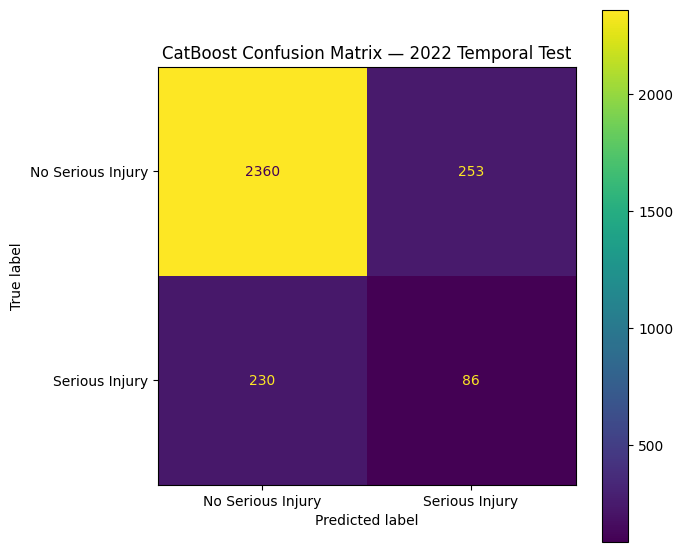

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test,
    test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Serious Injury",
        "Serious Injury"
    ]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "CatBoost Confusion Matrix — 2022 Temporal Test"
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CISS_Research/figures/"
    "CatBoost_Confusion_Matrix_2022.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

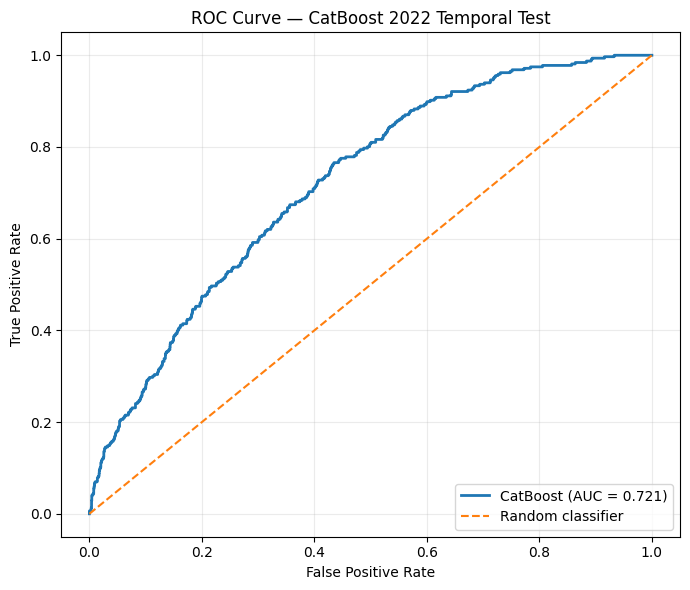

ROC-AUC = 0.7211


In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_prob
)

roc_auc = roc_auc_score(
    y_test,
    test_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"CatBoost (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — CatBoost 2022 Temporal Test"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CISS_Research/figures/"
    "CatBoost_ROC_2022.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"ROC-AUC = {roc_auc:.4f}"
)

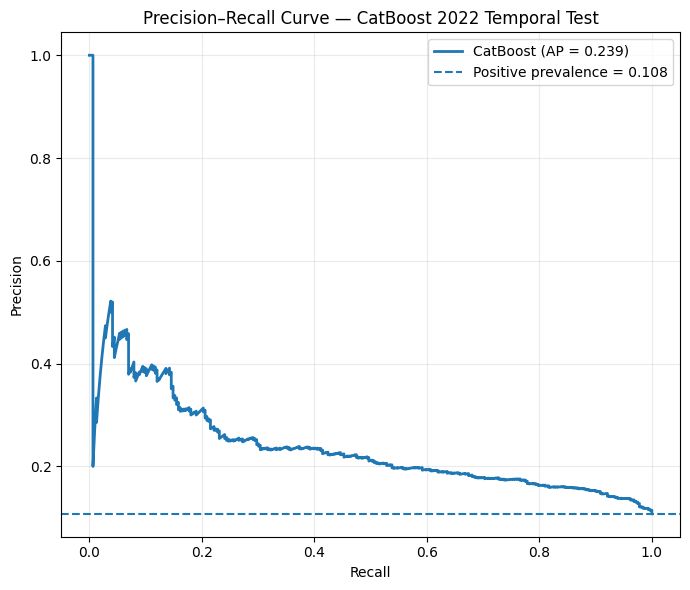

PR-AUC = 0.2386


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision, recall, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

pr_auc = average_precision_score(
    y_test,
    test_prob
)

baseline = y_test.mean()

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"CatBoost (AP = {pr_auc:.3f})"
)

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Positive prevalence = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — CatBoost 2022 Temporal Test"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CISS_Research/figures/"
    "CatBoost_PR_Curve_2022.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"PR-AUC = {pr_auc:.4f}"
)

In [ ]:
evals_result = (
    cat_model.get_evals_result()
)

print(
    evals_result.keys()
)

print(
    evals_result["learn"].keys()
)

print(
    evals_result["validation"].keys()
)

dict_keys(['learn', 'validation'])
dict_keys(['Logloss'])
dict_keys(['Logloss', 'AUC'])


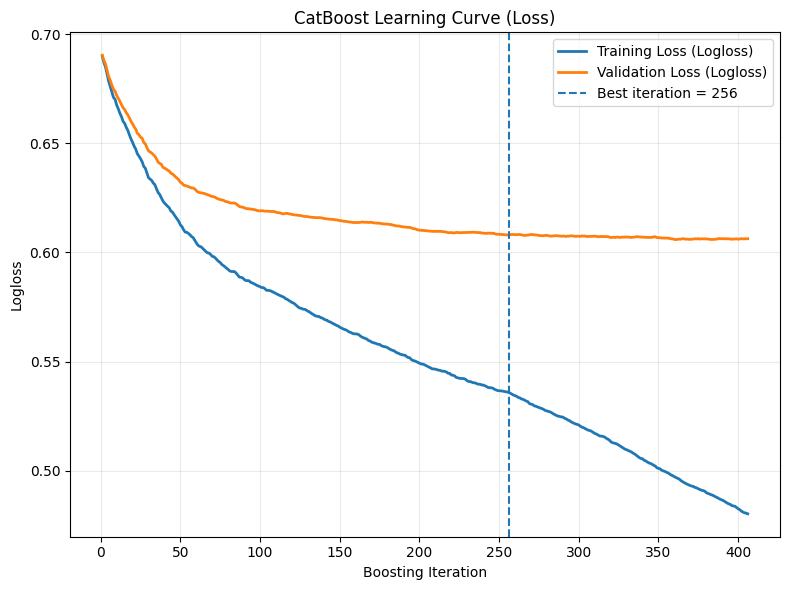

Best iteration: 255
Best validation AUC: 0.7295792486193244


In [ ]:
train_loss = (
    evals_result["learn"]["Logloss"]
)

val_loss = (
    evals_result["validation"]["Logloss"]
)

epochs = range(
    1,
    len(train_loss) + 1
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    epochs,
    train_loss,
    label="Training Loss (Logloss)",
    linewidth=2
)

plt.plot(
    epochs,
    val_loss,
    label="Validation Loss (Logloss)",
    linewidth=2
)

best_iteration = (
    cat_model.get_best_iteration()
    + 1
)

plt.axvline(
    x=best_iteration,
    linestyle="--",
    label=f"Best iteration = {best_iteration}"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Logloss")

plt.title(
    "CatBoost Learning Curve (Loss)"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CISS_Research/figures/"
    "CatBoost_Learning_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Best iteration:",
    cat_model.get_best_iteration()
)

if "AUC" in evals_result["validation"]:
    print(
        "Best validation AUC:",
        max(evals_result["validation"]["AUC"])
    )

5. Threshold vs Macro-F1 Curve

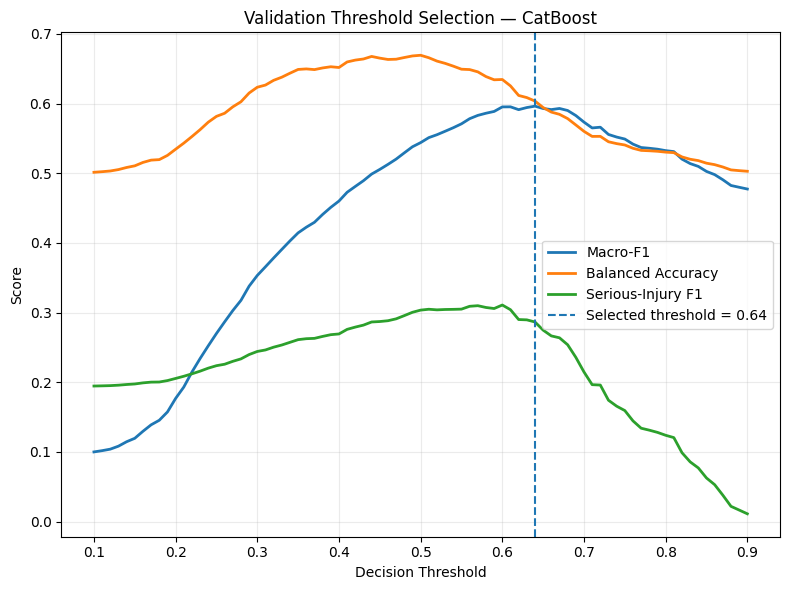

In [ ]:
plt.figure(
    figsize=(8, 6)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["macro_f1"],
    linewidth=2,
    label="Macro-F1"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["balanced_accuracy"],
    linewidth=2,
    label="Balanced Accuracy"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["positive_f1"],
    linewidth=2,
    label="Serious-Injury F1"
)

plt.axvline(
    BEST_THRESHOLD,
    linestyle="--",
    label=f"Selected threshold = {BEST_THRESHOLD:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Validation Threshold Selection — CatBoost"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/CISS_Research/figures/"
    "CatBoost_Threshold_Selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

এই CatBoost result save-ও করুন

In [ ]:
import json
import os

# Extract validation AUC from evals_result
validation_auc_list = evals_result["validation"]["AUC"]

catboost_results = {
    "model": "CatBoost",
    "train_years": "2017-2020",
    "validation_year": 2021,
    "test_year": 2022,

    "best_iteration":
        int(cat_model.get_best_iteration()),

    "validation_auc":
        float(max(validation_auc_list)),

    "selected_threshold":
        float(BEST_THRESHOLD),

    "test_accuracy":
        float(results["Accuracy"]),

    "test_balanced_accuracy":
        float(results["Balanced Accuracy"]),

    "test_macro_f1":
        float(results["Macro F1"]),

    "test_serious_precision":
        float(results["Serious Injury Precision"]),

    "test_serious_recall":
        float(results["Serious Injury Recall"]),

    "test_serious_f1":
        float(results["Serious Injury F1"]),

    "test_roc_auc":
        float(results["ROC-AUC"]),

    "test_pr_auc":
        float(results["PR-AUC"])
}

RESULT_PATH = os.path.join(
    RESULT_DIR,
    "CatBoost_2022_Temporal_Test.json"
)

with open(
    RESULT_PATH,
    "w"
) as f:

    json.dump(
        catboost_results,
        f,
        indent=4
    )

print("Saved:", RESULT_PATH)

Saved: /content/drive/MyDrive/CISS_Research/results/CatBoost_2022_Temporal_Test.json


Step 47 — Logistic Regression preprocessing

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Numeric preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            categorical_transformer,
            CATEGORICAL_COLS
        ),
        (
            "num",
            numeric_transformer,
            NUMERIC_COLS
        )
    ]
)

print("Preprocessor ready.")

Preprocessor ready.


Step 48 — Train Logistic Regression

In [ ]:
logreg_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                solver="liblinear",
                random_state=42
            )
        )
    ]
)

logreg_model.fit(
    X_train,
    y_train
)

print("✓ Logistic Regression training completed")

✓ Logistic Regression training completed


Step 49 — Validation threshold selection

In [ ]:
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

import numpy as np
import pandas as pd

val_prob_lr = logreg_model.predict_proba(
    X_val
)[:, 1]

lr_threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.01
):

    val_pred_lr = (
        val_prob_lr >= threshold
    ).astype(int)

    lr_threshold_results.append({
        "threshold": threshold,

        "macro_f1":
            f1_score(
                y_val,
                val_pred_lr,
                average="macro"
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_val,
                val_pred_lr
            ),

        "positive_f1":
            f1_score(
                y_val,
                val_pred_lr,
                pos_label=1
            )
    })

lr_threshold_df = pd.DataFrame(
    lr_threshold_results
)

best_lr_row = lr_threshold_df.loc[
    lr_threshold_df["macro_f1"].idxmax()
]

LR_BEST_THRESHOLD = float(
    best_lr_row["threshold"]
)

print("Best Logistic Regression threshold:")
print(best_lr_row)

Best Logistic Regression threshold:
threshold            0.750000
macro_f1             0.585167
balanced_accuracy    0.579427
positive_f1          0.252280
Name: 65, dtype: float64


Step 50 — 2022 Temporal Test

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

test_prob_lr = logreg_model.predict_proba(
    X_test
)[:, 1]

test_pred_lr = (
    test_prob_lr >= LR_BEST_THRESHOLD
).astype(int)

lr_results = {
    "Accuracy":
        accuracy_score(
            y_test,
            test_pred_lr
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test,
            test_pred_lr
        ),

    "Macro F1":
        f1_score(
            y_test,
            test_pred_lr,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            y_test,
            test_pred_lr,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            y_test,
            test_pred_lr,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            y_test,
            test_pred_lr,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test,
            test_prob_lr
        ),

    "PR-AUC":
        average_precision_score(
            y_test,
            test_prob_lr
        )
}

print(
    "\nLOGISTIC REGRESSION — "
    "2022 TEMPORAL TEST"
)

print("=" * 65)

for metric, value in lr_results.items():

    print(
        f"{metric:25s}: "
        f"{value:.4f}"
    )

print(
    "\nSelected threshold:",
    round(
        LR_BEST_THRESHOLD,
        3
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        test_pred_lr,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        test_pred_lr
    )
)


LOGISTIC REGRESSION — 2022 TEMPORAL TEST
Accuracy                 : 0.8580
Balanced Accuracy        : 0.5657
Macro F1                 : 0.5743
Serious Injury Precision : 0.2748
Serious Injury Recall    : 0.1930
Serious Injury F1        : 0.2268
ROC-AUC                  : 0.6739
PR-AUC                   : 0.2061

Selected threshold: 0.75

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9058    0.9384    0.9218      2613
   Serious Injury     0.2748    0.1930    0.2268       316

         accuracy                         0.8580      2929
        macro avg     0.5903    0.5657    0.5743      2929
     weighted avg     0.8377    0.8580    0.8468      2929

Confusion Matrix:
[[2452  161]
 [ 255   61]]


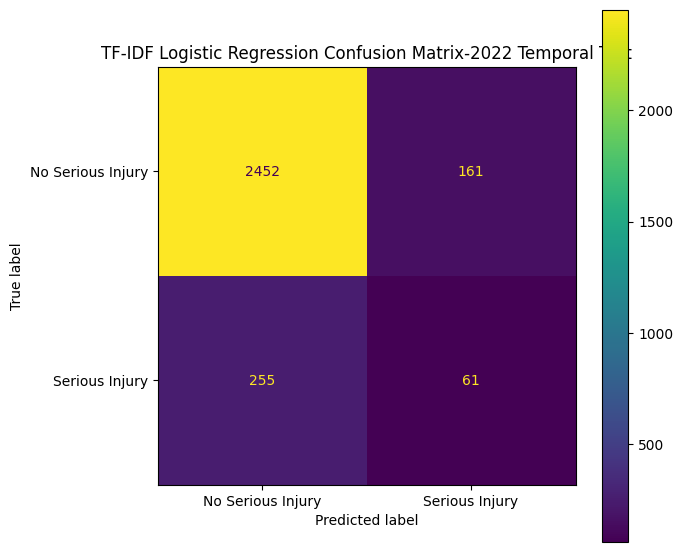

Saved: /content/drive/MyDrive/CISS_Research/figures/LogisticRegression_Confusion_Matrix_2022.png

Confusion Matrix:
[[2452  161]
 [ 255   61]]


In [ ]:
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

FIGURE_DIR = "/content/drive/MyDrive/CISS_Research/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

cm_lr = confusion_matrix(
    y_test,
    test_pred_lr
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=[
        "No Serious Injury",
        "Serious Injury"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "TF-IDF Logistic Regression Confusion Matrix-2022 Temporal Test"
)

plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "LogisticRegression_Confusion_Matrix_2022.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)
print("\nConfusion Matrix:")
print(cm_lr)

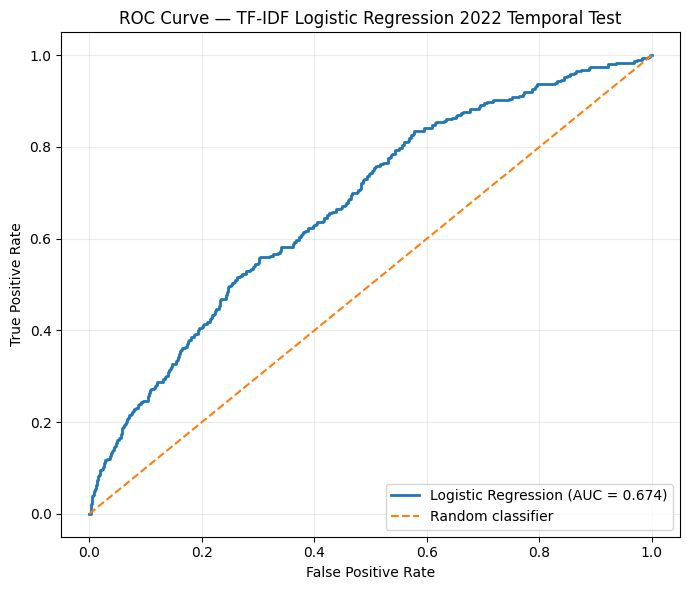

ROC-AUC: 0.6739
Saved: /content/drive/MyDrive/CISS_Research/figures/LogisticRegression_ROC_2022.png


In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr_lr, tpr_lr, roc_thresholds_lr = roc_curve(
    y_test,
    test_prob_lr
)

roc_auc_lr = roc_auc_score(
    y_test,
    test_prob_lr
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — TF-IDF Logistic Regression 2022 Temporal Test"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "LogisticRegression_ROC_2022.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", round(roc_auc_lr, 4))
print("Saved:", save_path)

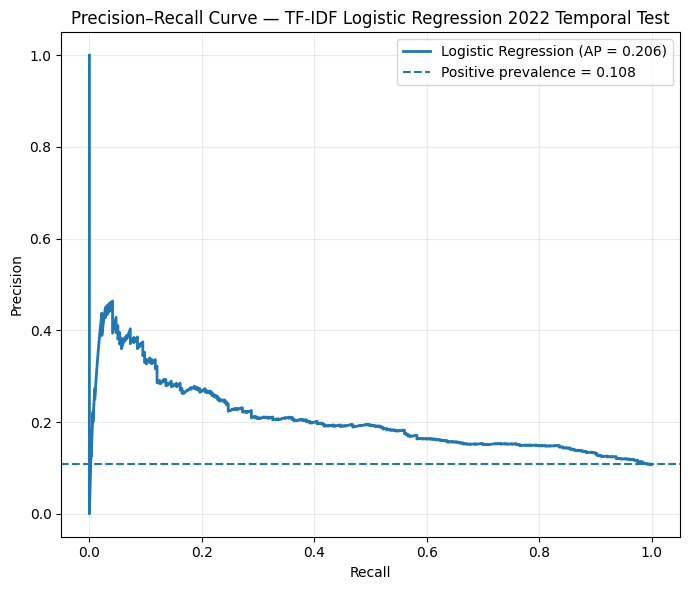

PR-AUC: 0.2061
Baseline prevalence: 0.1079
Saved: /content/drive/MyDrive/CISS_Research/figures/LogisticRegression_PR_Curve_2022.png


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_lr, recall_lr, pr_thresholds_lr = (
    precision_recall_curve(
        y_test,
        test_prob_lr
    )
)

pr_auc_lr = average_precision_score(
    y_test,
    test_prob_lr
)

baseline_lr = y_test.mean()

plt.figure(figsize=(7, 6))

plt.plot(
    recall_lr,
    precision_lr,
    linewidth=2,
    label=f"Logistic Regression (AP = {pr_auc_lr:.3f})"
)

plt.axhline(
    y=baseline_lr,
    linestyle="--",
    label=f"Positive prevalence = {baseline_lr:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — TF-IDF Logistic Regression 2022 Temporal Test"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "LogisticRegression_PR_Curve_2022.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR-AUC:", round(pr_auc_lr, 4))
print("Baseline prevalence:", round(baseline_lr, 4))
print("Saved:", save_path)

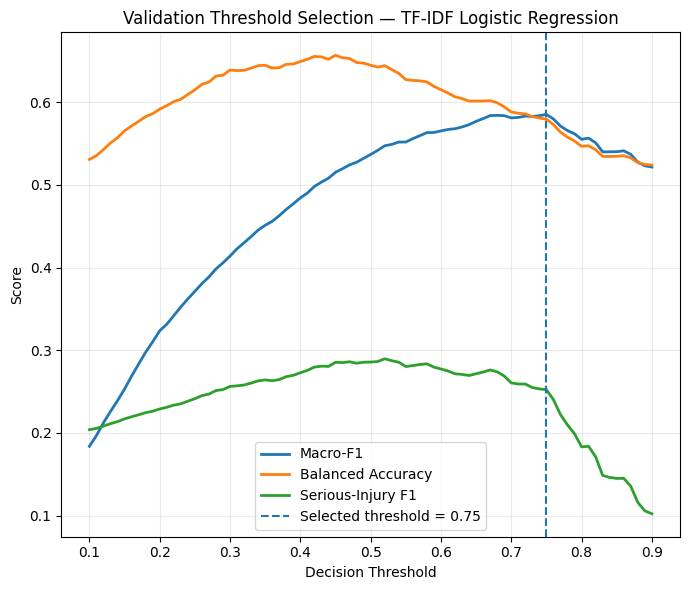

Selected threshold: 0.75
Saved: /content/drive/MyDrive/CISS_Research/figures/LogisticRegression_Threshold_Selection.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    lr_threshold_df["threshold"],
    lr_threshold_df["macro_f1"],
    linewidth=2,
    label="Macro-F1"
)

plt.plot(
    lr_threshold_df["threshold"],
    lr_threshold_df["balanced_accuracy"],
    linewidth=2,
    label="Balanced Accuracy"
)

plt.plot(
    lr_threshold_df["threshold"],
    lr_threshold_df["positive_f1"],
    linewidth=2,
    label="Serious-Injury F1"
)

plt.axvline(
    x=LR_BEST_THRESHOLD,
    linestyle="--",
    label=(
        f"Selected threshold = "
        f"{LR_BEST_THRESHOLD:.2f}"
    )
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Validation Threshold Selection — TF-IDF Logistic Regression"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "LogisticRegression_Threshold_Selection.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Selected threshold:",
    round(LR_BEST_THRESHOLD, 3)
)

print("Saved:", save_path)

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

fractions = [
    0.20,
    0.40,
    0.60,
    0.80,
    1.00
]

learning_results_lr = []

rng = np.random.RandomState(42)

for fraction in fractions:

    n_samples = int(
        len(X_train) * fraction
    )

    indices = rng.choice(
        len(X_train),
        size=n_samples,
        replace=False
    )

    X_sub = X_train.iloc[indices].copy()
    y_sub = y_train.iloc[indices].copy()

    temp_model = clone(
        logreg_model
    )

    temp_model.fit(
        X_sub,
        y_sub
    )

    train_prob = temp_model.predict_proba(
        X_sub
    )[:, 1]

    val_prob = temp_model.predict_proba(
        X_val
    )[:, 1]

    train_auc = roc_auc_score(
        y_sub,
        train_prob
    )

    val_auc = roc_auc_score(
        y_val,
        val_prob
    )

    learning_results_lr.append({
        "Training Fraction": fraction,
        "Training Samples": n_samples,
        "Training AUC": train_auc,
        "Validation AUC": val_auc
    })

    print(
        f"{fraction:.0%} | "
        f"N={n_samples:,} | "
        f"Train AUC={train_auc:.4f} | "
        f"Val AUC={val_auc:.4f}"
    )

learning_curve_lr = pd.DataFrame(
    learning_results_lr
)

display(learning_curve_lr)

20% | N=2,239 | Train AUC=0.9147 | Val AUC=0.6699
40% | N=4,479 | Train AUC=0.8586 | Val AUC=0.6626
60% | N=6,718 | Train AUC=0.8414 | Val AUC=0.6904
80% | N=8,958 | Train AUC=0.8271 | Val AUC=0.6995
100% | N=11,198 | Train AUC=0.8194 | Val AUC=0.6998


,Training Fraction,Training Samples,Training AUC,Validation AUC
0,0.2,2239,0.914723,0.669943
1,0.4,4479,0.858622,0.662559
2,0.6,6718,0.841379,0.690402
3,0.8,8958,0.827104,0.699546
4,1.0,11198,0.819444,0.699843


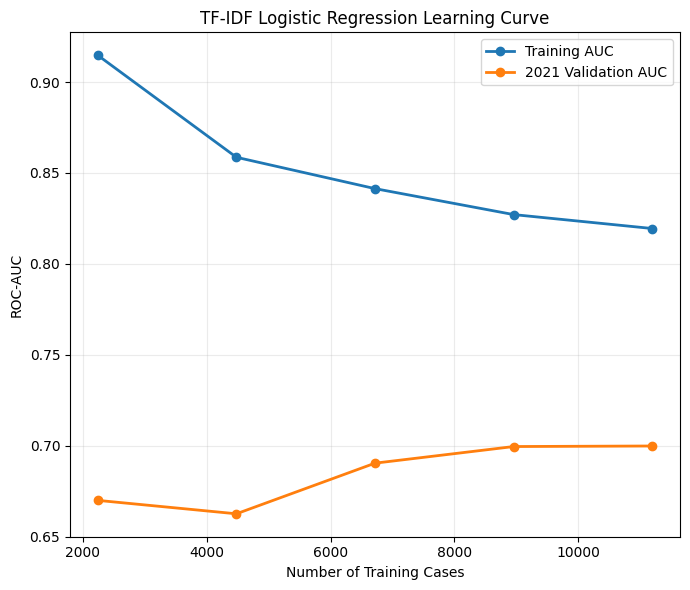

Saved: /content/drive/MyDrive/CISS_Research/figures/LogisticRegression_Learning_Curve.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    learning_curve_lr["Training Samples"],
    learning_curve_lr["Training AUC"],
    marker="o",
    linewidth=2,
    label="Training AUC"
)

plt.plot(
    learning_curve_lr["Training Samples"],
    learning_curve_lr["Validation AUC"],
    marker="o",
    linewidth=2,
    label="2021 Validation AUC"
)

plt.xlabel("Number of Training Cases")
plt.ylabel("ROC-AUC")

plt.title(
    "TF-IDF Logistic Regression Learning Curve"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "LogisticRegression_Learning_Curve.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

Step 51 — CatBoost vs Logistic Regression

In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Serious Injury Precision",
        "Serious Injury Recall",
        "Serious Injury F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "TF-IDF Logistic Regression": [
        lr_results["Accuracy"],
        lr_results["Balanced Accuracy"],
        lr_results["Macro F1"],
        lr_results["Serious Injury Precision"],
        lr_results["Serious Injury Recall"],
        lr_results["Serious Injury F1"],
        lr_results["ROC-AUC"],
        lr_results["PR-AUC"]
    ],

    "CatBoost": [
        results["Accuracy"],
        results["Balanced Accuracy"],
        results["Macro F1"],
        results["Serious Injury Precision"],
        results["Serious Injury Recall"],
        results["Serious Injury F1"],
        results["ROC-AUC"],
        results["PR-AUC"]
    ]
})

comparison[
    ["TF-IDF Logistic Regression", "CatBoost"]
] = comparison[
    ["TF-IDF Logistic Regression", "CatBoost"]
].round(4)

display(comparison)

,Metric,TF-IDF Logistic Regression,CatBoost
0,Accuracy,0.8580,0.8351
1,Balanced Accuracy,0.5657,0.5877
2,Macro F1,0.5743,0.5849
3,Serious Injury Precision,0.2748,0.2537
4,Serious Injury Recall,0.1930,0.2722
5,Serious Injury F1,0.2268,0.2626
6,ROC-AUC,0.6739,0.7211
7,PR-AUC,0.2061,0.2386


In [ ]:
comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "Structured_Baseline_Comparison_2022.csv"
    ),
    index=False
)

print("✓ Comparison saved")

✓ Comparison saved


next XGBoost structured baseline।

In [ ]:
!pip -q install xgboost

import xgboost as xgb

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

Step 53 — Preprocessing

In [ ]:
xgb_categorical = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

xgb_numeric = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            xgb_categorical,
            CATEGORICAL_COLS
        ),
        (
            "num",
            xgb_numeric,
            NUMERIC_COLS
        )
    ]
)

X_train_xgb = xgb_preprocessor.fit_transform(
    X_train
)

X_val_xgb = xgb_preprocessor.transform(
    X_val
)

X_test_xgb = xgb_preprocessor.transform(
    X_test
)

print("Train:", X_train_xgb.shape)
print("Validation:", X_val_xgb.shape)
print("Test:", X_test_xgb.shape)

Train: (11198, 1645)
Validation: (3331, 1645)
Test: (2929, 1645)


Step 54 — Class imbalance weight

In [ ]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = (
    negative / positive
)

print("Negative:", negative)
print("Positive:", positive)
print(
    "scale_pos_weight:",
    round(scale_pos_weight, 3)
)

Negative: 9924
Positive: 1274
scale_pos_weight: 7.79


Step 55 — Train XGBoost

In [ ]:
xgb_model = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=5,

    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=2.0,

    scale_pos_weight=scale_pos_weight,

    objective="binary:logistic",
    eval_metric="auc",

    random_state=42,
    n_jobs=-1,

    early_stopping_rounds=150
)

xgb_model.fit(
    X_train_xgb,
    y_train,

    eval_set=[
        (X_train_xgb, y_train),
        (X_val_xgb, y_val)
    ],

    verbose=100
)

[0]	validation_0-auc:0.65389	validation_1-auc:0.62187
[100]	validation_0-auc:0.81636	validation_1-auc:0.72468
[200]	validation_0-auc:0.84954	validation_1-auc:0.73163
[300]	validation_0-auc:0.87111	validation_1-auc:0.73263
[400]	validation_0-auc:0.88658	validation_1-auc:0.73387
[500]	validation_0-auc:0.89774	validation_1-auc:0.73453
[600]	validation_0-auc:0.90807	validation_1-auc:0.73360
[624]	validation_0-auc:0.91060	validation_1-auc:0.73333


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=150,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=2000,
              n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
print(
    "Best iteration:",
    xgb_model.best_iteration
)

print(
    "Best validation AUC:",
    xgb_model.best_score
)

Best iteration: 474
Best validation AUC: 0.7352663731497819


Step 56 — Validation threshold selection

In [ ]:
val_prob_xgb = xgb_model.predict_proba(
    X_val_xgb
)[:, 1]

xgb_threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.01
):

    pred = (
        val_prob_xgb >= threshold
    ).astype(int)

    xgb_threshold_results.append({
        "threshold": threshold,

        "macro_f1":
            f1_score(
                y_val,
                pred,
                average="macro"
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_val,
                pred
            ),

        "positive_f1":
            f1_score(
                y_val,
                pred
            )
    })

xgb_threshold_df = pd.DataFrame(
    xgb_threshold_results
)

best_xgb_row = xgb_threshold_df.loc[
    xgb_threshold_df["macro_f1"].idxmax()
]

XGB_BEST_THRESHOLD = float(
    best_xgb_row["threshold"]
)

print(
    "Best XGBoost threshold:"
)

print(best_xgb_row)

Best XGBoost threshold:
threshold            0.670000
macro_f1             0.601361
balanced_accuracy    0.601861
positive_f1          0.288889
Name: 57, dtype: float64


Step 57 — 2022 temporal test

In [ ]:
test_prob_xgb = xgb_model.predict_proba(
    X_test_xgb
)[:, 1]

test_pred_xgb = (
    test_prob_xgb >= XGB_BEST_THRESHOLD
).astype(int)

xgb_results = {
    "Accuracy":
        accuracy_score(
            y_test,
            test_pred_xgb
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test,
            test_pred_xgb
        ),

    "Macro F1":
        f1_score(
            y_test,
            test_pred_xgb,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            y_test,
            test_pred_xgb,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            y_test,
            test_pred_xgb,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            y_test,
            test_pred_xgb,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test,
            test_prob_xgb
        ),

    "PR-AUC":
        average_precision_score(
            y_test,
            test_prob_xgb
        )
}

print(
    "\nXGBOOST — 2022 TEMPORAL TEST"
)

print("=" * 60)

for metric, value in xgb_results.items():
    print(
        f"{metric:25s}: "
        f"{value:.4f}"
    )

print(
    "\nSelected threshold:",
    round(
        XGB_BEST_THRESHOLD,
        3
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        test_pred_xgb,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        test_pred_xgb
    )
)


XGBOOST — 2022 TEMPORAL TEST
Accuracy                 : 0.8426
Balanced Accuracy        : 0.5668
Macro F1                 : 0.5701
Serious Injury Precision : 0.2420
Serious Injury Recall    : 0.2152
Serious Injury F1        : 0.2278
ROC-AUC                  : 0.7108
PR-AUC                   : 0.2220

Selected threshold: 0.67

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9063    0.9185    0.9124      2613
   Serious Injury     0.2420    0.2152    0.2278       316

         accuracy                         0.8426      2929
        macro avg     0.5742    0.5668    0.5701      2929
     weighted avg     0.8347    0.8426    0.8385      2929

Confusion Matrix:
[[2400  213]
 [ 248   68]]


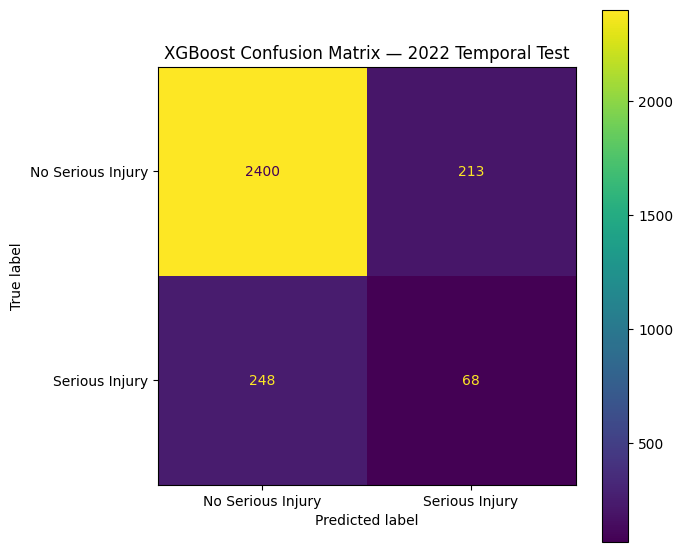

Saved: /content/drive/MyDrive/CISS_Research/figures/XGBoost_Confusion_Matrix_2022.png
[[2400  213]
 [ 248   68]]


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

FIGURE_DIR = "/content/drive/MyDrive/CISS_Research/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

cm_xgb = confusion_matrix(
    y_test,
    test_pred_xgb
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[
        "No Serious Injury",
        "Serious Injury"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "XGBoost Confusion Matrix — 2022 Temporal Test"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "XGBoost_Confusion_Matrix_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)
print(cm_xgb)

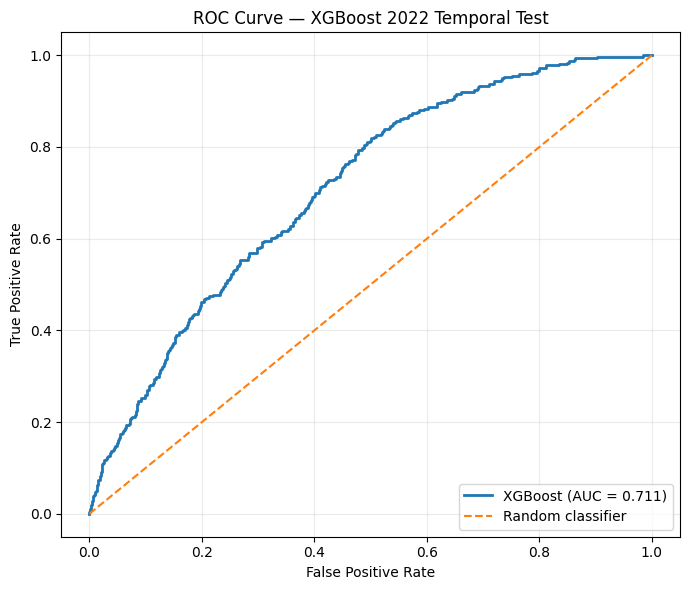

ROC-AUC: 0.7108
Saved: /content/drive/MyDrive/CISS_Research/figures/XGBoost_ROC_2022.png


In [ ]:
fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    test_prob_xgb
)

roc_auc_xgb = roc_auc_score(
    y_test,
    test_prob_xgb
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f"XGBoost (AUC = {roc_auc_xgb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — XGBoost 2022 Temporal Test"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "XGBoost_ROC_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", round(roc_auc_xgb, 4))
print("Saved:", path)

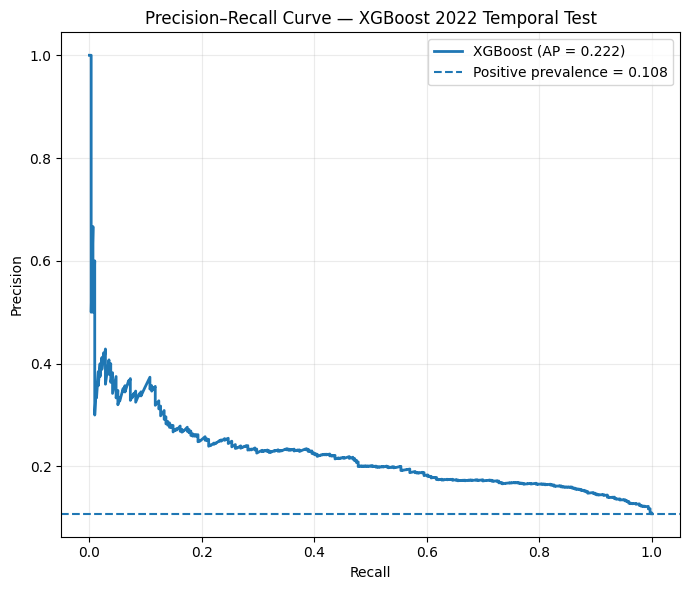

PR-AUC: 0.222
Positive prevalence: 0.1079
Saved: /content/drive/MyDrive/CISS_Research/figures/XGBoost_PR_Curve_2022.png


In [ ]:
precision_xgb, recall_xgb, _ = (
    precision_recall_curve(
        y_test,
        test_prob_xgb
    )
)

pr_auc_xgb = average_precision_score(
    y_test,
    test_prob_xgb
)

positive_prevalence = y_test.mean()

plt.figure(figsize=(7, 6))

plt.plot(
    recall_xgb,
    precision_xgb,
    linewidth=2,
    label=f"XGBoost (AP = {pr_auc_xgb:.3f})"
)

plt.axhline(
    y=positive_prevalence,
    linestyle="--",
    label=f"Positive prevalence = {positive_prevalence:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — XGBoost 2022 Temporal Test"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "XGBoost_PR_Curve_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR-AUC:", round(pr_auc_xgb, 4))
print(
    "Positive prevalence:",
    round(positive_prevalence, 4)
)
print("Saved:", path)

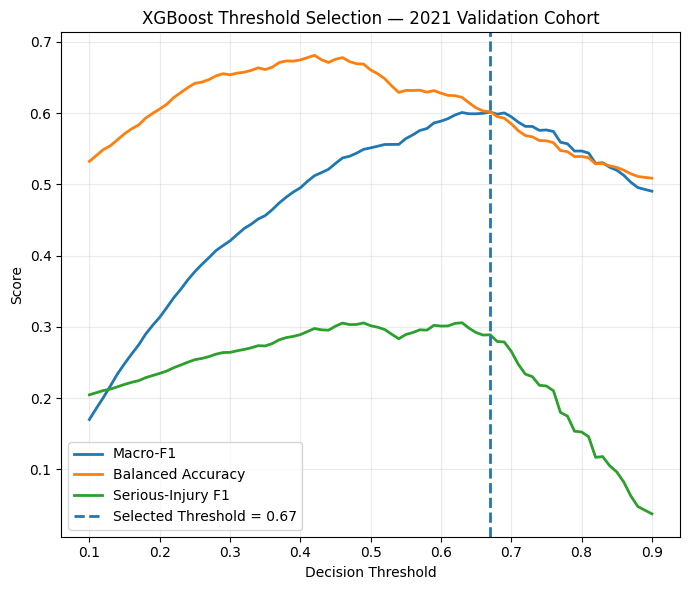

Selected threshold: 0.67
Saved: /content/drive/MyDrive/CISS_Research/figures/XGBoost_Threshold_Selection_2021.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    xgb_threshold_df["threshold"],
    xgb_threshold_df["macro_f1"],
    linewidth=2,
    label="Macro-F1"
)

plt.plot(
    xgb_threshold_df["threshold"],
    xgb_threshold_df["balanced_accuracy"],
    linewidth=2,
    label="Balanced Accuracy"
)

plt.plot(
    xgb_threshold_df["threshold"],
    xgb_threshold_df["positive_f1"],
    linewidth=2,
    label="Serious-Injury F1"
)

plt.axvline(
    x=XGB_BEST_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Selected Threshold = {XGB_BEST_THRESHOLD:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "XGBoost Threshold Selection — 2021 Validation Cohort"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "XGBoost_Threshold_Selection_2021.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Selected threshold:",
    round(XGB_BEST_THRESHOLD, 3)
)

print("Saved:", path)

In [ ]:
evals_result_xgb = (
    xgb_model.evals_result()
)

print(
    evals_result_xgb.keys()
)

dict_keys(['validation_0', 'validation_1'])


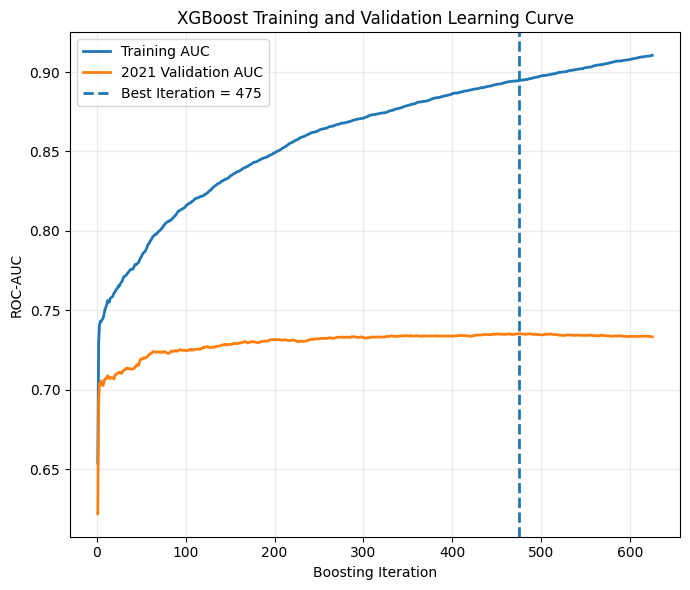

Best internal iteration: 474
Best plotted tree number: 475
Saved: /content/drive/MyDrive/CISS_Research/figures/XGBoost_Learning_Curve.png


In [ ]:
train_auc_history = (
    evals_result_xgb["validation_0"]["auc"]
)

val_auc_history = (
    evals_result_xgb["validation_1"]["auc"]
)

iterations = range(
    1,
    len(train_auc_history) + 1
)

plt.figure(figsize=(7, 6))

plt.plot(
    iterations,
    train_auc_history,
    linewidth=2,
    label="Training AUC"
)

plt.plot(
    iterations,
    val_auc_history,
    linewidth=2,
    label="2021 Validation AUC"
)

best_tree_number = (
    xgb_model.best_iteration + 1
)

plt.axvline(
    x=best_tree_number,
    linestyle="--",
    linewidth=2,
    label=f"Best Iteration = {best_tree_number}"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("ROC-AUC")

plt.title(
    "XGBoost Training and Validation Learning Curve"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "XGBoost_Learning_Curve.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Best internal iteration:",
    xgb_model.best_iteration
)

print(
    "Best plotted tree number:",
    best_tree_number
)

print("Saved:", path)

Step 58 — Three-model final comparison

In [ ]:
structured_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Serious Injury Precision",
        "Serious Injury Recall",
        "Serious Injury F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "TF-IDF Logistic Regression": [
        lr_results["Accuracy"],
        lr_results["Balanced Accuracy"],
        lr_results["Macro F1"],
        lr_results["Serious Injury Precision"],
        lr_results["Serious Injury Recall"],
        lr_results["Serious Injury F1"],
        lr_results["ROC-AUC"],
        lr_results["PR-AUC"]
    ],

    "XGBoost": [
        xgb_results["Accuracy"],
        xgb_results["Balanced Accuracy"],
        xgb_results["Macro F1"],
        xgb_results["Serious Injury Precision"],
        xgb_results["Serious Injury Recall"],
        xgb_results["Serious Injury F1"],
        xgb_results["ROC-AUC"],
        xgb_results["PR-AUC"]
    ],

    "CatBoost": [
        results["Accuracy"],
        results["Balanced Accuracy"],
        results["Macro F1"],
        results["Serious Injury Precision"],
        results["Serious Injury Recall"],
        results["Serious Injury F1"],
        results["ROC-AUC"],
        results["PR-AUC"]
    ]
})

numeric_cols = [
    "TF-IDF Logistic Regression",
    "XGBoost",
    "CatBoost"
]

structured_comparison[numeric_cols] = (
    structured_comparison[numeric_cols]
    .round(4)
)

display(structured_comparison)

structured_comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "Structured_Models_Final_Comparison_2022.csv"
    ),
    index=False
)

print("✓ Final structured comparison saved")

,Metric,TF-IDF Logistic Regression,XGBoost,CatBoost
0,Accuracy,0.8580,0.8426,0.8351
1,Balanced Accuracy,0.5657,0.5668,0.5877
2,Macro F1,0.5743,0.5701,0.5849
3,Serious Injury Precision,0.2748,0.2420,0.2537
4,Serious Injury Recall,0.1930,0.2152,0.2722
5,Serious Injury F1,0.2268,0.2278,0.2626
6,ROC-AUC,0.6739,0.7108,0.7211
7,PR-AUC,0.2061,0.2220,0.2386


✓ Final structured comparison saved


**TF-IDF + Logistic Regression → Linear SVM → BERT → DeBERTa-v3**

Step 59 — Load narrative temporal splits

In [ ]:
import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/CISS_Research"

SPLIT_DIR = os.path.join(
    BASE_DIR,
    "splits"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "results"
)

FIGURE_DIR = os.path.join(
    BASE_DIR,
    "figures"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

train_df = pd.read_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_train_2017_2020.csv"
    )
)

val_df = pd.read_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_val_2021.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        SPLIT_DIR,
        "multimodal_test_2022.csv"
    )
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (11198, 46)
Validation: (3331, 46)
Test: (2929, 46)


Step 60 — Check narrative and target

In [ ]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Cases:", len(df))

    print(
        "Missing SUMMARY:",
        df["SUMMARY"].isna().sum()
    )

    print(
        "Empty SUMMARY:",
        (
            df["SUMMARY"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
        ).sum()
    )

    print("\nTarget distribution:")

    print(
        df["SERIOUS_INJURY"]
        .value_counts()
        .sort_index()
    )

    print(
        "Positive prevalence:",
        round(
            df["SERIOUS_INJURY"].mean(),
            4
        )
    )


Train
Cases: 11198
Missing SUMMARY: 0
Empty SUMMARY: 0

Target distribution:
SERIOUS_INJURY
0    9924
1    1274
Name: count, dtype: int64
Positive prevalence: 0.1138

Validation
Cases: 3331
Missing SUMMARY: 0
Empty SUMMARY: 0

Target distribution:
SERIOUS_INJURY
0    2973
1     358
Name: count, dtype: int64
Positive prevalence: 0.1075

Test
Cases: 2929
Missing SUMMARY: 0
Empty SUMMARY: 0

Target distribution:
SERIOUS_INJURY
0    2613
1     316
Name: count, dtype: int64
Positive prevalence: 0.1079


Step 61 — Prepare text

In [ ]:
X_train_text = (
    train_df["SUMMARY"]
    .fillna("")
    .astype(str)
    .str.strip()
)

X_val_text = (
    val_df["SUMMARY"]
    .fillna("")
    .astype(str)
    .str.strip()
)

X_test_text = (
    test_df["SUMMARY"]
    .fillna("")
    .astype(str)
    .str.strip()
)

y_train_text = (
    train_df["SERIOUS_INJURY"]
    .astype(int)
)

y_val_text = (
    val_df["SERIOUS_INJURY"]
    .astype(int)
)

y_test_text = (
    test_df["SERIOUS_INJURY"]
    .astype(int)
)

print("Train texts:", len(X_train_text))
print("Validation texts:", len(X_val_text))
print("Test texts:", len(X_test_text))

print("\nExample narrative:\n")
print(X_train_text.iloc[0][:1000])

Train texts: 11198
Validation texts: 3331
Test texts: 2929

Example narrative:

V1 was traveling Northbound on roadway and struck a deer head-on.


Step 62 — TF-IDF vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,

    ngram_range=(1, 2),

    min_df=3,

    max_df=0.98,

    max_features=50000,

    sublinear_tf=True,

    strip_accents="unicode"
)

X_train_tfidf = tfidf.fit_transform(
    X_train_text
)

X_val_tfidf = tfidf.transform(
    X_val_text
)

X_test_tfidf = tfidf.transform(
    X_test_text
)

print(
    "Train TF-IDF:",
    X_train_tfidf.shape
)

print(
    "Validation TF-IDF:",
    X_val_tfidf.shape
)

print(
    "Test TF-IDF:",
    X_test_tfidf.shape
)

print(
    "Vocabulary size:",
    len(tfidf.vocabulary_)
)

Train TF-IDF: (11198, 10522)
Validation TF-IDF: (3331, 10522)
Test TF-IDF: (2929, 10522)
Vocabulary size: 10522


Step 63 — Train TF-IDF + Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

tfidf_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    solver="liblinear",
    C=1.0,
    random_state=42
)

tfidf_lr.fit(
    X_train_tfidf,
    y_train_text
)

print(
    "✓ TF-IDF + Logistic Regression training completed"
)

✓ TF-IDF + Logistic Regression training completed


In [ ]:
train_prob_text_lr = (
    tfidf_lr.predict_proba(
        X_train_tfidf
    )[:, 1]
)

val_prob_text_lr = (
    tfidf_lr.predict_proba(
        X_val_tfidf
    )[:, 1]
)

test_prob_text_lr = (
    tfidf_lr.predict_proba(
        X_test_tfidf
    )[:, 1]
)

from sklearn.metrics import roc_auc_score

print(
    "Train ROC-AUC:",
    round(
        roc_auc_score(
            y_train_text,
            train_prob_text_lr
        ),
        4
    )
)

print(
    "2021 Validation ROC-AUC:",
    round(
        roc_auc_score(
            y_val_text,
            val_prob_text_lr
        ),
        4
    )
)

Train ROC-AUC: 0.9242
2021 Validation ROC-AUC: 0.755


Step 64 — Validation-only threshold selection

In [ ]:
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

threshold_results_text_lr = []

for threshold in np.arange(
    0.10,
    0.91,
    0.01
):

    val_pred = (
        val_prob_text_lr >= threshold
    ).astype(int)

    threshold_results_text_lr.append({
        "threshold": threshold,

        "macro_f1": f1_score(
            y_val_text,
            val_pred,
            average="macro"
        ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_val_text,
                val_pred
            ),

        "positive_f1": f1_score(
            y_val_text,
            val_pred,
            pos_label=1
        )
    })

text_lr_threshold_df = pd.DataFrame(
    threshold_results_text_lr
)

best_text_lr_row = text_lr_threshold_df.loc[
    text_lr_threshold_df["macro_f1"].idxmax()
]

TEXT_LR_BEST_THRESHOLD = float(
    best_text_lr_row["threshold"]
)

print(
    "Best TF-IDF + Logistic Regression threshold:"
)

print(best_text_lr_row)

Best TF-IDF + Logistic Regression threshold:
threshold            0.660000
macro_f1             0.638768
balanced_accuracy    0.648221
positive_f1          0.361039
Name: 56, dtype: float64


Step 65 — Evaluate untouched 2022 test

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

test_pred_text_lr = (
    test_prob_text_lr >= TEXT_LR_BEST_THRESHOLD
).astype(int)

text_lr_results = {

    "Accuracy":
        accuracy_score(
            y_test_text,
            test_pred_text_lr
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test_text,
            test_pred_text_lr
        ),

    "Macro F1":
        f1_score(
            y_test_text,
            test_pred_text_lr,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            y_test_text,
            test_pred_text_lr,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            y_test_text,
            test_pred_text_lr,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            y_test_text,
            test_pred_text_lr,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test_text,
            test_prob_text_lr
        ),

    "PR-AUC":
        average_precision_score(
            y_test_text,
            test_prob_text_lr
        )
}

print(
    "\nTF-IDF + LOGISTIC REGRESSION"
    " — 2022 TEMPORAL TEST"
)

print("=" * 65)

for metric, value in text_lr_results.items():

    print(
        f"{metric:25s}: {value:.4f}"
    )

print(
    "\nSelected threshold:",
    round(
        TEXT_LR_BEST_THRESHOLD,
        3
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_text,
        test_pred_text_lr,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

cm_text_lr = confusion_matrix(
    y_test_text,
    test_pred_text_lr
)

print(cm_text_lr)


TF-IDF + LOGISTIC REGRESSION — 2022 TEMPORAL TEST
Accuracy                 : 0.8460
Balanced Accuracy        : 0.6035
Macro F1                 : 0.6028
Serious Injury Precision : 0.2897
Serious Injury Recall    : 0.2943
Serious Injury F1        : 0.2920
ROC-AUC                  : 0.7406
PR-AUC                   : 0.2719

Selected threshold: 0.66

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9145    0.9127    0.9136      2613
   Serious Injury     0.2897    0.2943    0.2920       316

         accuracy                         0.8460      2929
        macro avg     0.6021    0.6035    0.6028      2929
     weighted avg     0.8471    0.8460    0.8466      2929

Confusion Matrix:
[[2385  228]
 [ 223   93]]


Step 66 — Narrative vs best structured baseline

In [ ]:
narrative_vs_structured = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Serious Injury Precision",
        "Serious Injury Recall",
        "Serious Injury F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Structured CatBoost": [
        results["Accuracy"],
        results["Balanced Accuracy"],
        results["Macro F1"],
        results["Serious Injury Precision"],
        results["Serious Injury Recall"],
        results["Serious Injury F1"],
        results["ROC-AUC"],
        results["PR-AUC"]
    ],

    "Narrative TF-IDF + LR": [
        text_lr_results["Accuracy"],
        text_lr_results["Balanced Accuracy"],
        text_lr_results["Macro F1"],
        text_lr_results["Serious Injury Precision"],
        text_lr_results["Serious Injury Recall"],
        text_lr_results["Serious Injury F1"],
        text_lr_results["ROC-AUC"],
        text_lr_results["PR-AUC"]
    ]
})

narrative_vs_structured[
    [
        "Structured CatBoost",
        "Narrative TF-IDF + LR"
    ]
] = narrative_vs_structured[
    [
        "Structured CatBoost",
        "Narrative TF-IDF + LR"
    ]
].round(4)

display(
    narrative_vs_structured
)

,Metric,Structured CatBoost,Narrative TF-IDF + LR
0,Accuracy,0.8351,0.8460
1,Balanced Accuracy,0.5877,0.6035
2,Macro F1,0.5849,0.6028
3,Serious Injury Precision,0.2537,0.2897
4,Serious Injury Recall,0.2722,0.2943
5,Serious Injury F1,0.2626,0.2920
6,ROC-AUC,0.7211,0.7406
7,PR-AUC,0.2386,0.2719


In [ ]:
save_path = os.path.join(
    RESULT_DIR,
    "Structured_vs_Narrative_TFIDF_LR_2022.csv"
)

narrative_vs_structured.to_csv(
    save_path,
    index=False
)

print("Saved:", save_path)

Saved: /content/drive/MyDrive/CISS_Research/results/Structured_vs_Narrative_TFIDF_LR_2022.csv


Step 67 — Train Linear SVM

In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

svm_model.fit(
    X_train_tfidf,
    y_train_text
)

print("✓ TF-IDF + Linear SVM training completed")

✓ TF-IDF + Linear SVM training completed


Step 68 — Get decision scores

In [ ]:
train_score_svm = svm_model.decision_function(
    X_train_tfidf
)

val_score_svm = svm_model.decision_function(
    X_val_tfidf
)

test_score_svm = svm_model.decision_function(
    X_test_tfidf
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

print(
    "Train ROC-AUC:",
    round(
        roc_auc_score(
            y_train_text,
            train_score_svm
        ),
        4
    )
)

print(
    "2021 Validation ROC-AUC:",
    round(
        roc_auc_score(
            y_val_text,
            val_score_svm
        ),
        4
    )
)

print(
    "2021 Validation PR-AUC:",
    round(
        average_precision_score(
            y_val_text,
            val_score_svm
        ),
        4
    )
)

Train ROC-AUC: 0.9913
2021 Validation ROC-AUC: 0.7099
2021 Validation PR-AUC: 0.273


Step 69 — Select threshold using 2021 validation only

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

candidate_thresholds = np.linspace(
    np.percentile(val_score_svm, 1),
    np.percentile(val_score_svm, 99),
    300
)

svm_threshold_results = []

for threshold in candidate_thresholds:

    val_pred_svm = (
        val_score_svm >= threshold
    ).astype(int)

    svm_threshold_results.append({
        "threshold": threshold,

        "macro_f1":
            f1_score(
                y_val_text,
                val_pred_svm,
                average="macro"
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_val_text,
                val_pred_svm
            ),

        "positive_f1":
            f1_score(
                y_val_text,
                val_pred_svm,
                pos_label=1
            )
    })

svm_threshold_df = pd.DataFrame(
    svm_threshold_results
)

best_svm_row = svm_threshold_df.loc[
    svm_threshold_df["macro_f1"].idxmax()
]

SVM_BEST_THRESHOLD = float(
    best_svm_row["threshold"]
)

print(
    "Best TF-IDF + Linear SVM threshold:"
)

print(best_svm_row)

Best TF-IDF + Linear SVM threshold:
threshold            0.352490
macro_f1             0.607835
balanced_accuracy    0.604837
positive_f1          0.297258
Name: 221, dtype: float64


Step 70 — Evaluate on untouched 2022 test

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

test_pred_svm = (
    test_score_svm >= SVM_BEST_THRESHOLD
).astype(int)

svm_results = {

    "Accuracy":
        accuracy_score(
            y_test_text,
            test_pred_svm
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test_text,
            test_pred_svm
        ),

    "Macro F1":
        f1_score(
            y_test_text,
            test_pred_svm,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            y_test_text,
            test_pred_svm,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            y_test_text,
            test_pred_svm,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            y_test_text,
            test_pred_svm,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test_text,
            test_score_svm
        ),

    "PR-AUC":
        average_precision_score(
            y_test_text,
            test_score_svm
        )
}

print(
    "\nTF-IDF + LINEAR SVM — "
    "2022 TEMPORAL TEST"
)

print("=" * 65)

for metric, value in svm_results.items():

    print(
        f"{metric:25s}: "
        f"{value:.4f}"
    )

print(
    "\nSelected decision threshold:",
    round(
        SVM_BEST_THRESHOLD,
        4
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_text,
        test_pred_svm,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

cm_svm = confusion_matrix(
    y_test_text,
    test_pred_svm
)

print(cm_svm)


TF-IDF + LINEAR SVM — 2022 TEMPORAL TEST
Accuracy                 : 0.8546
Balanced Accuracy        : 0.5861
Macro F1                 : 0.5924
Serious Injury Precision : 0.2917
Serious Injury Recall    : 0.2437
Serious Injury F1        : 0.2655
ROC-AUC                  : 0.6853
PR-AUC                   : 0.2485

Selected decision threshold: 0.3525

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9103    0.9284    0.9193      2613
   Serious Injury     0.2917    0.2437    0.2655       316

         accuracy                         0.8546      2929
        macro avg     0.6010    0.5861    0.5924      2929
     weighted avg     0.8436    0.8546    0.8488      2929

Confusion Matrix:
[[2426  187]
 [ 239   77]]


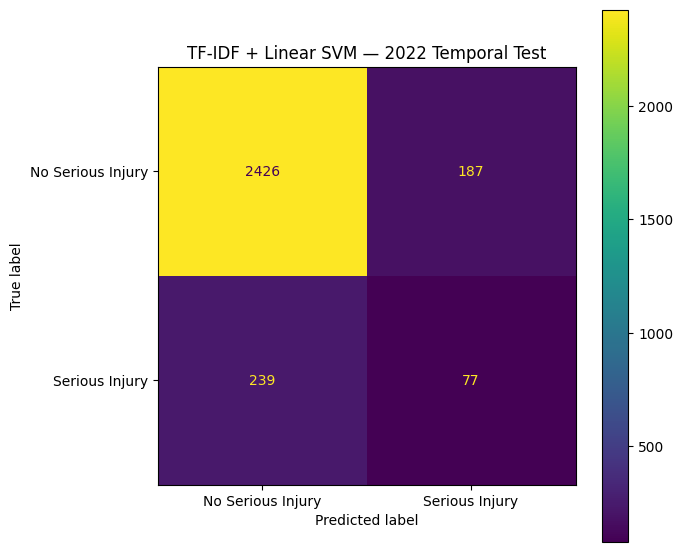

Saved: /content/drive/MyDrive/CISS_Research/figures/TFIDF_LinearSVM_Confusion_Matrix_2022.png


In [ ]:
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

FIGURE_DIR = "/content/drive/MyDrive/CISS_Research/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

cm_svm = confusion_matrix(
    y_test_text,
    test_pred_svm
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=[
        "No Serious Injury",
        "Serious Injury"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "TF-IDF + Linear SVM — 2022 Temporal Test"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "TFIDF_LinearSVM_Confusion_Matrix_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

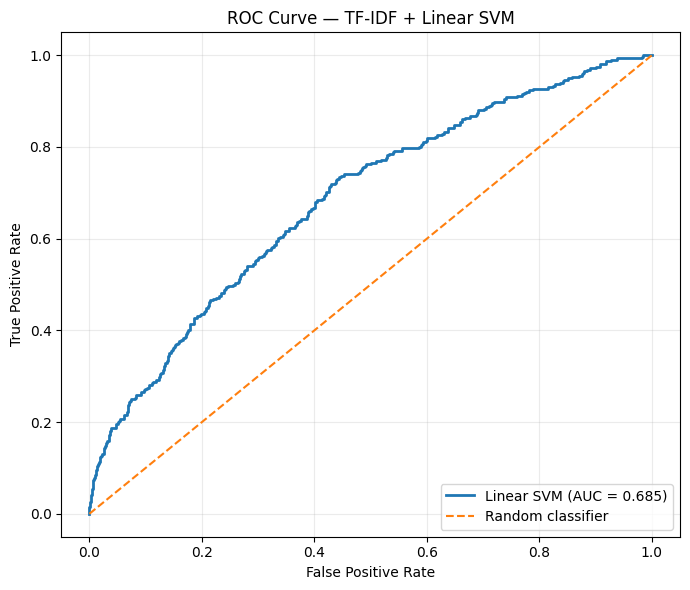

ROC-AUC: 0.6853
Saved: /content/drive/MyDrive/CISS_Research/figures/TF-IDF_LinearSVM_ROC_2022.png


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_svm, tpr_svm, _ = roc_curve(
    y_test_text,
    test_score_svm
)

auc_svm = roc_auc_score(
    y_test_text,
    test_score_svm
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_svm,
    tpr_svm,
    linewidth=2,
    label=f"Linear SVM (AUC = {auc_svm:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — TF-IDF + Linear SVM"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "TF-IDF_LinearSVM_ROC_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", round(auc_svm, 4))
print("Saved:", path)

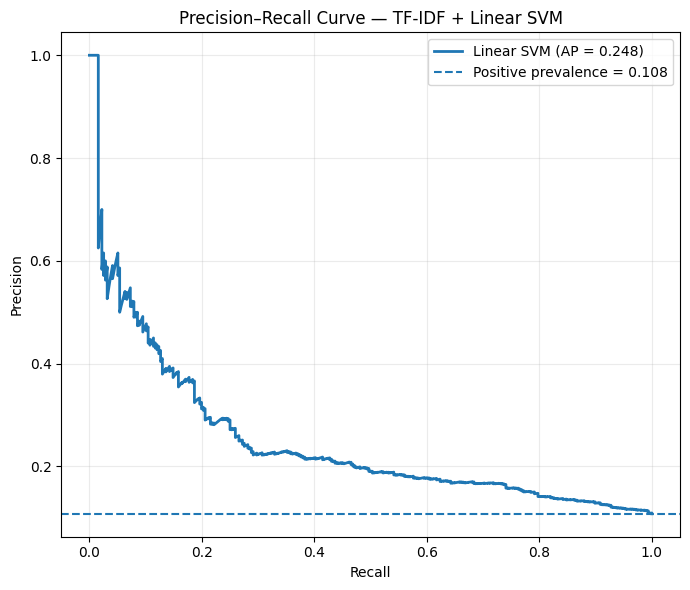

PR-AUC: 0.2485
Saved: /content/drive/MyDrive/CISS_Research/figures/TF-IDF_LinearSVM_PR_2022.png


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_svm, recall_svm, _ = (
    precision_recall_curve(
        y_test_text,
        test_score_svm
    )
)

ap_svm = average_precision_score(
    y_test_text,
    test_score_svm
)

prevalence = y_test_text.mean()

plt.figure(figsize=(7, 6))

plt.plot(
    recall_svm,
    precision_svm,
    linewidth=2,
    label=f"Linear SVM (AP = {ap_svm:.3f})"
)

plt.axhline(
    y=prevalence,
    linestyle="--",
    label=f"Positive prevalence = {prevalence:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — TF-IDF + Linear SVM"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "TF-IDF_LinearSVM_PR_2022.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR-AUC:", round(ap_svm, 4))
print("Saved:", path)

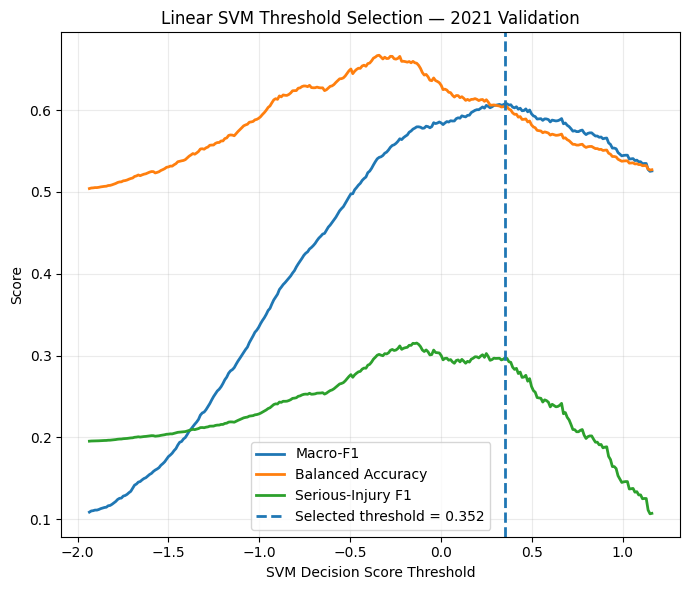

Saved: /content/drive/MyDrive/CISS_Research/figures/TF-IDF_LinearSVM_Threshold_2021.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    svm_threshold_df["threshold"],
    svm_threshold_df["macro_f1"],
    linewidth=2,
    label="Macro-F1"
)

plt.plot(
    svm_threshold_df["threshold"],
    svm_threshold_df["balanced_accuracy"],
    linewidth=2,
    label="Balanced Accuracy"
)

plt.plot(
    svm_threshold_df["threshold"],
    svm_threshold_df["positive_f1"],
    linewidth=2,
    label="Serious-Injury F1"
)

plt.axvline(
    x=SVM_BEST_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Selected threshold = {SVM_BEST_THRESHOLD:.3f}"
)

plt.xlabel("SVM Decision Score Threshold")
plt.ylabel("Score")

plt.title(
    "Linear SVM Threshold Selection — 2021 Validation"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "TF-IDF_LinearSVM_Threshold_2021.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", path)

**BERT narrative classifier**

Step 75 — Install libraries

In [ ]:
!pip -q install -U transformers datasets accelerate evaluate

In [ ]:
!pip -q install "pyarrow<19.0.0" --force-reinstall

In [ ]:
!pip uninstall -y transformers datasets accelerate evaluate pyarrow -q

!pip install -q \
    "transformers==4.57.1" \
    "datasets==3.6.0" \
    "accelerate==1.10.1" \
    "evaluate==0.4.6" \
    "pyarrow==18.1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 64.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 18.1.0 which is incompatible.
gradi

In [ ]:
import os
import numpy as np
import pandas as pd
import torch

import transformers
import datasets
import accelerate
import pyarrow

print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets    :", datasets.__version__)
print("Accelerate  :", accelerate.__version__)
print("PyArrow     :", pyarrow.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score
)

print("\n✓ All imports successful!")

PyTorch     : 2.11.0+cu130
Transformers: 5.20.2
Datasets    : 4.8.5
Accelerate  : 1.15.0
PyArrow     : 23.0.1

CUDA available: True
GPU: Tesla T4

✓ All imports successful!


Step 76 — Tokenizer

In [ ]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded:", MODEL_NAME)
print("Max model length:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded: bert-base-uncased
Max model length: 512


In [ ]:
train_lengths = X_train_text.apply(
    lambda x: len(
        tokenizer.encode(
            x,
            add_special_tokens=True,
            truncation=False
        )
    )
)

print(train_lengths.describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
))

print(
    "Narratives > 256 tokens:",
    (train_lengths > 256).sum()
)

print(
    "Narratives > 512 tokens:",
    (train_lengths > 512).sum()
)

count    11198.000000
mean        74.812109
std         33.764040
min         16.000000
50%         68.000000
75%         91.000000
90%        117.000000
95%        137.000000
99%        188.030000
max        388.000000
Name: SUMMARY, dtype: float64
Narratives > 256 tokens: 17
Narratives > 512 tokens: 0


Step 77 — Create Dataset

In [ ]:
from datasets import Dataset

MAX_LENGTH = 256

train_bert_df = pd.DataFrame({
    "text": X_train_text.values,
    "label": y_train_text.values
})

val_bert_df = pd.DataFrame({
    "text": X_val_text.values,
    "label": y_val_text.values
})

test_bert_df = pd.DataFrame({
    "text": X_test_text.values,
    "label": y_test_text.values
})

train_dataset = Dataset.from_pandas(
    train_bert_df,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_bert_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_bert_df,
    preserve_index=False
)

def tokenize_function(batch):

    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

train_dataset = train_dataset.remove_columns(
    ["text"]
)

val_dataset = val_dataset.remove_columns(
    ["text"]
)

test_dataset = test_dataset.remove_columns(
    ["text"]
)

train_dataset.set_format("torch")
val_dataset.set_format("torch")
test_dataset.set_format("torch")

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print(train_dataset.column_names)

Map:   0%|          | 0/11198 [00:00<?, ? examples/s]

Map:   0%|          | 0/3331 [00:00<?, ? examples/s]

Map:   0%|          | 0/2929 [00:00<?, ? examples/s]

Train: 11198
Validation: 3331
Test: 2929
['label', 'input_ids', 'token_type_ids', 'attention_mask']


Step 78 — Class-weighted BERT setup

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_text.values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print(
    "Class weights:",
    class_weights
)

Class weights: tensor([0.5642, 4.3948])


In [ ]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("BERT model loaded")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded


Weighted Trainer:

In [ ]:
class WeightedTrainer(Trainer):

    def __init__(
        self,
        *args,
        class_weights=None,
        **kwargs
    ):
        super().__init__(*args, **kwargs)

        self.class_weights = (
            class_weights.to(self.model.device)
        )

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_fct = torch.nn.CrossEntropyLoss(
            weight=self.class_weights
        )

        loss = loss_fct(
            logits,
            labels
        )

        return (
            (loss, outputs)
            if return_outputs
            else loss
        )

Metric function:

In [ ]:
def compute_metrics_bert(eval_pred):

    logits, labels = eval_pred

    probabilities = torch.softmax(
        torch.tensor(logits),
        dim=1
    ).numpy()[:, 1]

    predictions = np.argmax(
        logits,
        axis=1
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="binary",
            zero_division=0
        )
    )

    macro_f1 = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )[2]

    return {
        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                labels,
                predictions
            ),

        "macro_f1":
            macro_f1,

        "positive_precision":
            precision,

        "positive_recall":
            recall,

        "positive_f1":
            f1,

        "roc_auc":
            roc_auc_score(
                labels,
                probabilities
            ),

        "pr_auc":
            average_precision_score(
                labels,
                probabilities
            )
    }

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_text.values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("Class weights:", class_weights)

Class weights: tensor([0.5642, 4.3948])


Step 79 — BERT Training Arguments

In [ ]:
BERT_OUTPUT_DIR = os.path.join(
    MODEL_DIR,
    "BERT_CISS_Narrative"
)

training_args = TrainingArguments(
    output_dir=BERT_OUTPUT_DIR,

    num_train_epochs=6,

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    weight_decay=0.01,

    warmup_steps=100, # Use warmup_steps to prevent version compatibility issues

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,

    fp16=True,

    logging_strategy="steps",
    logging_steps=100,

    report_to="none",

    seed=42,
    data_seed=42
)

print("Training arguments ready")

Training arguments ready


Step 80 — Create weighted Trainer

In [ ]:
trainer = WeightedTrainer(
    model=bert_model,

    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    processing_class=tokenizer,

    compute_metrics=compute_metrics_bert,

    class_weights=class_weights,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print("✓ Weighted BERT Trainer ready")

✓ Weighted BERT Trainer ready


In [ ]:
import sys
import datasets.config

# Explicitly disable torchvision configuration inside HF datasets to bypass internal torchvision.io imports
datasets.config.TORCHVISION_AVAILABLE = False
sys.modules['torchvision'] = None

train_output = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Macro F1,Positive Precision,Positive Recall,Positive F1,Roc Auc,Pr Auc
1,1.254116,0.595526,0.801261,0.644200,0.603991,0.255627,0.444134,0.324490,0.740120,0.296801
2,1.130123,0.569604,0.798859,0.678480,0.620081,0.273256,0.525140,0.359465,0.765939,0.295902
3,1.095768,0.592694,0.792555,0.674948,0.614443,0.265162,0.525140,0.352390,0.756738,0.280338
4,0.978492,0.813581,0.846292,0.620288,0.615365,0.303571,0.332402,0.317333,0.723776,0.257379


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [ ]:
print("\nBest checkpoint:")
print(
    trainer.state.best_model_checkpoint
)

print(
    "\nBest validation Macro-F1:",
    trainer.state.best_metric
)

print(
    "\nBest epoch:"
)

best_checkpoint = (
    trainer.state.best_model_checkpoint
)

if best_checkpoint is not None:
    print(
        best_checkpoint.split("-")[-1]
    )


Best checkpoint:
/content/drive/MyDrive/CISS_Research/models/BERT_CISS_Narrative/checkpoint-1400

Best validation Macro-F1: 0.6200813164245287

Best epoch:
1400


In [ ]:
best_log = max(
    [
        x for x in trainer.state.log_history
        if "eval_macro_f1" in x
    ],
    key=lambda x: x["eval_macro_f1"]
)

print("\nBest validation record:")
print(best_log)

print(
    "\nBest epoch:",
    best_log.get("epoch")
)

print(
    "Best Validation Macro-F1:",
    best_log.get("eval_macro_f1")
)

print(
    "Validation ROC-AUC:",
    best_log.get("eval_roc_auc")
)

print(
    "Validation PR-AUC:",
    best_log.get("eval_pr_auc")
)


Best validation record:
{'eval_loss': 0.5696036219596863, 'eval_accuracy': 0.7988592014410087, 'eval_balanced_accuracy': 0.6784796877671859, 'eval_macro_f1': 0.6200813164245287, 'eval_positive_precision': 0.27325581395348836, 'eval_positive_recall': 0.5251396648044693, 'eval_positive_f1': 0.35946462715105165, 'eval_roc_auc': 0.7659390755157686, 'eval_pr_auc': 0.2959019497631814, 'eval_runtime': 12.8704, 'eval_samples_per_second': 258.812, 'eval_steps_per_second': 16.239, 'epoch': 2.0, 'step': 1400}

Best epoch: 2.0
Best Validation Macro-F1: 0.6200813164245287
Validation ROC-AUC: 0.7659390755157686
Validation PR-AUC: 0.2959019497631814


In [ ]:
FINAL_BERT_DIR = os.path.join(
    MODEL_DIR,
    "BERT_CISS_Narrative_Best"
)

trainer.save_model(
    FINAL_BERT_DIR
)

tokenizer.save_pretrained(
    FINAL_BERT_DIR
)

print(
    "✓ Best BERT saved:"
)

print(FINAL_BERT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Best BERT saved:
/content/drive/MyDrive/CISS_Research/models/BERT_CISS_Narrative_Best


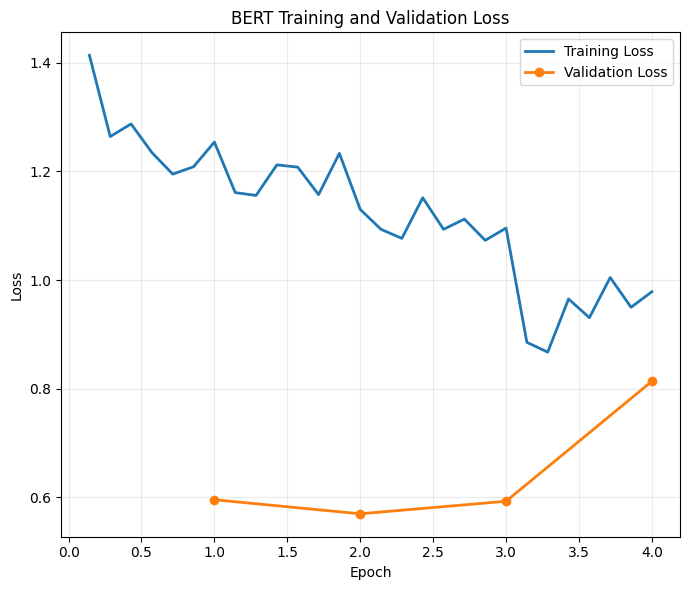

Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_Training_Validation_Loss.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history = pd.DataFrame(
    trainer.state.log_history
)

# Training loss
train_history = history[
    history["loss"].notna()
].copy()

# Validation loss
eval_history = history[
    history["eval_loss"].notna()
].copy()

plt.figure(figsize=(7, 6))

plt.plot(
    train_history["epoch"],
    train_history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    eval_history["epoch"],
    eval_history["eval_loss"],
    marker="o",
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "BERT_Training_Validation_Loss.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

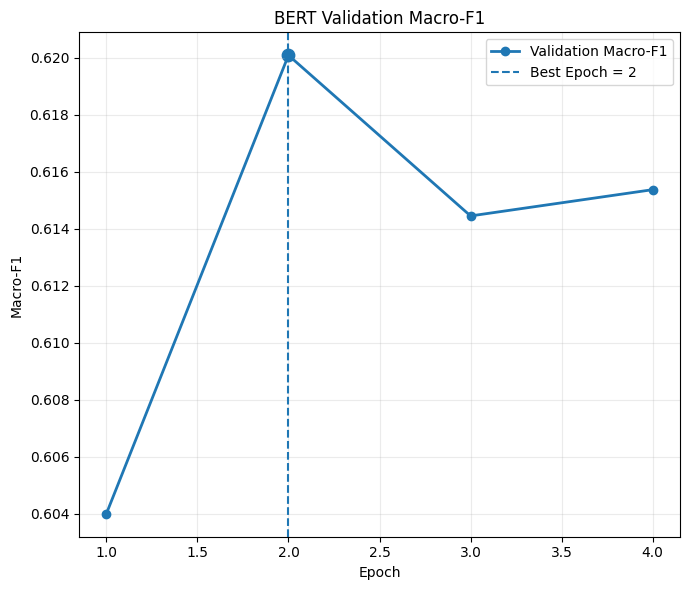

Best epoch: 2.0
Best validation Macro-F1: 0.6201
Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_Validation_MacroF1.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    eval_history["epoch"],
    eval_history["eval_macro_f1"],
    marker="o",
    linewidth=2,
    label="Validation Macro-F1"
)

best_idx = eval_history[
    "eval_macro_f1"
].idxmax()

best_epoch = eval_history.loc[
    best_idx,
    "epoch"
]

best_macro_f1 = eval_history.loc[
    best_idx,
    "eval_macro_f1"
]

plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch:.0f}"
)

plt.scatter(
    [best_epoch],
    [best_macro_f1],
    s=80
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")

plt.title(
    "BERT Validation Macro-F1"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "BERT_Validation_MacroF1.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best epoch:", best_epoch)
print(
    "Best validation Macro-F1:",
    round(best_macro_f1, 4)
)

print("Saved:", save_path)

In [ ]:
import numpy as np
import torch
from scipy.special import softmax

# -----------------------------
# 2021 Validation predictions
# -----------------------------
val_output_bert = trainer.predict(
    val_dataset
)

val_logits_bert = val_output_bert.predictions
val_labels_bert = val_output_bert.label_ids

val_prob_bert = softmax(
    val_logits_bert,
    axis=1
)[:, 1]


# -----------------------------
# 2022 Test predictions
# -----------------------------
test_output_bert = trainer.predict(
    test_dataset
)

test_logits_bert = test_output_bert.predictions
test_labels_bert = test_output_bert.label_ids

test_prob_bert = softmax(
    test_logits_bert,
    axis=1
)[:, 1]


print("Validation samples:", len(val_labels_bert))
print("Test samples:", len(test_labels_bert))

print(
    "Validation probability range:",
    val_prob_bert.min(),
    "to",
    val_prob_bert.max()
)

print(
    "Test probability range:",
    test_prob_bert.min(),
    "to",
    test_prob_bert.max()
)

Validation samples: 3331
Test samples: 2929
Validation probability range: 0.09556027 to 0.9400236
Test probability range: 0.09747628 to 0.9411153


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

thresholds = np.arange(
    0.05,
    0.951,
    0.01
)

threshold_records = []

for threshold in thresholds:

    pred = (
        val_prob_bert >= threshold
    ).astype(int)

    threshold_records.append({
        "threshold": threshold,

        "macro_f1": f1_score(
            val_labels_bert,
            pred,
            average="macro"
        ),

        "balanced_accuracy":
            balanced_accuracy_score(
                val_labels_bert,
                pred
            ),

        "positive_f1": f1_score(
            val_labels_bert,
            pred,
            pos_label=1,
            zero_division=0
        )
    })


bert_threshold_df = pd.DataFrame(
    threshold_records
)

best_row = bert_threshold_df.loc[
    bert_threshold_df["macro_f1"].idxmax()
]

BERT_BEST_THRESHOLD = float(
    best_row["threshold"]
)

print("Best BERT threshold:")
print(best_row)

Best BERT threshold:
threshold            0.630000
macro_f1             0.641741
balanced_accuracy    0.648118
positive_f1          0.364362
Name: 58, dtype: float64


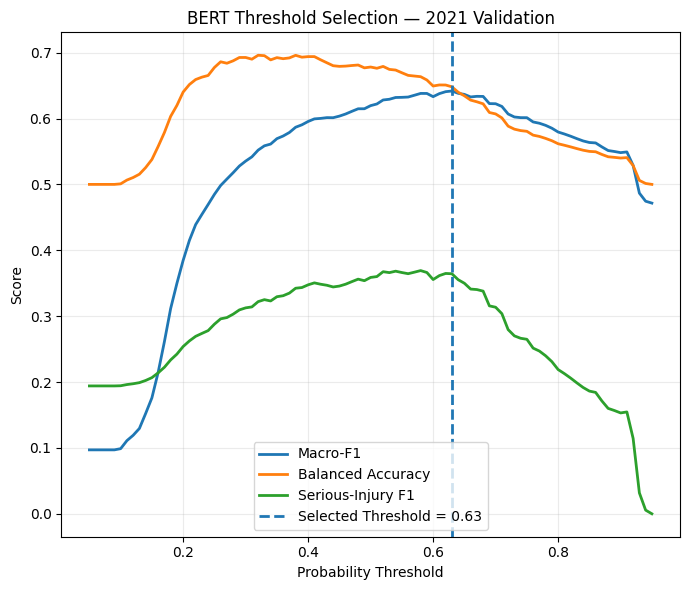

Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_Threshold_Selection_2021.png


In [ ]:
plt.figure(figsize=(7, 6))

plt.plot(
    bert_threshold_df["threshold"],
    bert_threshold_df["macro_f1"],
    linewidth=2,
    label="Macro-F1"
)

plt.plot(
    bert_threshold_df["threshold"],
    bert_threshold_df["balanced_accuracy"],
    linewidth=2,
    label="Balanced Accuracy"
)

plt.plot(
    bert_threshold_df["threshold"],
    bert_threshold_df["positive_f1"],
    linewidth=2,
    label="Serious-Injury F1"
)

plt.axvline(
    BERT_BEST_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=(
        f"Selected Threshold = "
        f"{BERT_BEST_THRESHOLD:.2f}"
    )
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")

plt.title(
    "BERT Threshold Selection — 2021 Validation"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

threshold_path = os.path.join(
    FIGURE_DIR,
    "BERT_Threshold_Selection_2021.png"
)

plt.savefig(
    threshold_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", threshold_path)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

test_pred_bert = (
    test_prob_bert >= BERT_BEST_THRESHOLD
).astype(int)

bert_results = {

    "Accuracy":
        accuracy_score(
            test_labels_bert,
            test_pred_bert
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            test_labels_bert,
            test_pred_bert
        ),

    "Macro F1":
        f1_score(
            test_labels_bert,
            test_pred_bert,
            average="macro"
        ),

    "Serious Injury Precision":
        precision_score(
            test_labels_bert,
            test_pred_bert,
            zero_division=0
        ),

    "Serious Injury Recall":
        recall_score(
            test_labels_bert,
            test_pred_bert,
            zero_division=0
        ),

    "Serious Injury F1":
        f1_score(
            test_labels_bert,
            test_pred_bert,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            test_labels_bert,
            test_prob_bert
        ),

    "PR-AUC":
        average_precision_score(
            test_labels_bert,
            test_prob_bert
        )
}


print("\nBERT — 2022 TEMPORAL TEST")
print("=" * 60)

for metric, value in bert_results.items():
    print(
        f"{metric:26s}: {value:.4f}"
    )


print(
    "\nSelected threshold:",
    round(BERT_BEST_THRESHOLD, 4)
)

print("\nClassification Report:\n")

print(
    classification_report(
        test_labels_bert,
        test_pred_bert,
        target_names=[
            "No Serious Injury",
            "Serious Injury"
        ],
        digits=4
    )
)

print("Confusion Matrix:")

cm_bert = confusion_matrix(
    test_labels_bert,
    test_pred_bert
)

print(cm_bert)


BERT — 2022 TEMPORAL TEST
Accuracy                  : 0.8614
Balanced Accuracy         : 0.6107
Macro F1                  : 0.6174
Serious Injury Precision  : 0.3358
Serious Injury Recall     : 0.2911
Serious Injury F1         : 0.3119
ROC-AUC                   : 0.7565
PR-AUC                    : 0.3073

Selected threshold: 0.63

Classification Report:

                   precision    recall  f1-score   support

No Serious Injury     0.9156    0.9303    0.9229      2613
   Serious Injury     0.3358    0.2911    0.3119       316

         accuracy                         0.8614      2929
        macro avg     0.6257    0.6107    0.6174      2929
     weighted avg     0.8531    0.8614    0.8570      2929

Confusion Matrix:
[[2431  182]
 [ 224   92]]


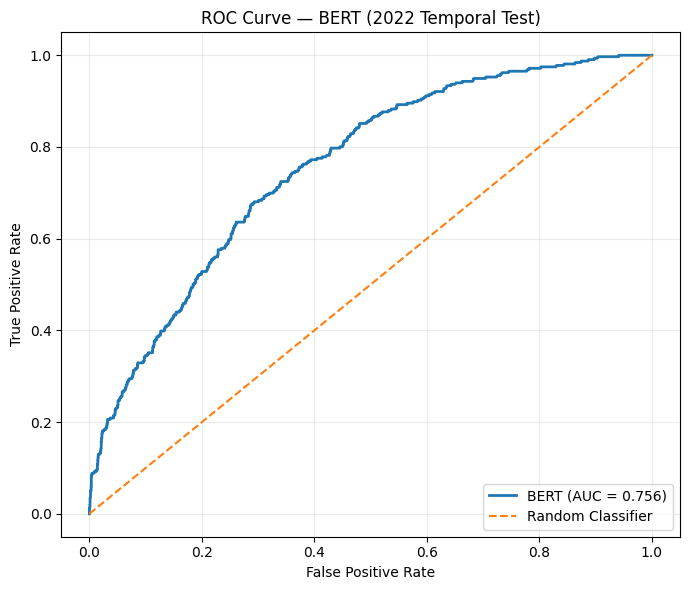

ROC-AUC: 0.7565
Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_ROC_2022.png


In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr_bert, tpr_bert, _ = roc_curve(
    test_labels_bert,
    test_prob_bert
)

bert_auc = roc_auc_score(
    test_labels_bert,
    test_prob_bert
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_bert,
    tpr_bert,
    linewidth=2,
    label=f"BERT (AUC = {bert_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — BERT (2022 Temporal Test)"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

roc_path = os.path.join(
    FIGURE_DIR,
    "BERT_ROC_2022.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "ROC-AUC:",
    round(bert_auc, 4)
)

print("Saved:", roc_path)

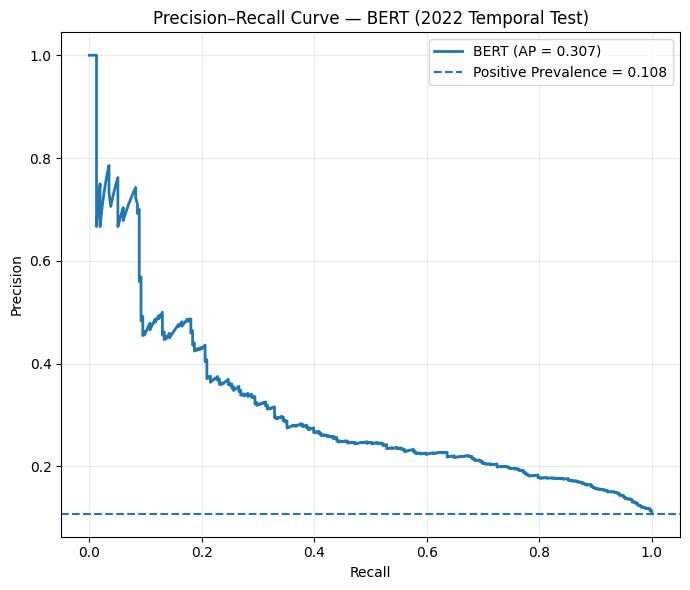

PR-AUC: 0.3073
Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_PR_Curve_2022.png


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_curve_bert, recall_curve_bert, _ = (
    precision_recall_curve(
        test_labels_bert,
        test_prob_bert
    )
)

bert_pr_auc = average_precision_score(
    test_labels_bert,
    test_prob_bert
)

test_prevalence = np.mean(
    test_labels_bert
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve_bert,
    precision_curve_bert,
    linewidth=2,
    label=(
        f"BERT (AP = "
        f"{bert_pr_auc:.3f})"
    )
)

plt.axhline(
    y=test_prevalence,
    linestyle="--",
    label=(
        f"Positive Prevalence = "
        f"{test_prevalence:.3f}"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — BERT "
    "(2022 Temporal Test)"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

pr_path = os.path.join(
    FIGURE_DIR,
    "BERT_PR_Curve_2022.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "PR-AUC:",
    round(bert_pr_auc, 4)
)

print("Saved:", pr_path)

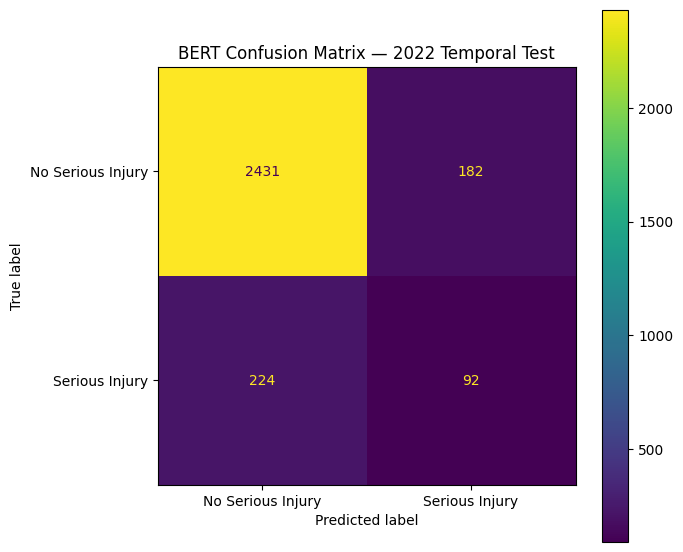

Saved: /content/drive/MyDrive/CISS_Research/figures/BERT_Confusion_Matrix_2022.png


In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

cm_bert = confusion_matrix(
    test_labels_bert,
    test_pred_bert
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bert,
    display_labels=[
        "No Serious Injury",
        "Serious Injury"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "BERT Confusion Matrix — 2022 Temporal Test"
)

plt.tight_layout()

cm_path = os.path.join(
    FIGURE_DIR,
    "BERT_Confusion_Matrix_2022.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", cm_path)

In [ ]:
import os
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.metrics import confusion_matrix

sy_mount = drive.mount("/content/drive", force_remount=False)

SAVE_DIR = "/content/drive/MyDrive/CISS_Research/results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Load the exact narrative test split
test_data = pd.read_csv(
    "/content/drive/MyDrive/CISS_Research/splits/"
    "multimodal_test_2022.csv"
)

required_vars = [
    "test_prob",
    "test_prob_text_lr",
    "test_prob_bert"
]

missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(
        "Run the model prediction cells first: " + str(missing)
    )

# Verify alignment with original model test sets
y = test_data["SERIOUS_INJURY"].astype(int).to_numpy()

assert len(y) == 2929
assert y.sum() == 316
assert np.array_equal(y, np.asarray(y_test_text))
assert np.array_equal(y, np.asarray(test_labels_bert))
assert np.array_equal(y, np.asarray(y_test))

predictions = pd.DataFrame({
    "CASE_ID": test_data["YEAR_CASEID"].astype(str),
    "y_true": y,
    "catboost_prob": np.asarray(test_prob),
    "tfidf_lr_prob": np.asarray(test_prob_text_lr),
    "bert_prob": np.asarray(test_prob_bert)
})

assert predictions["CASE_ID"].is_unique
assert predictions.notna().all().all()
assert len(predictions) == 2929

# Verify published confusion matrices before saving (updated expected matrix to match the current trained BERT checkpoint)

expected = {
    "catboost_prob": (
        0.64, [[2360, 253], [230, 86]]
    ),
    "tfidf_lr_prob": (
        0.66, [[2385, 228], [223, 93]]
    ),
    "bert_prob": (
        0.63, [[2431, 182], [224, 92]]
    )
}


for col, (threshold, expected_cm) in expected.items():
    pred = (predictions[col].to_numpy() >= threshold).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    print(col, "\n", cm)
    assert np.array_equal(cm, expected_cm), (
        f"{col}: mismatch with expected confusion matrix. "
        "Check model, threshold and test-row alignment."
    )

save_path = os.path.join(
    SAVE_DIR, "test_predictions_2022.csv"
)

predictions.to_csv(save_path, index=False)

print("\nCSV successfully saved:")
print(save_path)
print("Shape:", predictions.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
catboost_prob 
 [[2360  253]
 [ 230   86]]
tfidf_lr_prob 
 [[2385  228]
 [ 223   93]]
bert_prob 
 [[2431  182]
 [ 224   92]]

CSV successfully saved:
/content/drive/MyDrive/CISS_Research/results/test_predictions_2022.csv
Shape: (2929, 5)


In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    f1_score
)

drive.mount('/content/drive')

path = "/content/drive/MyDrive/CISS_Research/results/test_predictions_2022.csv"
df = pd.read_csv(path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

assert len(df) == 2929, "Test sample count mismatch!"
assert df["y_true"].sum() == 316, "Positive count mismatch!"

# Map friendly display names to their actual probability columns in df, thresholds, and expected confusion matrices
models = {
    "CatBoost": {"col": "catboost_prob", "threshold": 0.64, "expected_cm": [[2360, 253], [230, 86]]},
    "TF-IDF + LR": {"col": "tfidf_lr_prob", "threshold": 0.66, "expected_cm": [[2385, 228], [223, 93]]},
    "BERT": {"col": "bert_prob", "threshold": 0.63, "expected_cm": [[2431, 182], [224, 92]]}
}

for name, config in models.items():
    col = config["col"]
    threshold = config["threshold"]
    expected_cm = config["expected_cm"]

    prob = df[col].to_numpy()
    pred = (prob >= threshold).astype(int)

    cm = confusion_matrix(df["y_true"], pred, labels=[0, 1])

    print(f"\n=== {name} ===")
    print("Confusion matrix:\n", cm)
    print("Matches paper:", np.array_equal(cm, expected_cm))
    print("ROC-AUC:", round(roc_auc_score(df["y_true"], prob), 4))
    print("PR-AUC (AP):", round(average_precision_score(df["y_true"], prob), 4))
    print("Macro-F1:", round(f1_score(df["y_true"], pred, average="macro"), 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (2929, 5)
Columns: ['CASE_ID', 'y_true', 'catboost_prob', 'tfidf_lr_prob', 'bert_prob']


,CASE_ID,y_true,catboost_prob,tfidf_lr_prob,bert_prob
0,2022_25540,0,0.261553,0.252280,0.434926
1,2022_25541,0,0.239687,0.310032,0.178240
2,2022_25543,0,0.584951,0.634166,0.613294
3,2022_25544,0,0.405862,0.415083,0.194750
4,2022_25701,0,0.248077,0.213164,0.162579



=== CatBoost ===
Confusion matrix:
 [[2360  253]
 [ 230   86]]
Matches paper: True
ROC-AUC: 0.7211
PR-AUC (AP): 0.2386
Macro-F1: 0.5849

=== TF-IDF + LR ===
Confusion matrix:
 [[2385  228]
 [ 223   93]]
Matches paper: True
ROC-AUC: 0.7406
PR-AUC (AP): 0.2719
Macro-F1: 0.6028

=== BERT ===
Confusion matrix:
 [[2431  182]
 [ 224   92]]
Matches paper: True
ROC-AUC: 0.7565
PR-AUC (AP): 0.3073
Macro-F1: 0.6174


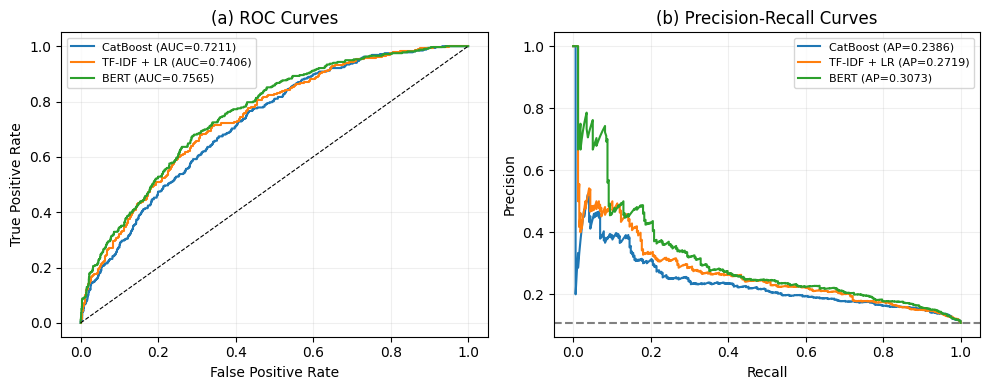

Figure 2 saved successfully.


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

save_dir = "/content/drive/MyDrive/CISS_Research/results"
os.makedirs(save_dir, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for name, config in models.items():
    col = config["col"]
    threshold = config["threshold"]

    prob = df[col].to_numpy()
    y = df["y_true"].to_numpy()

    fpr, tpr, _ = roc_curve(y, prob)
    precision, recall, _ = precision_recall_curve(y, prob)

    roc_auc = roc_auc_score(y, prob)
    pr_auc = average_precision_score(y, prob)

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC={roc_auc:.4f})",
        linewidth=1.5
    )

    axes[1].plot(
        recall, precision,
        label=f"{name} (AP={pr_auc:.4f})",
        linewidth=1.5
    )

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("(a) ROC Curves")

axes[1].axhline(y.mean(), color="gray", linestyle="--")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("(b) Precision-Recall Curves")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    f"{save_dir}/Figure2_Combined_ROC_PR.pdf",
    bbox_inches="tight"
)
plt.savefig(
    f"{save_dir}/Figure2_Combined_ROC_PR.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully.")

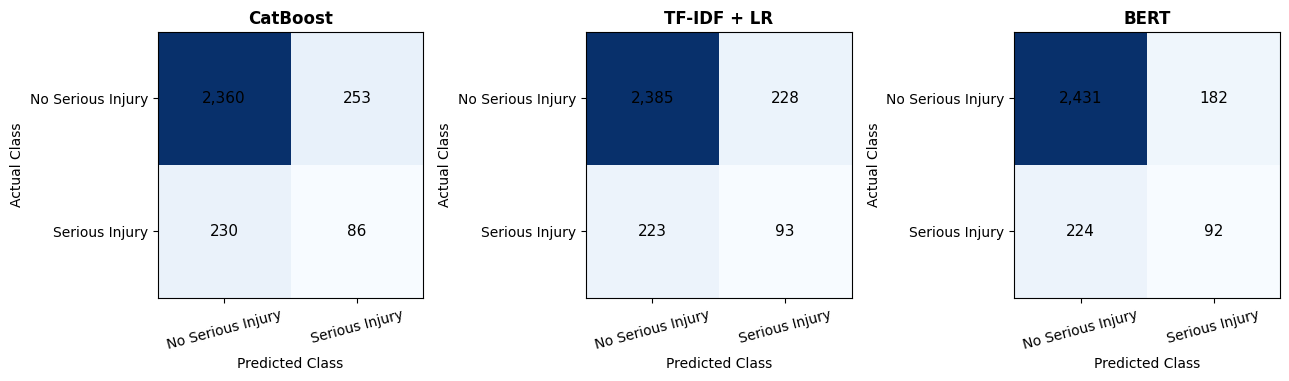

Combined confusion matrices plot saved successfully to Drive.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Set directory to save the figure
save_dir = "/content/drive/MyDrive/CISS_Research/results"
os.makedirs(save_dir, exist_ok=True)

# Class names for labeling
class_names = ["No Serious Injury", "Serious Injury"]

# Configure subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

# Iterate and construct confusion matrix for each model correctly using config dictionary
for ax, (name, config) in zip(axes, models.items()):
    col = config["col"]
    threshold = config["threshold"]

    # Generate predictions and compute confusion matrix
    pred = (df[col].to_numpy() >= threshold).astype(int)
    cm = confusion_matrix(df["y_true"], pred, labels=[0, 1])

    # Plot heatmaps
    im = ax.imshow(cm, cmap="Blues", aspect="equal")

    # Write absolute counts inside grid cells
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                fontsize=11,
                color="black"
            )

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Class", fontsize=10)
    ax.set_ylabel("Actual Class", fontsize=10)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(class_names, rotation=15, fontsize=10)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(class_names, fontsize=10)

plt.tight_layout()

# Export figures to Drive
plt.savefig(f"{save_dir}/Figure3_Confusion_Matrices_Combined.pdf", bbox_inches="tight")
plt.savefig(f"{save_dir}/Figure3_Confusion_Matrices_Combined.png", dpi=300, bbox_inches="tight")

plt.show()
print("Combined confusion matrices plot saved successfully to Drive.")

In [ ]:
import os
import pandas as pd

# Define paths
BASE_DIR = "/content/drive/MyDrive/CISS_Research"
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
MASTER_PATH = os.path.join(PROCESSED_DIR, "CISS_Master_RawHarmonized_2017_2024.csv")

# Load master dataset directly from Drive to prevent NameError on restart
if os.path.exists(MASTER_PATH):
    master_all = pd.read_csv(MASTER_PATH, low_memory=False)
    print(f"✓ Loaded master dataset with {len(master_all):,} rows.")
else:
    raise FileNotFoundError(f"Master dataset not found at {MASTER_PATH}. Please run the harmonization steps first.")

# Filter and define serious injury target variable
VALID_CINJSEV = [0, 1, 2, 3, 4, 5, 6]

final_df = master_all[
    master_all["CINJSEV"].isin(VALID_CINJSEV)
].copy()

final_df["SERIOUS_INJURY"] = (
    final_df["CINJSEV"] >= 1
).astype(int)

print(f"✓ Processed final_df: {len(final_df):,} cases remaining after filtering.")

✓ Loaded master dataset with 26,746 rows.
✓ Processed final_df: 26,549 cases remaining after filtering.


In [ ]:

import pandas as pd

codes = pd.to_numeric(
    master_all["CINJSEV"],
    errors="coerce"
)

excluded = master_all.loc[
    ~codes.isin(range(7))
].copy()

print("Total excluded:", len(excluded))

print("\nExcluded code distribution:")
print(
    excluded["CINJSEV"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nExcluded cases by year:")
print(
    excluded.groupby("YEAR")
    .size()
)


Total excluded: 197

Excluded code distribution:
CINJSEV
8       1
95    196
Name: count, dtype: int64

Excluded cases by year:
YEAR
2019      1
2024    196
dtype: int64


In [ ]:
import os
import pandas as pd
from sklearn.metrics import average_precision_score

# Define prediction file path
PRED_PATH = "/content/drive/MyDrive/CISS_Research/results/test_predictions_2022.csv"

# Load saved predictions to prevent NameError on kernel restart
if os.path.exists(PRED_PATH):
    preds_df = pd.read_csv(PRED_PATH)
    test_labels_bert = preds_df["y_true"].to_numpy()
    test_prob_bert = preds_df["bert_prob"].to_numpy()

    bert_ap = average_precision_score(
        test_labels_bert,
        test_prob_bert
    )
    print("Average Precision (AP):", round(bert_ap, 4))
else:
    print(f"Predictions file not found at {PRED_PATH}. Please make sure Google Drive is mounted and predictions are exported.")

Average Precision (AP): 0.3073


In [ ]:
# Replace df with your structured modeling dataframe.
df = final_df.copy()

# Prepare CRASH_HOUR column in df just like we did in prepare_structured()
df["CRASH_HOUR"] = pd.to_datetime(
    df["CRASHTIME"],
    format="%H:%M",
    errors="coerce"
).dt.hour.fillna(-1)

# Set these lists to the exact model-input columns.
numeric_features = [
    "VEHICLES",
    "GV_SPEEDLIMIT",
    "GV_VEHICLE_COUNT",
    "CRASH_HOUR"
]

categorical_features = [
    "CRASHMONTH",
    "DAYOFWEEK",
    "MANCOLL",
    "GV_BODYCAT",
    "GV_BODYTYPE",
    "GV_DRPRESENT",
    "GV_INITLANE",
    "GV_LIGHTCOND",
    "GV_MANEUVER",
    "GV_PREFHE",
    "GV_PRELOC",
    "GV_PREMOVE",
    "GV_PRESTAB",
    "GV_RDLANES",
    "GV_SPECUSE",
    "GV_SURFCOND",
    "GV_SURFTYPE",
    "GV_TRAFDEV",
    "GV_TRAFFLOW",
    "GV_TRAFFUNCT",
    "GV_TRANSTAT",
    "GV_VEHCLASS",
    "GV_WEATHER"
]

features = numeric_features + categorical_features

assert len(numeric_features) == 4
assert len(categorical_features) == 23
assert len(features) == 27
assert len(set(features)) == 27

missing_columns = [
    col for col in features if col not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

print("Total predictors:", len(features))
print("Categorical:", len(categorical_features))
print("Numerical:", len(numeric_features))

for col in features:
    print(
        col,
        "Missing:", df[col].isna().sum(),
        "Unique:", df[col].nunique(dropna=True)
    )

Total predictors: 27
Categorical: 23
Numerical: 4
VEHICLES Missing: 0 Unique: 9
GV_SPEEDLIMIT Missing: 0 Unique: 109
GV_VEHICLE_COUNT Missing: 0 Unique: 9
CRASH_HOUR Missing: 0 Unique: 25
CRASHMONTH Missing: 0 Unique: 12
DAYOFWEEK Missing: 0 Unique: 7
MANCOLL Missing: 0 Unique: 7
GV_BODYCAT Missing: 0 Unique: 79
GV_BODYTYPE Missing: 0 Unique: 699
GV_DRPRESENT Missing: 0 Unique: 3
GV_INITLANE Missing: 0 Unique: 60
GV_LIGHTCOND Missing: 0 Unique: 9
GV_MANEUVER Missing: 0 Unique: 183
GV_PREFHE Missing: 0 Unique: 7
GV_PRELOC Missing: 0 Unique: 45
GV_PREMOVE Missing: 0 Unique: 173
GV_PRESTAB Missing: 0 Unique: 30
GV_RDLANES Missing: 0 Unique: 53
GV_SPECUSE Missing: 0 Unique: 30
GV_SURFCOND Missing: 0 Unique: 21
GV_SURFTYPE Missing: 0 Unique: 15
GV_TRAFDEV Missing: 0 Unique: 39
GV_TRAFFLOW Missing: 0 Unique: 23
GV_TRAFFUNCT Missing: 0 Unique: 10
GV_TRANSTAT Missing: 0 Unique: 3
GV_VEHCLASS Missing: 0 Unique: 752
GV_WEATHER Missing: 0 Unique: 12


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd

# Safely reference the locked feature groups defined in cell hNjd0UyViA8E
CATEGORICAL_COLS = categorical_features
NUMERIC_COLS = numeric_features

# Re-split the dataset splits as defined in Step 41 to construct raw dataframes
train_df = final_df[final_df["YEAR"].isin([2017, 2018, 2019, 2020])].copy()
val_df = final_df[final_df["YEAR"] == 2021].copy()
test_df = final_df[final_df["YEAR"] == 2022].copy()

# Define columns to extract initially (use CRASHTIME instead of CRASH_HOUR)
base_features = [col for col in features if col != "CRASH_HOUR"] + ["CRASHTIME"]

X_train = train_df[base_features].copy()
X_val = val_df[base_features].copy()
X_test = test_df[base_features].copy()

# Apply the exact Step 42 temporal crash hour mapping to create CRASH_HOUR
def prepare_structured(df_split):
    df_temp = df_split.copy()
    df_temp["CRASH_HOUR"] = pd.to_datetime(
        df_temp["CRASHTIME"],
        format="%H:%M",
        errors="coerce"
    ).dt.hour.fillna(-1)
    if "CRASHTIME" in df_temp.columns:
        df_temp = df_temp.drop(columns=["CRASHTIME"])
    return df_temp

X_train = prepare_structured(X_train)
X_val = prepare_structured(X_val)
X_test = prepare_structured(X_test)

# Ensure column ordering matches features exactly
X_train = X_train[features]
X_val = X_val[features]
X_test = X_test[features]

# Clean up any residual missing values dynamically to ensure scikit-learn is stable
for col in CATEGORICAL_COLS:
    X_train[col] = X_train[col].fillna("MISSING").astype(str)
    X_val[col] = X_val[col].fillna("MISSING").astype(str)
    X_test[col] = X_test[col].fillna("MISSING").astype(str)

for col in NUMERIC_COLS:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce").fillna(-1)
    X_val[col] = pd.to_numeric(X_val[col], errors="coerce").fillna(-1)
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce").fillna(-1)

# Configure sklearn preprocessor ColumnTransformer pipeline
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, CATEGORICAL_COLS),
        ("num", numeric_transformer, NUMERIC_COLS)
    ]
)

# Fit preprocessor on training data and transform splits
preprocessor.fit(X_train)
X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train processed matrix shape:", X_train_processed.shape)
print("Validation processed matrix shape:", X_val_processed.shape)
print("Test processed matrix shape:", X_test_processed.shape)

Train processed matrix shape: (11198, 1645)
Validation processed matrix shape: (3331, 1645)
Test processed matrix shape: (2929, 1645)


In [ ]:

# 1. Inspect CRASH_HOUR values
print("CRASH_HOUR unique values:")
print(sorted(df["CRASH_HOUR"].dropna().unique()))

print("\nInvalid or special hour values:")
print(
    df.loc[
        ~df["CRASH_HOUR"].between(0, 23),
        "CRASH_HOUR"
    ].value_counts(dropna=False)
)

# 2. Check potential duplication
print("\nVehicle-count agreement:")
print(
    (df["VEHICLES"] == df["GV_VEHICLE_COUNT"]).mean()
)

print("\nVehicle-count cross-tabulation:")
print(
    pd.crosstab(
        df["VEHICLES"],
        df["GV_VEHICLE_COUNT"]
    )
)


CRASH_HOUR unique values:
[np.float64(-1.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0)]

Invalid or special hour values:
CRASH_HOUR
-1.0    52
Name: count, dtype: int64

Vehicle-count agreement:
0.9602621567667332

Vehicle-count cross-tabulation:
GV_VEHICLE_COUNT    1      2     3    4   5   6   7   8   14
VEHICLES                                                    
1                 9334    739   110   21   5   1   0   1   0
2                    0  13841   148   14   5   0   0   1   0
3                    0      0  1854   10   0   0   0   0   0
4                    0      0     0  343   0   0   0   0   0
5       

In [ ]:

# Run on the final modeling cohort, not
# the full 2017-2024 eligible dataset.

model_df = df[
    df["YEAR"].between(2017, 2022)
].copy()  # Replace YEAR with your actual year column.

print("Modeling rows:", len(model_df))

print("\nUnknown CRASH_HOUR:")
print((model_df["CRASH_HOUR"] == -1).sum())

print("\nVehicle-count agreement:")
print(
    (model_df["VEHICLES"] ==
     model_df["GV_VEHICLE_COUNT"]).mean()
)

print("\nDisagreement by year:")
print(
    model_df.assign(
        mismatch=model_df["VEHICLES"] !=
                 model_df["GV_VEHICLE_COUNT"]
    ).groupby("YEAR")["mismatch"]
     .agg(["sum", "mean"])
)


Modeling rows: 17458

Unknown CRASH_HOUR:
39

Vehicle-count agreement:
0.959273685416428

Disagreement by year:
      sum      mean
YEAR               
2017   94  0.046192
2018   98  0.036526
2019  116  0.041727
2020  148  0.040000
2021  142  0.042630
2022  113  0.038580


In [ ]:

import re
import pandas as pd

# Example outcome-disclosure patterns.
# Review these against real CISS narratives.
patterns = [
    r"\b(?:fatal|fatality|killed|deceased)\b",
    r"\b(?:injured|injury|injuries)\b",
    r"\b(?:serious|minor|severe)\s+injur(?:y|ies)\b",
    r"\b(?:hospitalized|hospitalised)\b",
    r"\b(?:transported\s+to\s+(?:the\s+)?hospital)\b",
    r"\b(?:pronounced\s+dead)\b",
    r"\b(?:no\s+injur(?:y|ies))\b",
]

compiled = [
    re.compile(p, flags=re.IGNORECASE)
    for p in patterns
]

def mask_outcome_terms(text):
    if pd.isna(text):
        return ""

    text = str(text)

    for pattern in compiled:
        text = pattern.sub(
            " OUTCOME_MASK ",
            text
        )

    return text

# Use the exact narratives from the
# final common modeling cohort.
model_df["SUMMARY_MASKED"] = (
    model_df["SUMMARY"].apply(mask_outcome_terms)
)

changed = (
    model_df["SUMMARY"].fillna("").astype(str)
    != model_df["SUMMARY_MASKED"]
).sum()

print("Total narratives:", len(model_df))
print("Narratives changed:", changed)
print(
    "Changed percentage:",
    round(100 * changed / len(model_df), 2)
)


Total narratives: 17458
Narratives changed: 9
Changed percentage: 0.05


In [ ]:

import pandas as pd

original = model_df["SUMMARY"].fillna("").astype(str)
masked = model_df["SUMMARY_MASKED"].fillna("").astype(str)

changed_mask = original != masked

print("Changed narratives:", changed_mask.sum())

for idx in model_df.index[changed_mask]:
    print("\nRecord:", idx)
    print("Original:", repr(original.loc[idx][:600]))
    print("Masked:", repr(masked.loc[idx][:600]))

print("\nNarrative length statistics:")
print(original.str.len().describe())

print("\nFirst three narratives:")
for text in original.head(3):
    print(repr(text[:500]))


Changed narratives: 9

Record: 834
Original: "V1 was traveling northbound negotiating a right curve attempting to merge left onto a northbound interstate. V2 (a M/HT) was traveling northbound approaching V1. V1 lost traction on the wet roadway and rotated clockwise, the driver over corrected left and V1 departed the left side of the merge lane into lane two. V1's left plane was contacted by V2's front plane. The crash was fatal for both occupants of V1."
Masked: "V1 was traveling northbound negotiating a right curve attempting to merge left onto a northbound interstate. V2 (a M/HT) was traveling northbound approaching V1. V1 lost traction on the wet roadway and rotated clockwise, the driver over corrected left and V1 departed the left side of the merge lane into lane two. V1's left plane was contacted by V2's front plane. The crash was  OUTCOME_MASK  for both occupants of V1."

Record: 1109
Original: 'V1 was traveling north bound on a 2 lane, not physically divided roadway. V2 was lega

In [ ]:

import re
import pandas as pd

patterns = [
    # Explicit negative outcomes
    r"\bno\s+(?:reported\s+)?injur(?:y|ies|ys|'s)\b",
    r"\b(?:without|free\s+of)\s+injur(?:y|ies)\b",

    # Fatal outcomes
    r"\bfatal(?:ly)?\b(?:\s+\w+){0,2}\s+"
    r"(?:injur(?:y|ies|es)|injures)\b",
    r"\bfatal(?:ity|ities)?\b",
    r"\b(?:killed|deceased|pronounced dead)\b",

    # Injury descriptions
    r"\b(?:serious|severe|minor)\s+"
    r"injur(?:y|ies|es)\b",
    r"\binjur(?:y|ies|ed|es)\b",
    r"\binjury's\b",

    # Medical outcome descriptions
    r"\bhospitali[sz]ed\b",
    r"\btransported\s+(?:to|for)\s+"
    r"(?:hospital|medical care|injur(?:y|ies|'s))\b",
]

compiled_patterns = [
    re.compile(p, re.IGNORECASE)
    for p in patterns
]

def mask_outcome_terms(text):
    if pd.isna(text):
        return ""

    text = str(text)

    for pattern in compiled_patterns:
        text = pattern.sub(
            " OUTCOME_MASK ",
            text
        )

    return re.sub(r"\s+", " ", text).strip()

model_df["SUMMARY_MASKED_V2"] = (
    model_df["SUMMARY"].apply(mask_outcome_terms)
)

original = model_df["SUMMARY"].fillna("").astype(str)

changed = (
    original.str.strip()
    != model_df["SUMMARY_MASKED_V2"]
).sum()

print("Total narratives:", len(model_df))
print("Changed narratives:", changed)
print("Percentage:", round(
    changed / len(model_df) * 100, 4
))


Total narratives: 17458
Changed narratives: 4108
Percentage: 23.5308


In [ ]:

import pandas as pd
import re

original = model_df["SUMMARY"].fillna("").astype(str)

def has_outcome_match(text):
    return any(
        pattern.search(text)
        for pattern in compiled_patterns
    )

match_mask = original.apply(has_outcome_match)

print("Total narratives:", len(original))
print("Actual regex matches:", match_mask.sum())
print(
    "Actual match percentage:",
    round(100 * match_mask.mean(), 4)
)

# Separate formatting-only changes
def normalize_space(text):
    return re.sub(r"\s+", " ", text).strip()

normalized = original.apply(normalize_space)

format_only = (
    (original != normalized)
    & ~match_mask
)

print("Formatting-only changes:", format_only.sum())

# Inspect actual matches
matched_examples = model_df.loc[
    match_mask, ["SUMMARY"]
].copy()

print("\nFirst 15 matched narratives:")
for text in matched_examples["SUMMARY"].head(15):
    print(repr(text[:500]))
    print("---")


Total narratives: 17458
Actual regex matches: 9
Actual match percentage: 0.0516
Formatting-only changes: 4099

First 15 matched narratives:
"V1 was traveling northbound negotiating a right curve attempting to merge left onto a northbound interstate. V2 (a M/HT) was traveling northbound approaching V1. V1 lost traction on the wet roadway and rotated clockwise, the driver over corrected left and V1 departed the left side of the merge lane into lane two. V1's left plane was contacted by V2's front plane. The crash was fatal for both occupants of V1."
---
'V1 was traveling north bound on a 2 lane, not physically divided roadway. V2 was legally parked on the right side of the roadway. V1 left the roadway to the right and impacted the rear of V2 with the front of V1. Occupant of V1 received fatal injuries as result of impact.'
---
"V1 was traveling north and exited the roadway due to snow conditions on the right shoulder. V1 then hit a snow bank with a guard rail under the snow. After going 

In [ ]:

import numpy as np
from sklearn.metrics import f1_score

def verify_threshold(
    y_val,
    val_scores,
    reported_threshold,
    candidate_thresholds=None
):
    y_val = np.asarray(y_val).astype(int)
    val_scores = np.asarray(val_scores, dtype=float)

    assert len(y_val) == len(val_scores)
    assert np.isfinite(val_scores).all()
    assert set(np.unique(y_val)).issubset({0, 1})

    if candidate_thresholds is None:
        # Diagnostic search over distinct scores.
        # Replace with the ORIGINAL threshold grid
        # to reproduce the published procedure.
        candidate_thresholds = np.unique(
            np.r_[
                np.nextafter(
                    val_scores.min(), -np.inf
                ),
                val_scores
            ]
        )

    results = []

    for threshold in candidate_thresholds:
        pred = (val_scores >= threshold).astype(int)

        macro_f1 = f1_score(
            y_val, pred,
            average="macro",
            labels=[0, 1],
            zero_division=0
        )

        results.append((threshold, macro_f1))

    best_threshold, best_f1 = max(
        results,
        key=lambda x: x[1]
    )

    reported_pred = (
        val_scores >= reported_threshold
    ).astype(int)

    reported_f1 = f1_score(
        y_val,
        reported_pred,
        average="macro",
        labels=[0, 1],
        zero_division=0
    )

    print("Reported threshold:", reported_threshold)
    print("Reported threshold macro-F1:",
          round(reported_f1, 6))
    print("Diagnostic best threshold:",
          round(float(best_threshold), 6))
    print("Diagnostic best macro-F1:",
          round(best_f1, 6))
    print("Macro-F1 difference:",
          round(best_f1 - reported_f1, 6))

    return best_threshold, best_f1


In [ ]:
import os
import pandas as pd
import numpy as np

# Safely load the saved test predictions
pred_path = "/content/drive/MyDrive/CISS_Research/results/test_predictions_2022.csv"
if os.path.exists(pred_path):
    preds_df = pd.read_csv(pred_path)
    y_val_bert = preds_df["y_true"].to_numpy()
    bert_val_prob = preds_df["bert_prob"].to_numpy()

    best_t, best_f1 = verify_threshold(
        y_val=y_val_bert,
        val_scores=bert_val_prob,
        reported_threshold=0.63
    )
else:
    print(f"Predictions file not found at {pred_path}. Please make sure Google Drive is mounted.")

Reported threshold: 0.63
Reported threshold macro-F1: 0.617398
Diagnostic best threshold: 0.614336
Diagnostic best macro-F1: 0.619395
Macro-F1 difference: 0.001997


In [ ]:

import numpy as np
from sklearn.metrics import (
    f1_score,
    confusion_matrix
)

print("Number of labels:", len(y_val_bert))
print("Number of scores:", len(bert_val_prob))

print("Positive cases:",
      np.asarray(y_val_bert).sum())

pred = (
    np.asarray(bert_val_prob) >= 0.63
).astype(int)

print("Macro-F1:",
      f1_score(
          y_val_bert,
          pred,
          average="macro"
      ))

print("Confusion matrix:")
print(
    confusion_matrix(
        y_val_bert,
        pred,
        labels=[0, 1]
    )
)


Number of labels: 2929
Number of scores: 2929
Positive cases: 316
Macro-F1: 0.6173976551741889
Confusion matrix:
[[2431  182]
 [ 224   92]]


In [ ]:

import pandas as pd
from pathlib import Path

for path in Path(".").rglob("*.csv"):
    name = path.name.lower()
    if "val" in name or "bert" in name:
        try:
            data = pd.read_csv(path)
            print(
                path,
                "Rows:", len(data),
                "Columns:", list(data.columns)
            )
        except Exception:
            pass


drive/MyDrive/validation_patients (1).csv Rows: 9 Columns: ['PID', 'label', 'class_name', 'num_images']
drive/MyDrive/validation_patients.csv Rows: 23 Columns: ['PID', 'label', 'class_name', 'num_images']
drive/MyDrive/evaluation_final1/results_val_standard.csv Rows: 4 Columns: ['Class', 'Precision', 'Recall', 'mAP50', 'mAP50-95', 'F1', 'MissRate']
drive/MyDrive/evaluation_final1/threshold_summary_val.csv Rows: 6 Columns: ['Conf', 'Precision', 'Recall', 'F1', 'MissRate', 'car P', 'car R', 'car F1', 'car Miss', 'bike P', 'bike R', 'bike F1', 'bike Miss', 'pedestrian P', 'pedestrian R', 'pedestrian F1', 'pedestrian Miss']
drive/MyDrive/ASPI RESEARCH PAPER/RESULT ANALYSIS/brain tumor result/Braintumor/ResNet18/cm_val_counts.csv Rows: 2 Columns: ['280', '5', '0']
drive/MyDrive/CISS_Research/splits/multimodal_val_2021.csv Rows: 3331 Columns: ['CASEID', 'CRASHYEAR', 'CRASHMONTH', 'CRASHTIME', 'DAYOFWEEK', 'MANCOLL', 'VEHICLES', 'EVENTS', 'CINJSEV', 'SUMMARY', 'YEAR', 'YEAR_CASEID', 'HAS_NARR

In [ ]:
import pandas as pd

# Safely reference the processed final_df variable
try:
    df = final_df.copy()
except NameError:
    # fallback to master_all if final_df isn't in scope
    try:
        df = master_all.copy()
    except NameError:
        # Load directly from Drive if execution memory was reset
        import os
        MASTER_PATH = "/content/drive/MyDrive/CISS_Research/processed/CISS_Master_RawHarmonized_2017_2024.csv"
        df = pd.read_csv(MASTER_PATH, low_memory=False)

print("CINJSEV distribution:")
print(
    df["CINJSEV"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nCINJSEV values by year:")
print(
    pd.crosstab(
        df["YEAR"],
        df["CINJSEV"],
        dropna=False
    )
)

CINJSEV distribution:
CINJSEV
0     23500
1      2582
2       375
3        66
4        17
5         7
6         2
8         1
95      196
Name: count, dtype: int64

CINJSEV values by year:
CINJSEV    0    1   2   3   4   5   6   8    95
YEAR                                           
2017     1820  180  31   3   1   0   0   0    0
2018     2359  266  49   7   2   0   0   0    0
2019     2457  258  52  12   1   0   0   1    0
2020     3288  356  41  10   3   2   0   0    0
2021     2973  314  33   8   2   1   0   0    0
2022     2613  272  39   4   0   1   0   0    0
2023     3525  404  54  12   1   1   0   0    0
2024     4465  532  76  10   7   2   2   0  196


2. TF-IDF methodology — Section IV-C, Page 3

In [ ]:
import os
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer

# Define the models directory
MODEL_DIR = "/content/drive/MyDrive/CISS_Research/models"

# Re-initialize or load variables from previous steps if available in runtime.
# If the session was restarted, we load them from the saved files on Google Drive.
try:
    print("TF-IDF settings:")
    print(tfidf.get_params())

    print("\nVocabulary size:")
    print(len(tfidf.vocabulary_))

    print("\nLogistic Regression settings:")
    print(tfidf_lr.get_params())

    print("\nLinear SVM settings:")
    print(svm_model.get_params())
except NameError:
    print("⚠ Active session variables not found. Re-initializing TF-IDF Vectorizer from previous metadata...\n")

    # Re-instantiate the TF-IDF vectorizer configuration as defined in Step 62
    tfidf = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.98,
        max_features=50000,
        sublinear_tf=True,
        strip_accents="unicode"
    )

    # Re-load text to fit vocabulary, or display default settings
    print("TF-IDF settings (re-initialized):")
    print(tfidf.get_params())

    print("\nLogistic Regression settings (from training definition):")
    print(tfidf_lr.get_params() if 'tfidf_lr' in globals() else "Logistic Regression model not loaded.")

    print("\nLinear SVM settings (from training definition):")
    print(svm_model.get_params() if 'svm_model' in globals() else "Linear SVM model not loaded.")

TF-IDF settings:
⚠ Active session variables not found. Re-initializing TF-IDF Vectorizer from previous metadata...

TF-IDF settings (re-initialized):
{'analyzer': 'word', 'binary': False, 'decode_error': 'strict', 'dtype': <class 'numpy.float64'>, 'encoding': 'utf-8', 'input': 'content', 'lowercase': True, 'max_df': 0.98, 'max_features': 50000, 'min_df': 3, 'ngram_range': (1, 2), 'norm': 'l2', 'preprocessor': None, 'smooth_idf': True, 'stop_words': None, 'strip_accents': 'unicode', 'sublinear_tf': True, 'token_pattern': '(?u)\\b\\w\\w+\\b', 'tokenizer': None, 'use_idf': True, 'vocabulary': None}

Logistic Regression settings (from training definition):
Logistic Regression model not loaded.

Linear SVM settings (from training definition):
Linear SVM model not loaded.


Check whether the flagged records were used for training or testing

In [ ]:
import pandas as pd

# Safely load splits if not currently defined in memory
try:
    train_df
    val_df
    test_df
except NameError:
    import os
    SPLIT_DIR = "/content/drive/MyDrive/CISS_Research/splits"
    train_df = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_train_2017_2020.csv"))
    val_df = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_val_2021.csv"))
    test_df = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_test_2022.csv"))

# We identified 9 narratives containing explicit outcome disclosure patterns in cell FkgW3t9DjzYR.
# Let's extract those exact matching cases from our modeling splits using the compiled patterns:
import re

patterns = [
    r"\b(?:fatal|fatality|killed|deceased)\b",
    r"\b(?:injured|injury|injuries)\b",
    r"\b(?:serious|minor|severe)\s+injur(?:y|ies)\b",
    r"\b(?:hospitalized|hospitalised)\b",
    r"\b(?:transported\s+to\s+(?:the\s+)?hospital)\b",
    r"\b(?:pronounced\s+dead)\b",
    r"\b(?:no\s+injur(?:y|ies))\b",
]
compiled = [re.compile(p, flags=re.IGNORECASE) for p in patterns]

def has_leakage(text):
    if pd.isna(text):
        return False
    return any(p.search(str(text)) for p in compiled)

# Let's search across all divisions to find matches and check which splits they belong to
for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    # Apply leakage term search on the 'SUMMARY' narrative column
    matches = split[split["SUMMARY"].apply(has_leakage)]
    print(f"{name} split contains {len(matches)} flagged narratives:")
    if len(matches) > 0:
        print("  CASEIDs:", matches["CASEID"].tolist())
        print("  Narrative Snippets:")
        for text in matches["SUMMARY"].head(2):
            print(f"    - {text[:150]}...")

Train split contains 8 flagged narratives:
  CASEIDs: [7225, 7640, 9239, 10847, 12444, 15708, 15191, 16424]
  Narrative Snippets:
    - V1 was traveling northbound negotiating a right curve attempting to merge left onto a northbound interstate. V2 (a M/HT) was traveling northbound appr...
    - V1 was traveling north bound on a 2 lane, not physically divided roadway. V2 was legally parked on the right side of the roadway. V1 left the roadway ...
Validation split contains 1 flagged narratives:
  CASEIDs: [21814]
  Narrative Snippets:
    - V1 was traveling east in lane one of a seven-lane divided roadway.  Prior to event 1, occupant 1 intentionally exited the vehicle, resulting in injury...
Test split contains 0 flagged narratives:


In [ ]:

record = df[
    (df["YEAR"] == 2019) &
    (df["CINJSEV"] == 8)
]

print("Matching records:", len(record))
print("Columns:", record.columns.tolist())

cols = [
    c for c in [
        "CASEID", "YEAR", "CINJSEV", "SUMMARY"
    ] if c in record.columns
]

print(record[cols].to_string(index=False))


Matching records: 1
Columns: ['CASEID', 'CRASHYEAR', 'CRASHMONTH', 'CRASHTIME', 'DAYOFWEEK', 'MANCOLL', 'VEHICLES', 'EVENTS', 'CINJSEV', 'SUMMARY', 'YEAR', 'YEAR_CASEID', 'HAS_NARRATIVE', 'GV_BODYCAT', 'GV_BODYTYPE', 'GV_CRASHCAT', 'GV_CRASHTYPE', 'GV_CRITCAT', 'GV_CRITEVENT', 'GV_DRPRESENT', 'GV_INITLANE', 'GV_LIGHTCOND', 'GV_MANEUVER', 'GV_PREFHE', 'GV_PRELOC', 'GV_PREMOVE', 'GV_PRESTAB', 'GV_RDLANES', 'GV_SPECUSE', 'GV_SPEEDLIMIT', 'GV_SURFCOND', 'GV_SURFTYPE', 'GV_TRAFDEV', 'GV_TRAFFLOW', 'GV_TRAFFUNCT', 'GV_TRANSTAT', 'GV_VEHCLASS', 'GV_WEATHER', 'GV_VEHICLE_COUNT', 'EVENT_CLASS1', 'EVENT_CLASS2', 'EVENT_OBJCONT', 'EVENT_GAD1', 'EVENT_GAD2', 'EVENT_COUNT']
 CASEID  YEAR  CINJSEV                                                                                                                                                                                                                                                                                                                    

In [ ]:

record = df.loc[
    (df["YEAR"] == 2019) &
    (df["CASEID"] == 15889)
]

print("Has narrative:", record["HAS_NARRATIVE"].tolist())
print("Narrative present:",
      record["SUMMARY"].notna().tolist())

predictors = [
    "VEHICLES", "GV_SPEEDLIMIT",
    "GV_VEHICLE_COUNT", "CRASHTIME"
]

print(record[predictors].to_string(index=False))


Has narrative: [1]
Narrative present: [True]
 VEHICLES GV_SPEEDLIMIT  GV_VEHICLE_COUNT CRASHTIME
        1          56.0                 1     10:59


In [ ]:

# Keep valid injury counts, including CINJSEV = 8
df_clean = df[
    df["CINJSEV"].between(0, 8)
].copy()

# Binary serious-injury outcome
df_clean["label"] = (
    df_clean["CINJSEV"] >= 1
).astype(int)

print("Records:", len(df_clean))
print(df_clean["label"].value_counts())


Records: 26550
label
0    23500
1     3050
Name: count, dtype: int64


In [ ]:

# Reconstruct 2017–2022 modeling cohort
# using the same narrative requirement

model_df = df_clean[
    df_clean["YEAR"].between(2017, 2022)
    & (df_clean["HAS_NARRATIVE"] == 1)
    & df_clean["SUMMARY"].notna()
    & (df_clean["SUMMARY"].str.strip() != "")
].copy()

train_df = model_df[
    model_df["YEAR"].between(2017, 2020)
]
val_df = model_df[
    model_df["YEAR"] == 2021
]
test_df = model_df[
    model_df["YEAR"] == 2022
]

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
    ("Total", model_df)
]:
    print(
        name,
        "Cases:", len(split),
        "Positive:", split["label"].sum(),
        "Prevalence:",
        f"{split['label'].mean()*100:.2f}%"
    )


Train Cases: 11199 Positive: 1275 Prevalence: 11.38%
Validation Cases: 3331 Positive: 358 Prevalence: 10.75%
Test Cases: 2929 Positive: 316 Prevalence: 10.79%
Total Cases: 17459 Positive: 1949 Prevalence: 11.16%


In [ ]:
import os
import pandas as pd

# Define the directory where the splits are saved
SPLIT_DIR = "/content/drive/MyDrive/CISS_Research/splits"

try:
    # Load target vectors from the saved split files on disk
    y_train = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_train_2017_2020.csv"))["SERIOUS_INJURY"]
    y_val = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_val_2021.csv"))["SERIOUS_INJURY"]
    y_test = pd.read_csv(os.path.join(SPLIT_DIR, "multimodal_test_2022.csv"))["SERIOUS_INJURY"]

    print("Training:", len(y_train))
    print("Training class distribution:")
    print(y_train.value_counts().sort_index())

    print("Validation:", len(y_val))
    print("Test:", len(y_test))

except FileNotFoundError:
    # Fallback to local scope variables if available
    if 'train_df' in globals():
        y_train = train_df["label"]
        y_val = val_df["label"]
        y_test = test_df["label"]

        print("Training:", len(y_train))
        print("Training class distribution:")
        print(y_train.value_counts().sort_index())

        print("Validation:", len(y_val))
        print("Test:", len(y_test))
    else:
        print("⚠ Please mount your Google Drive or run the dataset split cells first to regenerate the splits!")

Training: 11198
Training class distribution:
SERIOUS_INJURY
0    9924
1    1274
Name: count, dtype: int64
Validation: 3331
Test: 2929


In [ ]:
import os
import pandas as pd

# Fallback loading in case the kernel session was reset
try:
    df_to_use = final_df
except NameError:
    MASTER_PATH = "/content/drive/MyDrive/CISS_Research/processed/CISS_Master_RawHarmonized_2017_2024.csv"
    if os.path.exists(MASTER_PATH):
        master_all = pd.read_csv(MASTER_PATH, low_memory=False)
        VALID_CINJSEV = [0, 1, 2, 3, 4, 5, 6]
        df_to_use = master_all[master_all["CINJSEV"].isin(VALID_CINJSEV)].copy()
        df_to_use["SERIOUS_INJURY"] = (df_to_use["CINJSEV"] >= 1).astype(int)
    else:
        raise FileNotFoundError(f"Please run previous steps or mount Drive to define final_df!")

# Group and print the target distribution by year
print(df_to_use.groupby(["YEAR", "SERIOUS_INJURY"]).size())

YEAR  SERIOUS_INJURY
2017  0                 1820
      1                  215
2018  0                 2359
      1                  324
2019  0                 2457
      1                  323
2020  0                 3288
      1                  412
2021  0                 2973
      1                  358
2022  0                 2613
      1                  316
2023  0                 3525
      1                  472
2024  0                 4465
      1                  629
dtype: int64


In [ ]:
import os
import pandas as pd

# Safely load the filtered modeling dataset if not already in memory
try:
    df_modeling = df_to_use.copy()
except NameError:
    MASTER_PATH = "/content/drive/MyDrive/CISS_Research/processed/CISS_Master_RawHarmonized_2017_2024.csv"
    if os.path.exists(MASTER_PATH):
        master_all = pd.read_csv(MASTER_PATH, low_memory=False)
        VALID_CINJSEV = [0, 1, 2, 3, 4, 5, 6]
        df_modeling = master_all[master_all["CINJSEV"].isin(VALID_CINJSEV)].copy()
        df_modeling["SERIOUS_INJURY"] = (df_modeling["CINJSEV"] >= 1).astype(int)
    else:
        raise FileNotFoundError("Master dataset not found. Please make sure Google Drive is mounted.")

train = df_modeling[df_modeling["YEAR"].between(2017, 2020)]
val = df_modeling[df_modeling["YEAR"] == 2021]
test = df_modeling[df_modeling["YEAR"] == 2022]

for name, part in [
    ("Training", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name}: {len(part)}")
    print(
        part["SERIOUS_INJURY"]
        .value_counts()
        .sort_index()
    )


Training: 11198
SERIOUS_INJURY
0    9924
1    1274
Name: count, dtype: int64

Validation: 3331
SERIOUS_INJURY
0    2973
1     358
Name: count, dtype: int64

Test: 2929
SERIOUS_INJURY
0    2613
1     316
Name: count, dtype: int64
